# Vegetation dynamics MS
- Created on 9/15/2025
- Purpose: Purpose: This script links vegetation trophic observations from field station 114 with eight remote sensing–based spectral indices

- (A) Spectral indices vs. Field plot linkage
- (B) vegetation resource vs. Bustard Occurance
- (C) Temporal variations

In [1]:
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
import os
print(os.getcwd())

C:\Users\PangY\Python-GIS


## 1 Scatter plot: Correlation

In [5]:
import pandas as pd

# Field data
csv_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'
field_df = pd.read_csv(csv_fp)

# Remote sensing data
rs_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
         'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
         'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
         'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv']

rs_dfs = [pd.read_csv(fp) for fp in rs_fp]

# Corrected RS indices
rs_corr_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
              'Corrected_Indices/Sentinel2_corrected.csv',
              'Corrected_Indices/MOD09A1_corrected.csv', 
              'Corrected_Indices/MOD13Q1_corrected.csv']

rs_corr_dfs = [pd.read_csv(fp) for fp in rs_corr_fp]


In [6]:
field_df.columns
field_df.head()

,Station,Lat,Lon,Year,Season,Alive,Dead,Ground,Unknown,Sum.not.unknown,GridSize,F_alive,F_dead,F_veg,F_ground,Habitat
0,ALBALF1,33.20027,-4.03529,2016,Spring,1,5,354,0,360,360,0.002778,0.013889,0.016667,0.983333,Macrochloa steppe
1,ALBALF1,33.20027,-4.03529,2016,Summer,1,8,350,1,359,360,0.002786,0.022284,0.025070,0.974930,Macrochloa steppe
2,ALBALF1,33.20027,-4.03529,2016,Fall,0,14,342,4,356,360,0.000000,0.039326,0.039326,0.960674,Macrochloa steppe
3,ALBALF1,33.20027,-4.03529,2016,Winter,0,6,354,0,360,360,0.000000,0.016667,0.016667,0.983333,Macrochloa steppe
4,ALBALF1,33.20027,-4.03529,2017,Spring,3,7,700,10,710,720,0.004225,0.009859,0.014085,0.985915,Macrochloa steppe


In [7]:
field_df.shape #3536

(3536, 16)

In [28]:
rs_corr_dfs[1].head()

,Station,Lat,Lon,date,Code,Habitat_Fr,Habitat,EVI,MNDWI,MSAVI,...,EVI_corrected,SAVI_corrected,MSAVI_corrected,NDMI_corrected,NBR_corrected,NBR2_corrected,NDWI_corrected,MNDWI_corrected,Season,Year
0,ALBALF1,33.20027,-4.03529,2017-03-30,ALF,Alfatière,Macrochloa steppe,0.158807,-0.431687,0.215787,...,0.022897,0.039461,0.043686,0.010226,0.054607,0.044026,-0.047675,-0.035584,None,2017
1,ALBALF2,33.25830,-3.98760,2017-03-30,ALF,Alfatière,Macrochloa steppe,0.162204,-0.432407,0.211472,...,0.026295,0.035405,0.039371,-0.004072,0.023932,0.027993,-0.035488,-0.036304,None,2017
2,VB02SE4,32.72453,-4.00011,2017-03-30,ALF,Alfatière,Macrochloa steppe,0.173040,-0.404059,0.222122,...,0.037130,0.045455,0.050022,0.022654,0.038988,0.016048,-0.028954,-0.007956,None,2017
3,UB24SW3,32.89487,-4.88498,2017-03-30,EPA,Epandage,Alluvial spread area,0.102373,-0.363525,0.144217,...,-0.033537,-0.025385,-0.027884,0.050879,0.016794,-0.034499,-0.011633,0.032578,None,2017
4,UB24SW4,32.89541,-4.91128,2017-03-30,EPA,Epandage,Alluvial spread area,0.104170,-0.308225,0.135495,...,-0.031739,-0.032948,-0.036605,0.072857,0.044870,-0.028459,0.025551,0.087878,None,2017


In [10]:
# print(field_df.head())
# print(field_df.columns)
# for df in rs_corr_dfs:
#     print(df.head())
#     print(df.columns)


In [120]:
# # old version:discarded, since didn't match field-rs records one by one
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# import math

# def plot_field_vs_rs(field_df, rs_df, rs_indices=None, field_col='F_veg', satellite_name='RS'):
#     """
#     Merge field_df and rs_df by Station + Year + Season using given RS indices,
#     then plot scatter plots in subplots with correlation coefficients.

#     Parameters:
#         field_df : pd.DataFrame
#             Field data, must contain 'Station', 'Year', 'Season', 'F_veg' and/or 'F_alive'.
#         rs_df : pd.DataFrame
#             RS data, must contain 'Station', 'date', and the columns in rs_indices.
#         rs_indices : list of str
#             List of RS columns to plot (e.g., ['NDVI', 'EVI'] or ['NDVI_corrected', ...]).
#             If None, default corrected indices will be used.
#         field_col : str
#             Column in field_df to plot ('F_veg' or 'F_alive').
#         satellite_name : str
#             Name of the satellite/dataset for plot titles.
#     """
#     # Copy data to avoid SettingWithCopyWarning
#     field_df = field_df.copy()
#     rs_df = rs_df.copy()
    
#     # Strip column names
#     field_df.columns = field_df.columns.str.strip()
#     rs_df.columns = rs_df.columns.str.strip()
    
#     # Check field_col exists
#     if field_col not in field_df.columns:
#         raise ValueError(f"{field_col} not found in field_df")
    
#     # Create Year from date if missing
#     if 'Year' not in rs_df.columns:
#         if 'date' not in rs_df.columns:
#             raise ValueError("RS dataframe must have 'Year' or 'date'")
#         rs_df['date'] = pd.to_datetime(rs_df['date'], dayfirst=False)
#         rs_df['Year'] = rs_df['date'].dt.year
    
#     # Create Season if missing or all null
#     if 'Season' not in rs_df.columns or rs_df['Season'].isnull().all():
#         if 'date' not in rs_df.columns:
#             raise ValueError("RS dataframe must have 'Season' or 'date'")
#         def get_season(date):
#             month = date.month
#             day = date.day
#             if (month == 4 and day >= 10):
#                 return 'Spring'
#             elif (month == 6 and day >= 10):
#                 return 'Summer'
#             elif (month == 10 and day >= 10):
#                 return 'Fall'
#             elif (month == 12 and day <= 21):
#                 return 'Winter'
#             else:
#                 return None
#         rs_df['Season'] = rs_df['date'].apply(get_season)
#         rs_df = rs_df.dropna(subset=['Season']).copy()
    
#     # Ensure Year is int and Season is str
#     rs_df['Year'] = rs_df['Year'].astype(int)
#     rs_df['Season'] = rs_df['Season'].astype(str)
#     field_df['Year'] = field_df['Year'].astype(int)
#     field_df['Season'] = field_df['Season'].astype(str)
    
#     # Default corrected indices if rs_indices not provided
#     if rs_indices is None:
#         all_corrected = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
#                          'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
#                          'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']
#         if 'MOD13Q1' in satellite_name.upper():
#             rs_indices = [i for i in ['NDVI_corrected', 'EVI_corrected'] if i in rs_df.columns]
#         else:
#             rs_indices = [i for i in all_corrected if i in rs_df.columns]
    
#     # Keep only available indices
#     rs_indices = [i for i in rs_indices if i in rs_df.columns]
#     if not rs_indices:
#         raise ValueError(f"No valid RS indices found in {satellite_name}")
    
#     # Merge field and RS
#     merge_cols = ['Station', 'Year', 'Season']
#     merged_df = pd.merge(field_df, rs_df[merge_cols + rs_indices], on=merge_cols, how='inner')
#     if merged_df.empty:
#         print(f"No matching data for {satellite_name}")
#         return
    
#     # Compute correlations
#     corr_df = merged_df[[field_col] + rs_indices].corr()[field_col].sort_values(ascending=False)
#     print(f"\n=== {satellite_name} ===")
#     print(f"Correlation with {field_col}:")
#     print(corr_df)
    
#     # Subplots
#     n_indices = len(rs_indices)
#     n_cols = 3
#     n_rows = math.ceil(n_indices / n_cols)
#     fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
#     axes = axes.flatten()
    
#     for i, ind in enumerate(rs_indices):
#         ax = axes[i]
#         sns.scatterplot(data=merged_df, x=ind, y=field_col, ax=ax)
#         sns.regplot(data=merged_df, x=ind, y=field_col, scatter=False, color='red', ax=ax)
#         corr_val = corr_df[ind]
#         ax.text(0.05, 0.9, f'r = {corr_val:.2f}', transform=ax.transAxes,
#                 fontsize=12, color='blue', weight='bold')
#         ax.set_title(f'{ind} vs {field_col}')
#         ax.set_xlabel(ind)
#         ax.set_ylabel(field_col)
    
#     # Remove unused axes
#     for j in range(i+1, len(axes)):
#         fig.delaxes(axes[j])
    
#     fig.suptitle(f'{satellite_name} - RS indices vs {field_col}', fontsize=16)
#     plt.tight_layout(rect=[0, 0, 1, 0.96])
#     plt.show()
    
#     return merged_df


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

def plot_field_vs_rs(field_df, rs_df, rs_indices=None, field_col='F_veg', 
                     satellite_name='RS', merge_method="mean"):
    """
    Merge field_df and rs_df by Station + Year + Season (1-to-1 link), 
    then plot scatter plots in subplots with correlation coefficients.

    Parameters
    ----------
    field_df : pd.DataFrame
        Field data, must contain 'Station', 'Year', 'Season', 'F_veg' and/or 'F_alive'.
    rs_df : pd.DataFrame
        RS data, must contain 'Station', 'date', and the columns in rs_indices.
    rs_indices : list of str
        List of RS columns to plot (e.g., ['NDVI', 'EVI'] or ['NDVI_corrected', ...]).
    field_col : str
        Column in field_df to plot ('F_veg' or 'F_alive').
    satellite_name : str
        Name of the satellite/dataset for plot titles.
    merge_method : str, optional
        "mean" → average RS values within Station-Year-Season
        "closest" → pick RS record closest to field measurement (pseudo-)date
    """
    field_df = field_df.copy()
    rs_df = rs_df.copy()
    
    # Strip column names
    field_df.columns = field_df.columns.str.strip()
    rs_df.columns = rs_df.columns.str.strip()
    
    if field_col not in field_df.columns:
        raise ValueError(f"{field_col} not found in field_df")
    
    # === Ensure RS Year and Season exist ===
    if "Year" not in rs_df.columns:
        if "date" not in rs_df.columns:
            raise ValueError("RS dataframe must have 'Year' or 'date'")
        rs_df["date"] = pd.to_datetime(rs_df["date"], dayfirst=False)
        rs_df["Year"] = rs_df["date"].dt.year

    if "Season" not in rs_df.columns or rs_df["Season"].isnull().all():
        if "date" not in rs_df.columns:
            raise ValueError("RS dataframe must have 'Season' or 'date'")
        
        def get_season(date):
            month, day = date.month, date.day
            if (month == 4 and day >= 10) or (month == 5):
                return "Spring"
            elif (month == 6 and day >= 10) or (month == 7):
                return "Summer"
            elif (month == 10 and day >= 10) or (month == 11):
                return "Fall"
            elif (month == 12 and day <= 21):
                return "Winter"
            else:
                return None
        
        rs_df["Season"] = rs_df["date"].apply(get_season)
        rs_df = rs_df.dropna(subset=["Season"]).copy()
    
    # Ensure types
    rs_df["Year"] = rs_df["Year"].astype(int)
    rs_df["Season"] = rs_df["Season"].astype(str)
    field_df["Year"] = field_df["Year"].astype(int)
    field_df["Season"] = field_df["Season"].astype(str)

    # Assign approximate mid-season dates for field_df
    season_mid_dates = {
        "Spring": "-04-20",
        "Summer": "-06-20",
        "Fall":   "-10-20",
        "Winter": "-12-10"
    }
    field_df["date_pseudo"] = pd.to_datetime(
        field_df["Year"].astype(str) + field_df["Season"].map(season_mid_dates)
    )
    
    # RS index list
    if rs_indices is None:
        all_corrected = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
                         'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
                         'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']
        if "MOD13Q1" in satellite_name.upper():
            rs_indices = [i for i in ['NDVI_corrected','EVI_corrected'] if i in rs_df.columns]
        else:
            rs_indices = [i for i in all_corrected if i in rs_df.columns]
    rs_indices = [i for i in rs_indices if i in rs_df.columns]
    if not rs_indices:
        raise ValueError(f"No valid RS indices found in {satellite_name}")
    
    # === MERGING STEP ===
    merge_cols = ["Station", "Year", "Season"]
    if merge_method == "mean":
        # Average RS per Station-Year-Season
        rs_grouped = rs_df.groupby(merge_cols)[rs_indices].mean().reset_index()
        merged_df = pd.merge(field_df, rs_grouped, on=merge_cols, how="inner")
    elif merge_method == "closest":
        merged_records = []
        for _, row in field_df.iterrows():
            subset = rs_df[
                (rs_df["Station"] == row["Station"]) &
                (rs_df["Year"] == row["Year"]) &
                (rs_df["Season"] == row["Season"])
            ]
            if not subset.empty:
                subset = subset.copy()
                subset["date_diff"] = (subset["date"] - row["date_pseudo"]).abs()
                best = subset.loc[subset["date_diff"].idxmin()]
                merged_records.append({**row.to_dict(), **best[rs_indices].to_dict()})
        merged_df = pd.DataFrame(merged_records)
    else:
        raise ValueError("merge_method must be 'mean' or 'closest'")
    
    if merged_df.empty:
        print(f"No matching data for {satellite_name}")
        return
    
    # === CORRELATIONS ===
    corr_df = merged_df[[field_col] + rs_indices].corr()[field_col].sort_values(ascending=False)
    print(f"\n=== {satellite_name} ===")
    print(f"Correlation with {field_col}:")
    print(corr_df)
    
    # === PLOTTING ===
    n_indices = len(rs_indices)
    n_cols = 3
    n_rows = math.ceil(n_indices / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
    axes = axes.flatten()
    
    for i, ind in enumerate(rs_indices):
        ax = axes[i]
        sns.scatterplot(data=merged_df, x=ind, y=field_col, ax=ax)
        sns.regplot(data=merged_df, x=ind, y=field_col, scatter=False, color="red", ax=ax)
        corr_val = corr_df[ind]
        ax.text(0.05, 0.9, f"r = {corr_val:.2f}", transform=ax.transAxes,
                fontsize=12, color="blue", weight="bold")
        ax.set_title(f"{ind} vs {field_col}")
        ax.set_xlabel(ind)
        ax.set_ylabel(field_col)
    
    # Remove unused axes
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    
    fig.suptitle(f"{satellite_name} - RS indices vs {field_col} ({merge_method})", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    # --- Save the figure ---
    save_path = f"plots/{satellite_name}_RS_vs_{field_col}_{merge_method}.png"
    fig.savefig(save_path, dpi=300)
    print(f"Plot saved to {save_path}")
    
    plt.show()
    return merged_df


In [56]:
rs_corr_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
              'Corrected_Indices/Sentinel2_corrected.csv',
              'Corrected_Indices/MOD09A1_corrected.csv', 
              'Corrected_Indices/MOD13Q1_corrected.csv']

rs_corr_dfs = [pd.read_csv(fp) for fp in rs_corr_fp]

In [74]:
field_df.columns

Index(['Station', 'Lat', 'Lon', 'Year', 'Season', 'Alive', 'Dead', 'Ground',
       'Unknown', 'Sum.not.unknown', 'GridSize', 'F_alive', 'F_dead', 'F_veg',
       'F_ground', 'Habitat'],
      dtype='object')

In [142]:
rs_corr_dfs[0].columns

Index(['Station', 'date', 'Code', 'Habitat_Fr', 'Habitat', 'Lat', 'Lon', 'EVI',
       'MNDWI', 'MSAVI', 'NBR', 'NBR2', 'NDMI', 'NDVI', 'NDWI', 'SAVI',
       'tree_cover', 'NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
       'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected', 'NBR2_corrected',
       'NDWI_corrected', 'MNDWI_corrected', 'Year', 'Season'],
      dtype='object')

In [141]:
rs_corr_dfs[1].columns

Index(['Station', 'Lat', 'Lon', 'date', 'Code', 'Habitat_Fr', 'Habitat', 'EVI',
       'MNDWI', 'MSAVI', 'NBR', 'NBR2', 'NDMI', 'NDVI', 'NDWI', 'SAVI',
       'tree_cover', 'NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
       'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected', 'NBR2_corrected',
       'NDWI_corrected', 'MNDWI_corrected'],
      dtype='object')

In [118]:
field_df.shape #(3536, 16)

(3536, 16)

In [116]:
merged_df1.shape #(3300, 25)

(3300, 25)

In [117]:
merged_landsat.shape #(10121, 25)

(10121, 25)


=== Landsat ===
Correlation with F_veg:
F_veg              1.000000
NDVI_corrected     0.497084
EVI_corrected      0.404210
SAVI_corrected     0.401687
MSAVI_corrected    0.370117
NBR_corrected      0.116149
NDMI_corrected     0.104242
NBR2_corrected     0.060167
MNDWI_corrected   -0.191244
NDWI_corrected    -0.360939
Name: F_veg, dtype: float64


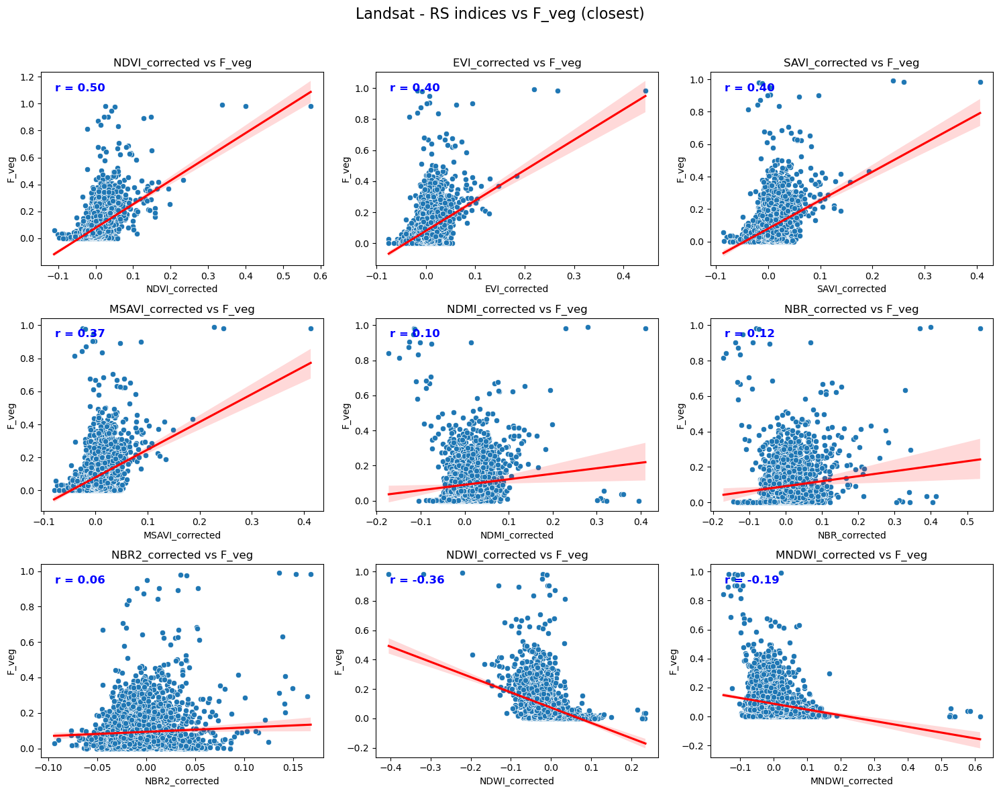

In [57]:
# merge_method = "mean" or "closest", accepted the 'mean' method!
merged_df2 = plot_field_vs_rs(field_df, rs_df=rs_corr_dfs[0], rs_indices=None, field_col='F_veg', satellite_name='Landsat', merge_method="closest")


=== Landsat ===
Correlation with F_alive:
F_alive            1.000000
NDVI_corrected     0.560856
EVI_corrected      0.552771
SAVI_corrected     0.527434
MSAVI_corrected    0.515296
NBR_corrected      0.419083
NDMI_corrected     0.390931
NBR2_corrected     0.146997
MNDWI_corrected   -0.049891
NDWI_corrected    -0.366911
Name: F_alive, dtype: float64
Plot saved to plots/Landsat_RS_vs_F_alive_mean.png


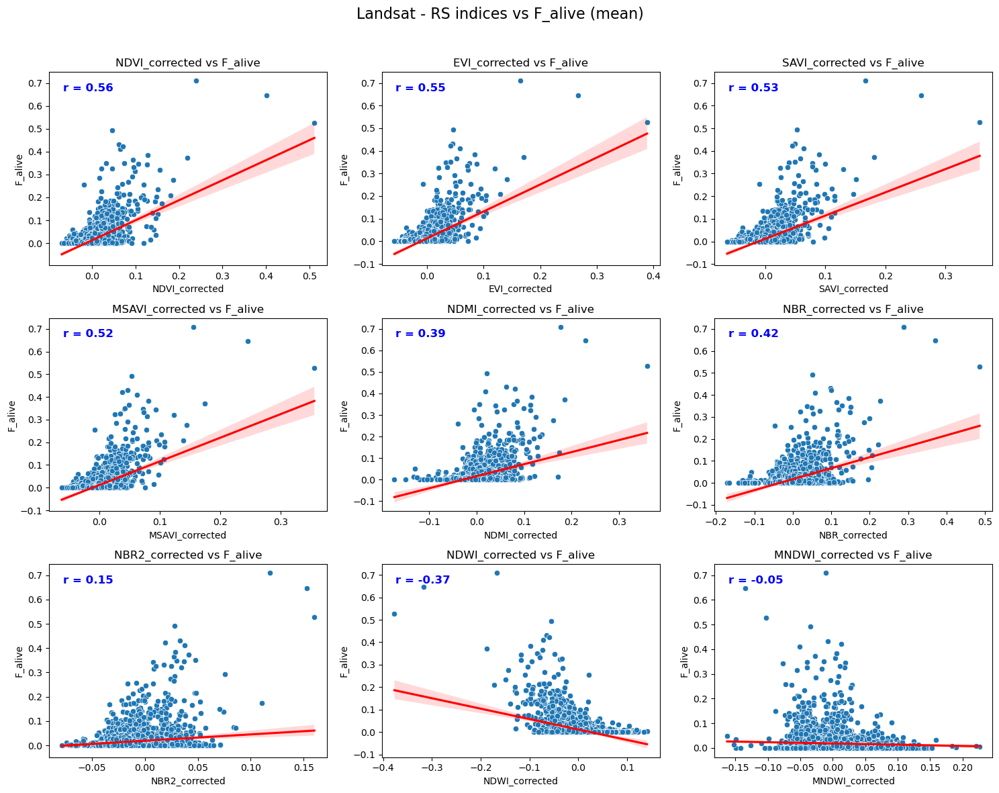

In [98]:
# merge_method = "mean" or "closest"
merged_df1 = plot_field_vs_rs(field_df, rs_df=rs_corr_dfs[0], rs_indices=None, field_col='F_alive', satellite_name='Landsat', merge_method="mean")


=== Sentinel-2 ===
Correlation with F_alive:
F_alive            1.000000
EVI_corrected      0.540809
SAVI_corrected     0.497311
NDVI_corrected     0.497301
MSAVI_corrected    0.485812
NBR_corrected      0.296685
NDMI_corrected     0.251933
NBR2_corrected     0.103211
MNDWI_corrected   -0.047629
NDWI_corrected    -0.251577
Name: F_alive, dtype: float64
Plot saved to plots/Sentinel-2_RS_vs_F_alive_mean.png


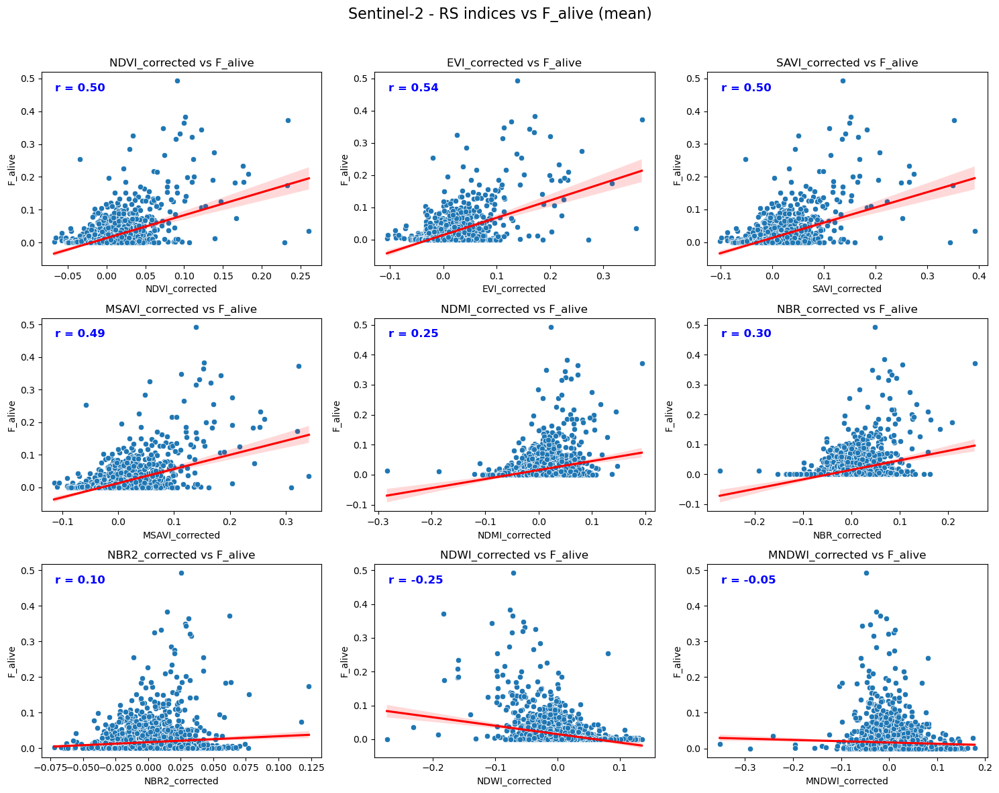

In [99]:
merged_df2 = plot_field_vs_rs(field_df, rs_df=rs_corr_dfs[1], rs_indices=None, field_col='F_alive', satellite_name='Sentinel-2', merge_method="mean")


=== MOD09A1 ===
Correlation with F_alive:
F_alive            1.000000
EVI_corrected      0.390309
NDVI_corrected     0.388997
SAVI_corrected     0.369447
MSAVI_corrected    0.357463
NBR2_corrected     0.273248
NBR_corrected      0.234360
NDMI_corrected     0.044403
MNDWI_corrected   -0.151006
NDWI_corrected    -0.238883
Name: F_alive, dtype: float64
Plot saved to plots/MOD09A1_RS_vs_F_alive_mean.png


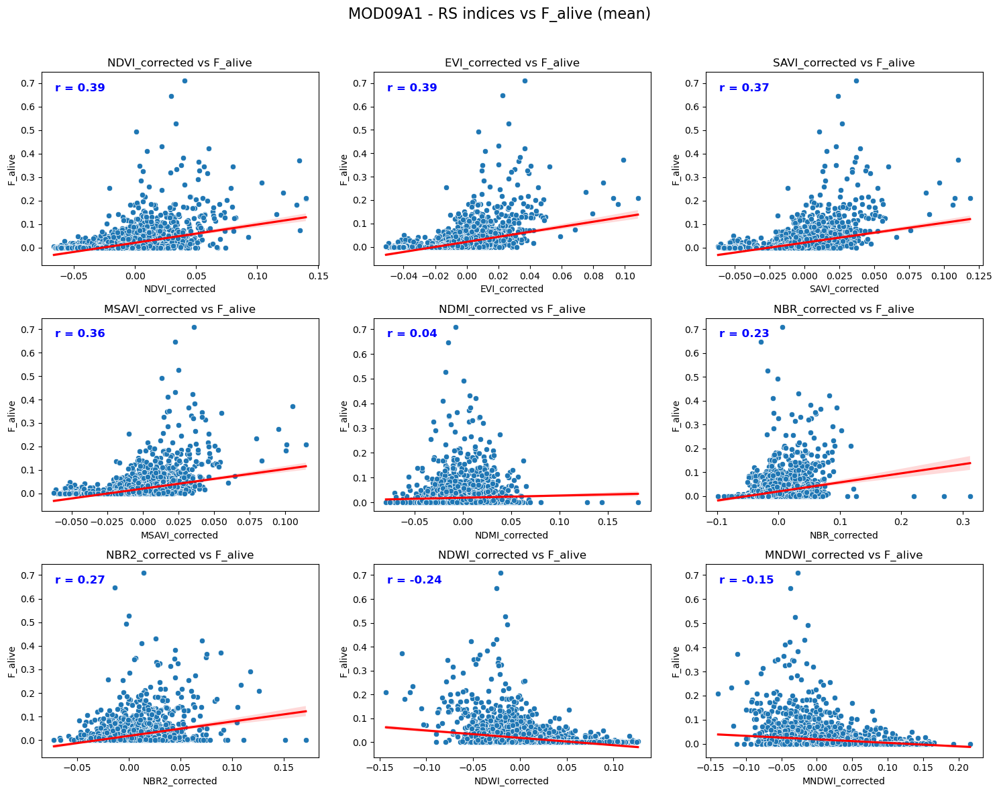

In [100]:
merged_df3 = plot_field_vs_rs(field_df, rs_df=rs_corr_dfs[2], rs_indices=None, field_col='F_alive', satellite_name='MOD09A1', merge_method="mean")


=== MOD13Q1 ===
Correlation with F_veg:
F_veg             1.000000
NDVI_corrected    0.474849
EVI_corrected     0.413436
Name: F_veg, dtype: float64


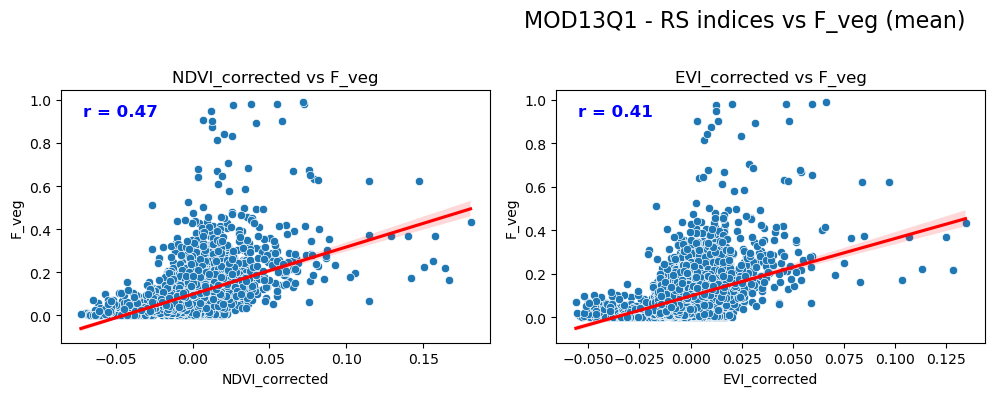

In [145]:
merged_df4 = plot_field_vs_rs(field_df, rs_df=rs_corr_dfs[3], rs_indices=None, field_col='F_veg', satellite_name='MOD13Q1', merge_method="mean")

In [151]:
merged_list = [merged_df1, merged_df2, merged_df3, merged_df4]
names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']

for df, name in zip(merged_list, names):
    df.to_csv(f'Corrected_Indices/{name}_corrected_merged.csv', index=False)

### Discarded old version


=== Landsat ===
Correlation with F_veg:
F_veg              1.000000
NDVI_corrected     0.509810
SAVI_corrected     0.418847
EVI_corrected      0.416711
MSAVI_corrected    0.385878
NBR_corrected      0.187103
NDMI_corrected     0.177891
NBR2_corrected     0.079388
MNDWI_corrected   -0.179569
NDWI_corrected    -0.390108
Name: F_veg, dtype: float64


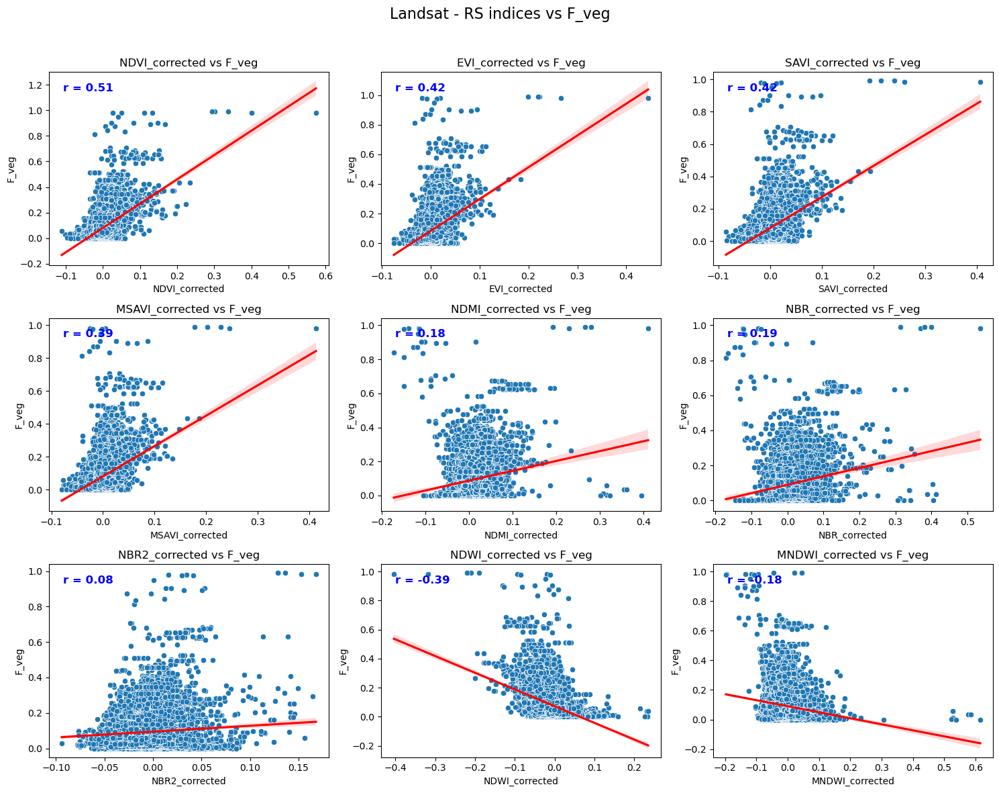

In [78]:
# discarded:
# merged_landsat = plot_field_vs_rs(field_df, rs_corr_dfs[0], field_col='F_veg', satellite_name='Landsat')


=== Sentinel-2 ===
Correlation with F_alive:
F_alive            1.000000
SAVI_corrected     0.425242
NDVI_corrected     0.425236
MSAVI_corrected    0.412147
EVI_corrected      0.406255
NBR_corrected      0.186185
NDMI_corrected     0.178990
NBR2_corrected     0.047548
MNDWI_corrected   -0.059682
NDWI_corrected    -0.215454
Name: F_alive, dtype: float64


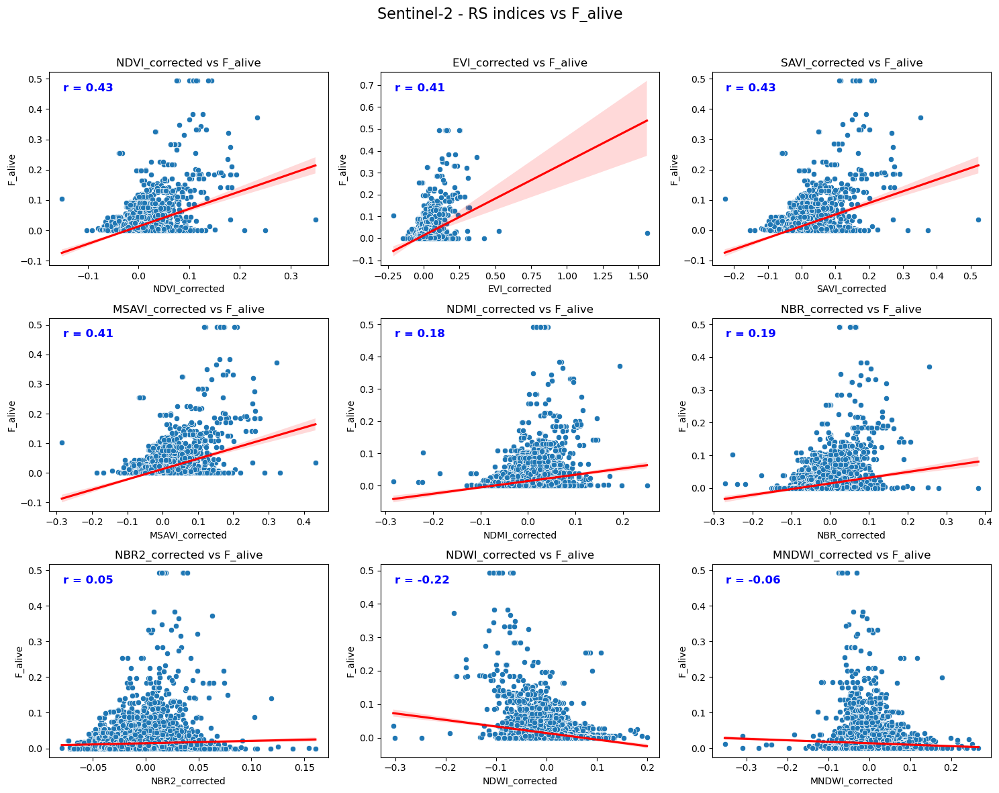

In [79]:
merged_sentinel = plot_field_vs_rs(field_df, rs_corr_dfs[1], field_col='F_alive', satellite_name='Sentinel-2')


=== MOD09A1 ===
Correlation with F_alive:
F_alive            1.000000
EVI_corrected      0.392036
NDVI_corrected     0.391122
SAVI_corrected     0.372493
MSAVI_corrected    0.359286
NBR_corrected      0.203760
NBR2_corrected     0.155312
NDMI_corrected     0.036866
MNDWI_corrected   -0.137703
NDWI_corrected    -0.238186
Name: F_alive, dtype: float64


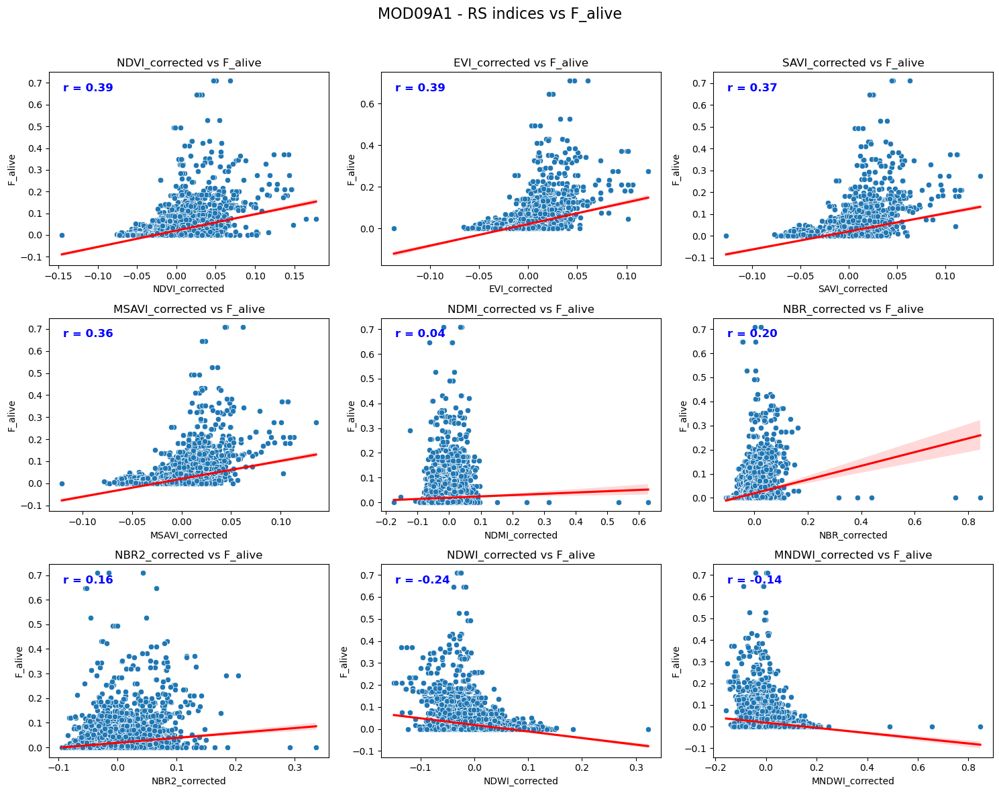

In [80]:
merged_mod09a1 = plot_field_vs_rs(field_df, rs_corr_dfs[2], field_col='F_alive', satellite_name='MOD09A1')


=== MOD13Q1 ===
Correlation with F_alive:
F_alive           1.000000
EVI_corrected     0.464863
NDVI_corrected    0.449339
Name: F_alive, dtype: float64


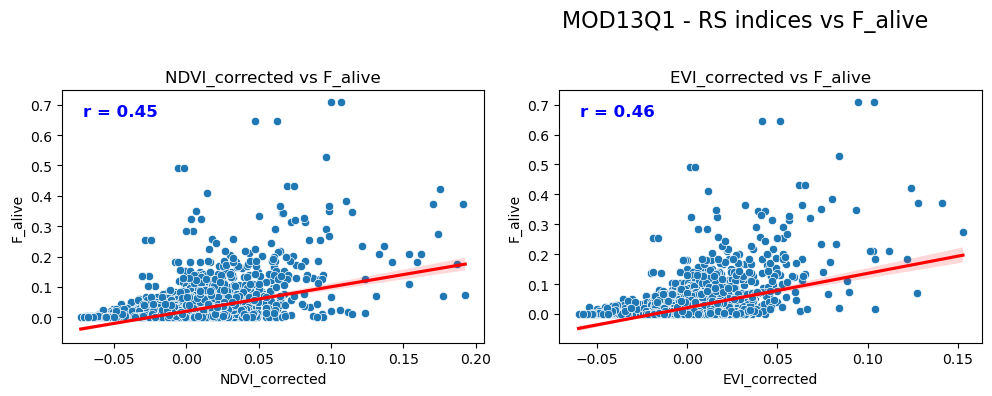

In [81]:
merged_mod13q1 = plot_field_vs_rs(field_df, rs_corr_dfs[3], field_col='F_alive', satellite_name='MOD13Q1')

In [82]:
Indices_list = ['NDVI', 'EVI', 'SAVI','MSAVI', 'NDMI', 'NBR', 'NBR2', 'NDWI', 'MNDWI']
Index_list = ['NDVI', 'EVI']


=== Landsat ===
Correlation with F_veg:
F_veg    1.000000
NDVI     0.528353
EVI      0.438862
SAVI     0.434762
MSAVI    0.400322
NBR      0.217298
NDMI     0.208174
NBR2     0.089716
MNDWI   -0.150525
NDWI    -0.375369
Name: F_veg, dtype: float64


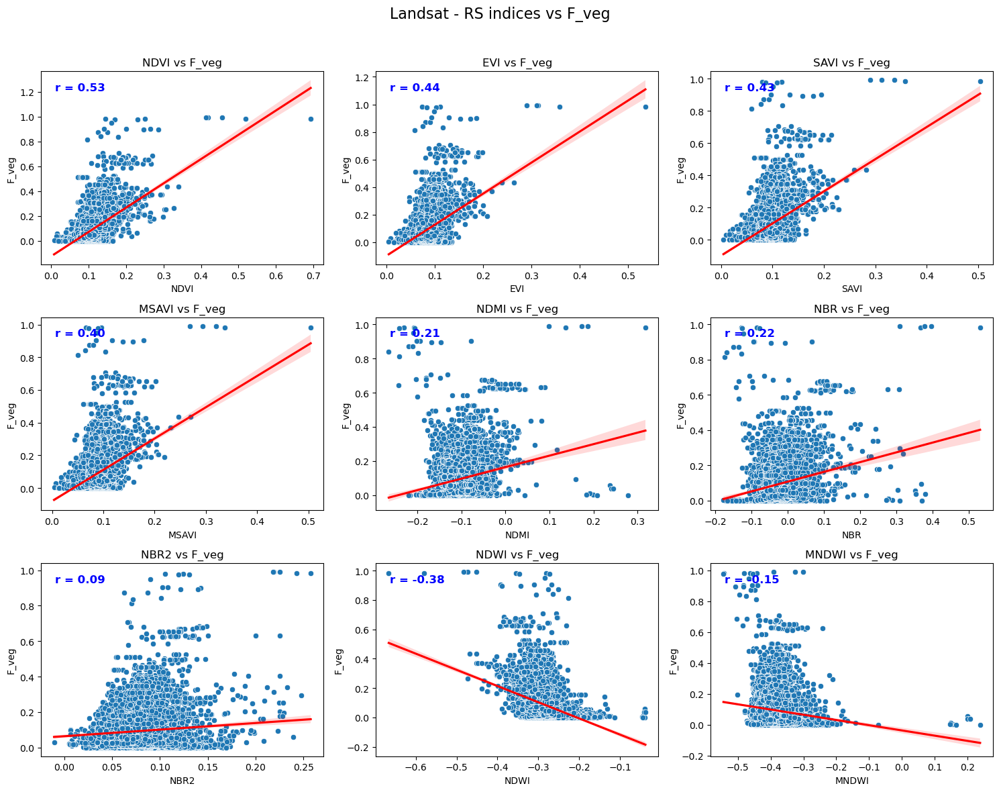

In [83]:
merged_landsat1 = plot_field_vs_rs(field_df, rs_corr_dfs[0], rs_indices=Indices_list, field_col='F_veg', satellite_name='Landsat')


=== Sentinel-2 ===
Correlation with F_veg:
F_veg    1.000000
NDVI     0.419801
SAVI     0.419788
MSAVI    0.412116
EVI      0.376927
NDMI    -0.001142
NBR2    -0.002271
NBR     -0.003309
MNDWI   -0.198032
NDWI    -0.282249
Name: F_veg, dtype: float64


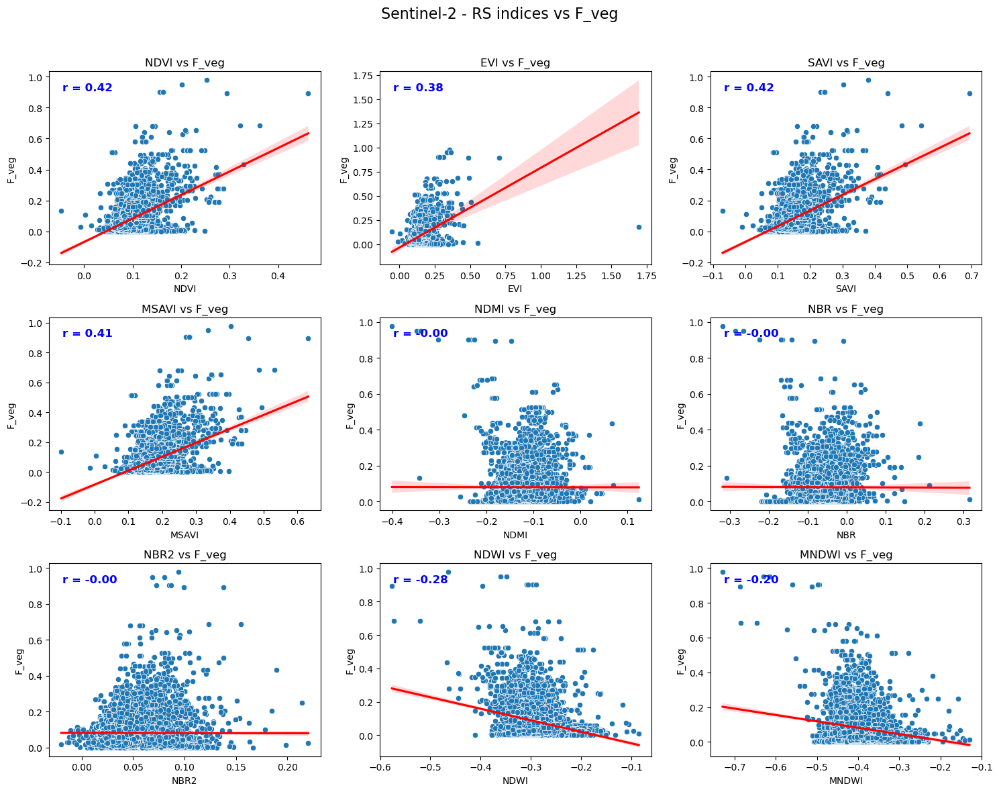

In [84]:
merged_sentinel1 = plot_field_vs_rs(field_df, rs_corr_dfs[1], rs_indices=Indices_list, field_col='F_veg', satellite_name='Sentinel-2')


=== MOD09A1 ===
Correlation with F_veg:
F_veg    1.000000
NDVI     0.396044
EVI      0.343863
SAVI     0.333284
MSAVI    0.306050
NBR2     0.133971
NBR      0.097992
NDMI    -0.047334
MNDWI   -0.197624
NDWI    -0.260018
Name: F_veg, dtype: float64


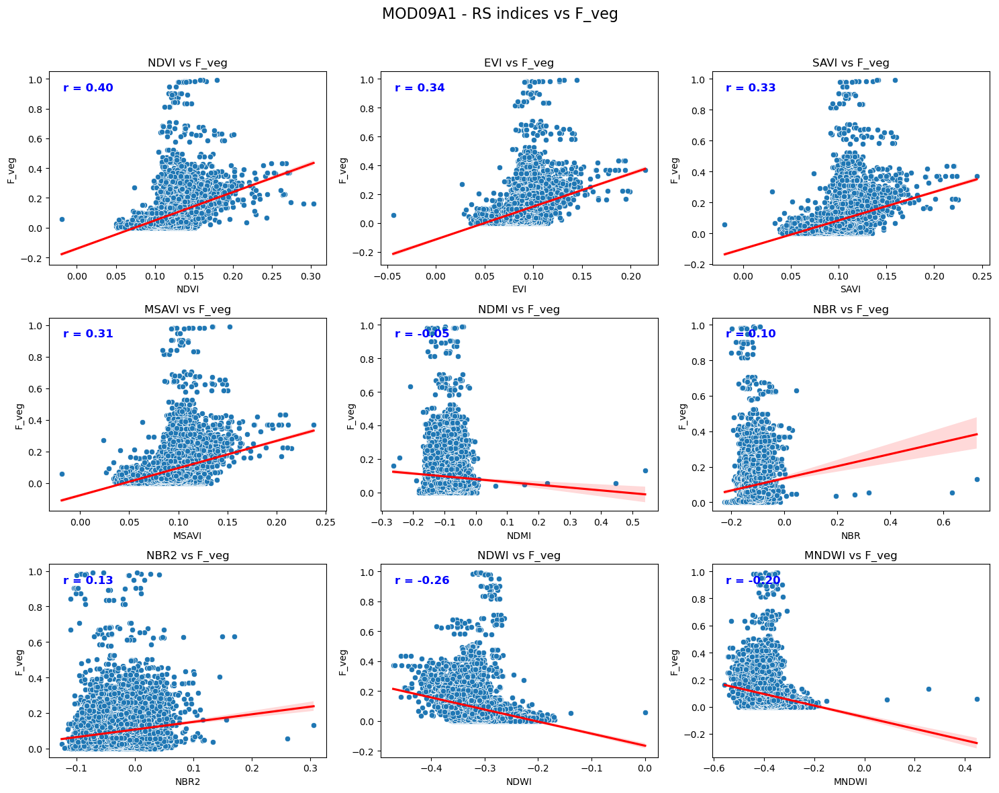

In [85]:
merged_mod09a11 = plot_field_vs_rs(field_df, rs_corr_dfs[2], rs_indices=Indices_list, field_col='F_veg', satellite_name='MOD09A1')


=== MOD13Q1 ===
Correlation with F_veg:
F_veg    1.000000
NDVI     0.450385
EVI      0.405580
Name: F_veg, dtype: float64


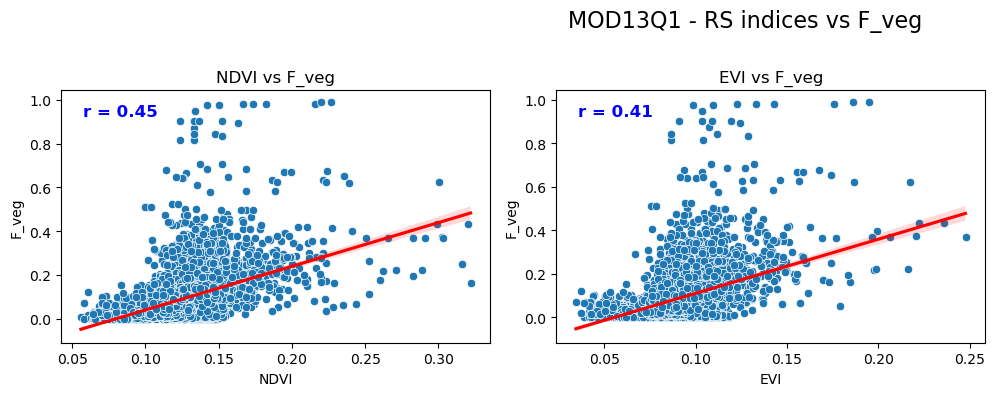

In [86]:
merged_mod13q11 = plot_field_vs_rs(field_df, rs_corr_dfs[3], rs_indices=Index_list, field_col='F_veg', satellite_name='MOD13Q1')

In [90]:
merged_list = [merged_landsat, merged_sentinel, merged_mod09a1, merged_mod13q1]
names = ['landsat10', 'sentinel2', 'mod09a1', 'mod13q1']

for df, name in zip(merged_list, names):
    df.to_csv(f'Corrected_Indices/{name}_corrected_merged.csv', index=False)

In [91]:
merged_list = [merged_landsat1, merged_sentinel1, merged_mod09a11, merged_mod13q11]
names = ['landsat', 'sentinel2', 'mod09a1', 'mod13q1']

for df, name in zip(merged_list, names):
    df.to_csv(f'Corrected_Indices/{name}_merged.csv', index=False)

## 2 Seasonal plot

In [58]:
names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']
merged_dfs1 = [pd.read_csv(f'Corrected_Indices/{name}_corrected_merged.csv') for name in names]

# Print sizes
for name, df in zip(names, merged_dfs1):
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

Landsat: 3300 rows × 26 columns
Sentinel2: 2510 rows × 26 columns
MOD09A1: 3536 rows × 26 columns
MOD13Q1: 3536 rows × 19 columns


In [150]:
# names = ['landsat', 'sentinel2', 'mod09a1', 'mod13q1']
# merged_dfs2 = [pd.read_csv(f'Corrected_Indices/{name}_merged.csv') for name in names]

# # Print sizes
# for name, df in zip(names, merged_dfs2):
#     print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

landsat: 10121 rows × 25 columns
sentinel2: 8518 rows × 25 columns
mod09a1: 8887 rows × 25 columns
mod13q1: 5297 rows × 18 columns


### Adopted version
- plot_seasonal_avg_per_year_dual_axis(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS')
- plot_seasonal_avg_per_habitat_dual_axis(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
import os

def seasonal_func(t, y0, amp, tau, phi):
    """Sinusoidal seasonal function."""
    return y0 + amp * np.sin(2 * np.pi * t / tau + phi)

def plot_seasonal_avg_per_year_dual_axis(
    merged_df, field_col='F_veg', rs_indices=None,
    satellite_name='RS', outdir='plots'
):
    """
    Plot seasonal averages per year for field vs RS indices with dual y-axis
    and export each figure as PNG (one per RS index).
    """
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]
    
    # Make sure output directory exists
    os.makedirs(outdir, exist_ok=True)
    
    # Compute seasonal mean per year
    season_order = ['Spring','Summer','Fall','Winter']
    merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)
    df_avg = merged_df.groupby(['Year','Season'])[[field_col]+rs_indices].mean().reset_index()
    
    # Convert season-year to approximate datetime
    season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}
    df_avg['datetime'] = pd.to_datetime(
        df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays)
    )
    
    # X data for fitting
    x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)
    y_field = df_avg[field_col].values
    
    # Fit field seasonal curve
    p0_field = [np.mean(y_field), (np.max(y_field)-np.min(y_field))/2, 365, 0]
    try:
        params_field, _ = optimize.curve_fit(seasonal_func, x_data, y_field, p0=p0_field)
    except Exception:
        params_field = [np.nan]*4
    
    # Loop over RS indices, plot and save separately
    for ind in rs_indices:
        fig, ax1 = plt.subplots(figsize=(10, 6))
        
        y_rs = df_avg[ind].values
        p0_rs = [np.mean(y_rs), (np.max(y_rs)-np.min(y_rs))/2, 365, 0]
        try:
            params_rs, _ = optimize.curve_fit(seasonal_func, x_data, y_rs, p0=p0_rs)
        except Exception:
            params_rs = [np.nan]*4
        
        # Left axis: field
        ax1.scatter(df_avg['datetime'], y_field, c='green', alpha=0.5, label=f'Field ({field_col})')
        if not np.isnan(params_field).any():
            ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field), c='green', lw=2.5, label='Field fit')
        ax1.set_ylabel(field_col, color='green')
        ax1.tick_params(axis='y', labelcolor='green')
        ax1.grid(lw=0.2)
        
        # Right axis: RS index
        ax2 = ax1.twinx()
        ax2.scatter(df_avg['datetime'], y_rs, c='orange', alpha=0.5, label=f'{satellite_name} ({ind})')
        if not np.isnan(params_rs).any():
            ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs), c='orange', lw=2.5, label='RS fit')
        ax2.set_ylabel(ind, color='orange')
        ax2.tick_params(axis='y', labelcolor='orange')
        
        # Correlation
        corr = np.corrcoef(y_field, y_rs)[0,1]
        ax1.set_title(f'{ind} vs {field_col} ({satellite_name}) | corr={corr:.2f}', fontsize=14)
        
        # Legends
        ax1.legend(loc='upper left', fontsize=10)
        ax2.legend(loc='upper right', fontsize=10)
        ax1.set_xlabel('Date')
        
        plt.tight_layout()
        
        # Save figure
        outfile = os.path.join(outdir, f"{satellite_name}_{ind}_vs_{field_col}.png")
        plt.savefig(outfile, dpi=300, bbox_inches='tight')
        plt.close(fig)  # close to avoid memory issues
        print(f"Saved figure to {outfile}")


In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

def seasonal_func(t, y0, amp, tau, phi):
    """Sinusoidal seasonal function."""
    return y0 + amp * np.sin(2 * np.pi * t / tau + phi)

def plot_seasonal_avg_per_year_dual_axis(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS'):
    """
    Plot seasonal averages per year for field vs RS indices with dual y-axis.
    """
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]
    
    # Compute seasonal mean per year
    season_order = ['Spring','Summer','Fall','Winter']
    merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)
    df_avg = merged_df.groupby(['Year','Season'])[[field_col]+rs_indices].mean().reset_index()
    
    # Convert season-year to approximate datetime
    season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}
    df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays))
    # df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str)+'-'+df_avg['Season'].map(season_middays))
    x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)
    y_field = df_avg[field_col].values
    
    n_indices = len(rs_indices)
    ncols = 2
    nrows = int(np.ceil(n_indices/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5*nrows), squeeze=False)
    
    # Fit field seasonal curve
    p0_field = [np.mean(y_field), (np.max(y_field)-np.min(y_field))/2, 365, 0]
    params_field, _ = optimize.curve_fit(seasonal_func, x_data, y_field, p0=p0_field)
    
    for i, ind in enumerate(rs_indices):
        row, col = divmod(i, ncols)
        ax1 = axes[row, col]
        y_rs = df_avg[ind].values
        p0_rs = [np.mean(y_rs), (np.max(y_rs)-np.min(y_rs))/2, 365, 0]
        try:
            params_rs, _ = optimize.curve_fit(seasonal_func, x_data, y_rs, p0=p0_rs)
        except:
            params_rs = [np.nan]*4
        
        # Left axis: field
        ax1.scatter(df_avg['datetime'], y_field, c='green', alpha=0.5, label=f'Field ({field_col})')
        ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field), c='green', lw=2.5, label='Field fit')
        ax1.set_ylabel(field_col, color='green')
        ax1.tick_params(axis='y', labelcolor='green')
        ax1.grid(lw=0.2)
        
        # Right axis: RS index
        ax2 = ax1.twinx()
        ax2.scatter(df_avg['datetime'], y_rs, c='orange', alpha=0.5, label=f'{satellite_name} ({ind})')
        ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs), c='orange', lw=2.5, label='RS fit')
        ax2.set_ylabel(ind, color='orange')
        ax2.tick_params(axis='y', labelcolor='orange')
        
        # Correlation
        corr = np.corrcoef(y_field, y_rs)[0,1]
        ax1.set_title(f'{ind} vs {field_col} (corr={corr:.2f})', fontsize=14)
        
        # Legends
        ax1.legend(loc='upper left', fontsize=10)
        ax2.legend(loc='upper right', fontsize=10)
        ax1.set_xlabel('Date')
    
    # Remove empty subplots
    total_subplots = nrows*ncols
    if total_subplots > n_indices:
        for j in range(n_indices, total_subplots):
            fig.delaxes(axes.flatten()[j])
    
    plt.tight_layout()
    plt.show()


# def plot_seasonal_avg_per_habitat_dual_axis(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS'):
#     """
#     Plot seasonal averages per year per habitat for field vs RS indices with dual y-axis.
#     """
#     if 'Habitat' not in merged_df.columns:
#         raise ValueError("merged_df must contain 'Habitat' column for this plot")
    
#     if rs_indices is None:
#         rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]
    
#     season_order = ['Spring','Summer','Fall','Winter']
#     merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)
#     habitats = merged_df['Habitat'].unique()
    
#     for hab in habitats:
#         df_hab = merged_df[merged_df['Habitat']==hab].copy()
#         df_avg = df_hab.groupby(['Year','Season'])[[field_col]+rs_indices].mean().reset_index()
#         season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}
#         df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays))
#         # df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str)+'-'+df_avg['Season'].map({'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}))
#         x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)
#         y_field = df_avg[field_col].values
        
#         n_indices = len(rs_indices)
#         ncols = 2
#         nrows = int(np.ceil(n_indices/ncols))
#         fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5*nrows), squeeze=False)
        
#         # Fit field seasonal curve
#         p0_field = [np.mean(y_field), (np.max(y_field)-np.min(y_field))/2, 365, 0]
#         params_field, _ = optimize.curve_fit(seasonal_func, x_data, y_field, p0=p0_field)
        
#         for i, ind in enumerate(rs_indices):
#             row, col = divmod(i, ncols)
#             ax1 = axes[row, col]
#             y_rs = df_avg[ind].values
#             p0_rs = [np.mean(y_rs), (np.max(y_rs)-np.min(y_rs))/2, 365, 0]
#             try:
#                 params_rs, _ = optimize.curve_fit(seasonal_func, x_data, y_rs, p0=p0_rs)
#             except:
#                 params_rs = [np.nan]*4
            
#             # Left axis: field
#             ax1.scatter(df_avg['datetime'], y_field, c='green', alpha=0.5, label=f'Field ({field_col})')
#             ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field), c='green', lw=2.5, label='Field fit')
#             ax1.set_ylabel(field_col, color='green')
#             ax1.tick_params(axis='y', labelcolor='green')
#             ax1.grid(lw=0.2)
            
#             # Right axis: RS index
#             ax2 = ax1.twinx()
#             ax2.scatter(df_avg['datetime'], y_rs, c='orange', alpha=0.5, label=f'{satellite_name} ({ind})')
#             ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs), c='orange', lw=2.5, label='RS fit')
#             ax2.set_ylabel(ind, color='orange')
#             ax2.tick_params(axis='y', labelcolor='orange')
            
#             # Correlation
#             corr = np.corrcoef(y_field, y_rs)[0,1]
#             ax1.set_title(f'{ind} vs {field_col} (corr={corr:.2f})', fontsize=14)
            
#             # Legends
#             ax1.legend(loc='upper left', fontsize=10)
#             ax2.legend(loc='upper right', fontsize=10)
#             ax1.set_xlabel('Date')
        
#         # Remove empty subplots
#         total_subplots = nrows*ncols
#         if total_subplots > n_indices:
#             for j in range(n_indices, total_subplots):
#                 fig.delaxes(axes.flatten()[j])
        
#         plt.suptitle(f'Habitat: {hab}', fontsize=16)
#         plt.tight_layout()
#         plt.show()


In [185]:
# Assuming merged_landsat is already created from previous step
rs_index_list = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
                 'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
                 'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']

sat_names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']

for df, sat in zip(merged_dfs1, sat_names):
    # select appropriate indices for MOD13Q1
    if sat == 'MOD13Q1':
        indices = ['NDVI_corrected', 'EVI_corrected']
    else:
        indices = rs_index_list
    # plot_seasonal_avg_per_year_dual_axis(df, field_col='F_veg', rs_indices=indices, satellite_name=sat)
    plot_seasonal_avg_per_year_dual_axis(df, field_col='F_veg', rs_indices=indices,satellite_name=sat, outdir='plots')
    # plot_seasonal_avg_per_habitat_dual_axis(df, field_col='F_veg', rs_indices=indices, satellite_name='RS')


Saved figure to plots\Landsat_NDVI_corrected_vs_F_veg.png
Saved figure to plots\Landsat_EVI_corrected_vs_F_veg.png
Saved figure to plots\Landsat_SAVI_corrected_vs_F_veg.png
Saved figure to plots\Landsat_MSAVI_corrected_vs_F_veg.png
Saved figure to plots\Landsat_NDMI_corrected_vs_F_veg.png
Saved figure to plots\Landsat_NBR_corrected_vs_F_veg.png
Saved figure to plots\Landsat_NBR2_corrected_vs_F_veg.png
Saved figure to plots\Landsat_NDWI_corrected_vs_F_veg.png
Saved figure to plots\Landsat_MNDWI_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_NDVI_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_EVI_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_SAVI_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_MSAVI_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_NDMI_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_NBR_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_NBR2_corrected_vs_F_veg.png
Saved figure to plots\Sentinel2_NDWI_corrected_vs_F_veg.png

In [186]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
import os

# --- Seasonal function for curve fitting ---
def seasonal_func(t, y0, amp, tau, phi):
    return y0 + amp * np.sin(2 * np.pi * t / tau + phi)

# --- Function 1: Correlation table ---
def correlation_table_per_habitat(merged_df, field_col='F_veg', rs_indices=None):
    if 'Habitat' not in merged_df.columns:
        raise ValueError("merged_df must contain 'Habitat' column")
    
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]
    
    habitats = merged_df['Habitat'].unique()
    table_list = []
    
    for hab in habitats:
        df_hab = merged_df[merged_df['Habitat']==hab]
        corr_dict = {'Habitat': hab}
        for ind in rs_indices:
            corr = df_hab[[field_col, ind]].corr().iloc[0,1]
            corr_dict[ind] = corr
        table_list.append(corr_dict)
    
    corr_df = pd.DataFrame(table_list)
    print("Correlation Table per Habitat:")
    print(corr_df)
    return corr_df

# --- Function 2: Plot seasonal dynamics with dual y-axis and save plots ---
def plot_seasonal_avg_per_habitat_dual_axis(
        merged_df, field_col='F_veg', rs_indices=None, 
        satellite_name='RS', outdir="plots"):
    """
    Plot seasonal averages per year with dual y-axis (Field vs RS indices)
    for each habitat, and export each figure as PNG.
    """
    if 'Habitat' not in merged_df.columns:
        raise ValueError("merged_df must contain 'Habitat' column for this plot")
    
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]
    
    # Ensure output folder exists
    os.makedirs(outdir, exist_ok=True)
    
    season_order = ['Spring','Summer','Fall','Winter']
    merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)
    habitats = merged_df['Habitat'].unique()
    season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}
    
    for hab in habitats:
        df_hab = merged_df[merged_df['Habitat']==hab].copy()
        df_avg = df_hab.groupby(['Year','Season'])[[field_col]+rs_indices].mean().reset_index()
        df_avg['datetime'] = pd.to_datetime(
            df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays)
        )
        
        x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)
        y_field = df_avg[field_col].astype(float).values
        
        # Filter invalid values
        mask_field = np.isfinite(x_data) & np.isfinite(y_field)
        x_field = x_data[mask_field]
        y_field_clean = y_field[mask_field]
        
        n_indices = len(rs_indices)
        ncols = 2
        nrows = int(np.ceil(n_indices/ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5*nrows), squeeze=False)
        
        # Try field seasonal fit
        params_field = [np.nan]*4
        if len(x_field) >= 4:
            p0_field = [np.nanmean(y_field_clean), (np.nanmax(y_field_clean)-np.nanmin(y_field_clean))/2, 365, 0]
            try:
                params_field, _ = optimize.curve_fit(seasonal_func, x_field, y_field_clean, p0=p0_field)
            except Exception as e:
                print(f"Curve fitting failed for Field in {hab}: {e}")
        
        for i, ind in enumerate(rs_indices):
            row, col = divmod(i, ncols)
            ax1 = axes[row, col]
            y_rs = df_avg[ind].astype(float).values
            
            # Filter invalid values for RS
            mask_rs = np.isfinite(x_data) & np.isfinite(y_rs)
            x_rs = x_data[mask_rs]
            y_rs_clean = y_rs[mask_rs]
            
            params_rs = [np.nan]*4
            if len(x_rs) >= 4:
                p0_rs = [np.nanmean(y_rs_clean), (np.nanmax(y_rs_clean)-np.nanmin(y_rs_clean))/2, 365, 0]
                try:
                    params_rs, _ = optimize.curve_fit(seasonal_func, x_rs, y_rs_clean, p0=p0_rs)
                except Exception as e:
                    print(f"Curve fitting failed for RS ({ind}) in {hab}: {e}")
            
            # Plot Field
            ax1.scatter(df_avg['datetime'], y_field, c='green', alpha=0.5, label=f'Field ({field_col})')
            if np.all(np.isfinite(params_field)):
                ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field), c='green', lw=2.5, label='Field fit')
            ax1.set_ylabel(field_col, color='green')
            ax1.tick_params(axis='y', labelcolor='green')
            ax1.grid(lw=0.2)
            
            # Plot RS
            ax2 = ax1.twinx()
            ax2.scatter(df_avg['datetime'], y_rs, c='orange', alpha=0.5, label=f'{satellite_name} ({ind})')
            if np.all(np.isfinite(params_rs)):
                ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs), c='orange', lw=2.5, label='RS fit')
            ax2.set_ylabel(ind, color='orange')
            ax2.tick_params(axis='y', labelcolor='orange')
            
            # Correlation
            corr = np.corrcoef(y_field_clean, y_rs_clean)[0,1] if (len(y_field_clean)>1 and len(y_rs_clean)>1) else np.nan
            ax1.set_title(f'{ind} vs {field_col} (corr={corr:.2f})', fontsize=14)
            
            # Legends
            ax1.legend(loc='upper left', fontsize=10)
            ax2.legend(loc='upper right', fontsize=10)
            ax1.set_xlabel('Date')
        
        # Remove empty subplots
        total_subplots = nrows*ncols
        if total_subplots > n_indices:
            for j in range(n_indices, total_subplots):
                fig.delaxes(axes.flatten()[j])
        
        plt.suptitle(f'Habitat: {hab}', fontsize=16)
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        
        # --- Save plot ---
        outfile = os.path.join(outdir, f"{satellite_name}_{hab}_dual_axis.png")
        plt.savefig(outfile, dpi=300, bbox_inches='tight')
        plt.close(fig)
        print(f"Saved figure for habitat {hab} to {outfile}")


In [187]:
# Assuming merged_landsat is already created from previous step
rs_index_list = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
                 'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
                 'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']

sat_names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']

for df, sat in zip(merged_dfs1, sat_names):
    # select appropriate indices for MOD13Q1
    if sat == 'MOD13Q1':
        indices = ['NDVI_corrected', 'EVI_corrected']
    else:
        indices = rs_index_list
    # plot_seasonal_avg_per_year_dual_axis(df, field_col='F_veg', rs_indices=indices, satellite_name=sat)
    # plot_seasonal_avg_per_habitat_dual_axis(df, field_col='F_veg', rs_indices=indices, satellite_name=sat)
    
    # 1. Print correlation table
    corr_df = correlation_table_per_habitat(df, field_col='F_veg')
    # 2. Plot seasonal dual-axis curves
    # plot_seasonal_avg_per_habitat_dual_axis(df, field_col='F_veg')
    plot_seasonal_avg_per_habitat_dual_axis(df, field_col='F_veg', rs_indices=None, satellite_name=sat, outdir="plots")


Correlation Table per Habitat:
                Habitat  NDVI_corrected  EVI_corrected  SAVI_corrected  \
0     Macrochloa steppe        0.386146       0.249106        0.271095   
1                 Gully        0.573812       0.618119        0.616047   
2                   Reg        0.542808       0.429817        0.402777   
3  Alluvial spread area        0.636949       0.602661        0.600228   
4                  Wadi       -0.247067      -0.198597       -0.182357   
5          Salty steppe        0.551293       0.394240        0.435271   

   MSAVI_corrected  NDMI_corrected  NBR_corrected  NBR2_corrected  \
0         0.222042        0.559109       0.052403       -0.472070   
1         0.626499       -0.139590       0.277157        0.497785   
2         0.364812       -0.037865      -0.012849        0.046259   
3         0.575911        0.443850       0.515733        0.417232   
4        -0.152140        0.068023      -0.095609       -0.261944   
5         0.360669        0.068190  

In [189]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
import seaborn as sns
import os

# Seasonal sine function
def seasonal_func(t, y0, amp, tau, phi):
    return y0 + amp * np.sin(2 * np.pi * t / tau + phi)

def plot_seasonal_avg_all_habitats_dual_axis(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS', outdir='plots'):
    """
    Plot seasonal averages per year for all habitats in one figure, with dual y-axes.
    Each subplot corresponds to one RS index; different habitats are color-coded.
    Figures are saved as PNG in `outdir`.
    """

    if 'Habitat' not in merged_df.columns:
        raise ValueError("merged_df must contain 'Habitat' column")

    # Default RS indices
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]

    # Ensure seasons are ordered
    season_order = ['Spring','Summer','Fall','Winter']
    merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)

    habitats = merged_df['Habitat'].unique()
    season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}

    # Create output directory
    os.makedirs(outdir, exist_ok=True)

    # Qualitative palette for distinct habitats
    palette = sns.color_palette("tab20", len(habitats))
    habitat_colors = dict(zip(habitats, palette))

    n_indices = len(rs_indices)
    ncols = 2
    nrows = int(np.ceil(n_indices / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5*nrows), squeeze=False)

    for i, ind in enumerate(rs_indices):
        row, col = divmod(i, ncols)
        ax1 = axes[row, col]
        ax2 = ax1.twinx()

        for hab in habitats:
            df_hab = merged_df[merged_df['Habitat']==hab].copy()
            df_avg = df_hab.groupby(['Year','Season'])[[field_col, ind]].mean().reset_index()

            # Build datetime from Year + Season midpoint
            df_avg['datetime'] = pd.to_datetime(
                df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays)
            )
            x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)

            # ==== FIELD DATA ====
            y_field = df_avg[field_col].values.astype(float)
            mask_field = np.isfinite(x_data) & np.isfinite(y_field)
            x_fit, y_fit = x_data[mask_field], y_field[mask_field]
            params_field = [np.nan]*4
            if len(x_fit) >= 4:
                p0_field = [np.nanmean(y_fit), (np.nanmax(y_fit)-np.nanmin(y_fit))/2, 365, 0]
                try:
                    params_field, _ = optimize.curve_fit(seasonal_func, x_fit, y_fit, p0=p0_field)
                except RuntimeError:
                    print(f"Curve fitting failed for Field in {hab}-{ind}")

            ax1.scatter(df_avg['datetime'], y_field, color=habitat_colors[hab], alpha=0.4, marker='o')
            if np.all(np.isfinite(params_field)):
                ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field),
                         color=habitat_colors[hab], lw=2.0, linestyle='-',
                         label=f'{hab} Field')

            # ==== RS DATA ====
            y_rs = df_avg[ind].values.astype(float)
            mask_rs = np.isfinite(x_data) & np.isfinite(y_rs)
            x_fit_rs, y_fit_rs = x_data[mask_rs], y_rs[mask_rs]
            params_rs = [np.nan]*4
            if len(x_fit_rs) >= 4:
                p0_rs = [np.nanmean(y_fit_rs), (np.nanmax(y_fit_rs)-np.nanmin(y_fit_rs))/2, 365, 0]
                try:
                    params_rs, _ = optimize.curve_fit(seasonal_func, x_fit_rs, y_fit_rs, p0=p0_rs)
                except RuntimeError:
                    print(f"Curve fitting failed for RS in {hab}-{ind}")

            ax2.scatter(df_avg['datetime'], y_rs, color=habitat_colors[hab], alpha=0.4, marker='x')
            if np.all(np.isfinite(params_rs)):
                ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs),
                         color=habitat_colors[hab], lw=2.0, linestyle='--',
                         label=f'{hab} {satellite_name}')

        # Axis formatting
        ax1.set_ylabel(field_col, color='green')
        ax2.set_ylabel(ind, color='orange')
        ax1.tick_params(axis='y', labelcolor='green')
        ax2.tick_params(axis='y', labelcolor='orange')
        ax1.set_xlabel('Date')
        ax1.set_title(f'{ind} vs {field_col}', fontsize=14)
        ax1.grid(lw=0.2)

        # Combine legends
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

    # Remove unused axes
    total_subplots = nrows*ncols
    if total_subplots > n_indices:
        for j in range(n_indices, total_subplots):
            fig.delaxes(axes.flatten()[j])

    plt.suptitle(f'Seasonal Averages per Habitat - {satellite_name}', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # --- Save figure ---
    outfile = os.path.join(outdir, f"{satellite_name}_all_habitats_dual_axis.png")
    plt.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved combined seasonal figure for all habitats to {outfile}")


In [190]:
# Assuming merged_landsat is already created from previous step
rs_index_list = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
                 'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
                 'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']

sat_names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']

for df, sat in zip(merged_dfs1, sat_names):
    # select appropriate indices for MOD13Q1
    if sat == 'MOD13Q1':
        indices = ['NDVI_corrected', 'EVI_corrected']
    else:
        indices = rs_index_list
    plot_seasonal_avg_all_habitats_dual_axis(df, field_col='F_veg', rs_indices=None, satellite_name=sat, outdir='plots')

# plot_seasonal_avg_all_habitats_dual_axis(merged_dfs1[0], field_col='F_veg', rs_indices=None, satellite_name='Landsat')


✅ Saved combined seasonal figure for all habitats to plots\Landsat_all_habitats_dual_axis.png
✅ Saved combined seasonal figure for all habitats to plots\Sentinel2_all_habitats_dual_axis.png
✅ Saved combined seasonal figure for all habitats to plots\MOD09A1_all_habitats_dual_axis.png
✅ Saved combined seasonal figure for all habitats to plots\MOD13Q1_all_habitats_dual_axis.png


### Discarded plot functions
- plot_seasonal_by_habitat(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS', split_habitat=True)
- plot_seasonal_field_rs(merged_df, field_col, rs_indices, satellite_name, habitat_split=True)
- plot_seasonal_field_rs_dual(merged_df, field_col, rs_indices, satellite_name, habitat_split=True)

In [ ]:
names = ['Landsat', 'Sentinel-2', 'MOD09A1', 'MOD13Q1']
merged_dfs1 = [pd.read_csv(f'Corrected_Indices/{name}_corrected_merged.csv') for name in names]

# Print sizes
for name, df in zip(names, merged_dfs1):
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

In [ ]:
# Landsat merged dataframe
rs_index_list = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
                 'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
                 'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']

In [ ]:
plot_seasonal_field_rs(merged_dfs1[0], field_col='F_veg', rs_indices=rs_index_list, satellite_name='Landsat')
plot_seasonal_by_habitat(merged_dfs1[0], field_col='F_veg', rs_indices=rs_index_list, satellite_name='Landsat', split_habitat=True)
plot_seasonal_field_rs_dual(merged_dfs1[0], field_col='F_veg', rs_indices=rs_index_list, satellite_name='Landsat')

In [101]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize
import pandas as pd

def plot_seasonal_by_habitat(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS', split_habitat=True):
    """
    Plot seasonal field metric vs RS indices by Year+Season and optionally by Habitat type.
    
    Parameters:
        merged_df : pd.DataFrame
            Merged DataFrame with field + RS indices + 'Year', 'Season', 'Habitat'.
        field_col : str
            Field metric to plot ('F_veg' or 'F_alive').
        rs_indices : list of str
            RS indices to plot. If None, use all *_corrected columns.
        satellite_name : str
            Satellite/dataset name for titles.
        split_habitat : bool
            If True, create separate plots/colors per Habitat type.
    """
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]

    habitats = merged_df['Habitat'].unique() if split_habitat else [None]
    
    # Create a numeric x-axis representing year + season order
    season_order = {'Spring': 1, 'Summer': 2, 'Fall': 3, 'Winter': 4}
    merged_df['Season_order'] = merged_df['Season'].map(season_order)
    merged_df['Year_Season'] = merged_df['Year'] + (merged_df['Season_order'] - 1)/4
    
    n_indices = len(rs_indices)
    ncols = 2
    nrows = int(np.ceil(n_indices / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5*nrows), squeeze=False)
    
    for i, ind in enumerate(rs_indices):
        row, col = divmod(i, ncols)
        ax = axes[row, col]
        
        for hab in habitats:
            if hab is not None:
                df_plot = merged_df[merged_df['Habitat'] == hab]
                label_suffix = f' ({hab})'
            else:
                df_plot = merged_df
                label_suffix = ''
            
            # Scatter
            ax.scatter(df_plot['Year_Season'], df_plot[field_col], alpha=0.5, label=f'Field {label_suffix}', c='green')
            ax.scatter(df_plot['Year_Season'], df_plot[ind], alpha=0.5, label=f'{satellite_name} {label_suffix}', c='orange')
            
            # Fit sinusoidal seasonal curve
            x = df_plot['Year_Season'].values * 365  # approximate day of year
            y_field = df_plot[field_col].values
            y_rs = df_plot[ind].values
            
            def seasonal_func(t, y0, amp, tau, phi):
                return y0 + amp * np.sin(2*np.pi*t/tau + phi)
            
            try:
                p_field, _ = optimize.curve_fit(seasonal_func, x, y_field, p0=[np.mean(y_field), (np.max(y_field)-np.min(y_field))/2, 365, 0])
                ax.plot(df_plot['Year_Season'], seasonal_func(x, *p_field), c='green', lw=2)
            except:
                pass
            
            try:
                p_rs, _ = optimize.curve_fit(seasonal_func, x, y_rs, p0=[np.mean(y_rs), (np.max(y_rs)-np.min(y_rs))/2, 365, 0])
                ax.plot(df_plot['Year_Season'], seasonal_func(x, *p_rs), c='orange', lw=2)
            except:
                pass
            
            # Correlation
            if len(y_field) > 1 and len(y_rs) > 1:
                corr = np.corrcoef(y_field, y_rs)[0,1]
            else:
                corr = np.nan
        
        ax.set_title(f'{ind} vs {field_col} (corr={corr:.2f})', fontsize=14)
        ax.set_xlabel('Year + Season')
        ax.set_ylabel('Value')
        ax.grid(lw=0.2)
        ax.legend(fontsize=9)
    
    # Remove empty subplots
    total_subplots = nrows * ncols
    if total_subplots > n_indices:
        for j in range(n_indices, total_subplots):
            fig.delaxes(axes.flatten()[j])
    
    plt.tight_layout()
    plt.show()

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from statsmodels.nonparametric.smoothers_lowess import lowess

def plot_seasonal_field_rs(merged_df, field_col, rs_indices, satellite_name, habitat_split=True):
    """
    Plot seasonal trends (field vs RS metrics) by year and season.
    """
    # Ensure numeric seasonal ordering (approximate mid-DOY for each season)
    season_to_doy = {"Spring": 120, "Summer": 180, "Fall": 280, "Winter": 340}
    merged_df = merged_df.copy()
    merged_df["DOY"] = merged_df["Season"].map(season_to_doy)
    merged_df["time"] = merged_df["Year"] * 365 + merged_df["DOY"]  # numeric timeline

    habitats = merged_df["Habitat"].unique() if habitat_split else ["All"]

    for ind in rs_indices:
        if ind not in merged_df.columns:
            print(f"⚠️ {ind} not found in dataframe.")
            continue

        fig, axes = plt.subplots(
            nrows=len(habitats), ncols=1, figsize=(12, 4 * len(habitats)), sharex=True
        )

        if len(habitats) == 1:
            axes = [axes]  # make iterable

        for ax, hab in zip(axes, habitats):
            df_plot = merged_df if hab == "All" else merged_df[merged_df["Habitat"] == hab]

            # Raw scatter
            ax.scatter(df_plot["time"], df_plot[field_col], alpha=0.4, c="green", label=f"Field {field_col}")
            ax.scatter(df_plot["time"], df_plot[ind], alpha=0.4, c="orange", label=f"{satellite_name} {ind}")

            # Smoothed curves (LOWESS)
            if len(df_plot) > 5:
                smooth_field = lowess(df_plot[field_col], df_plot["time"], frac=0.3)
                smooth_rs = lowess(df_plot[ind], df_plot["time"], frac=0.3)
                ax.plot(smooth_field[:,0], smooth_field[:,1], color="green", lw=2.5)
                ax.plot(smooth_rs[:,0], smooth_rs[:,1], color="orange", lw=2.5)

            ax.set_title(f"{satellite_name} {ind} vs {field_col} – {hab}")
            ax.set_ylabel("Value")
            ax.legend(loc="best")
            ax.grid(alpha=0.3)

        axes[-1].set_xlabel("Year + Season (time)")
        plt.tight_layout()
        plt.show()

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from statsmodels.nonparametric.smoothers_lowess import lowess

def plot_seasonal_field_rs_dual(merged_df, field_col, rs_indices, satellite_name, habitat_split=True):
    """
    Plot seasonal developments (field vs RS metrics) by Year and Season on dual y-axes.
    
    Parameters
    ----------
    merged_df : DataFrame
        Merged dataframe containing field data, RS indices, Year, Season, Habitat
    field_col : str
        Column in field_df to compare (e.g., 'F_veg' or 'F_alive')
    rs_indices : list
        List of RS index column names to compare
    satellite_name : str
        Name of satellite for labeling
    habitat_split : bool
        If True, separate plots by habitat type
    """

    # Copy to avoid modifying original
    merged_df = merged_df.copy()
    merged_df["Year_Season"] = merged_df["Year"].astype(str) + "_" + merged_df["Season"].astype(str)

    # Ensure ordering of seasons
    season_order = ["Spring", "Summer", "Fall", "Winter"]
    merged_df["Season"] = pd.Categorical(merged_df["Season"], categories=season_order, ordered=True)
    merged_df = merged_df.sort_values(["Year", "Season"])

    # X-axis order
    year_season_order = merged_df["Year_Season"].unique()
    
    # Habitats
    habitats = merged_df["Habitat"].unique() if habitat_split else ["All"]

    for ind in rs_indices:
        if ind not in merged_df.columns:
            print(f"⚠️ {ind} not found in dataframe.")
            continue

        fig, axes = plt.subplots(
            nrows=len(habitats), ncols=1, figsize=(14, 4 * len(habitats)), sharex=True
        )
        if len(habitats) == 1:
            axes = [axes]  # make iterable

        for ax, hab in zip(axes, habitats):
            df_plot = merged_df if hab == "All" else merged_df[merged_df["Habitat"] == hab]

            # Create dual y-axis
            ax2 = ax.twinx()

            # Scatter plots
            ax.scatter(df_plot["Year_Season"], df_plot[field_col], alpha=0.5, c="green", label=f"Field {field_col}")
            ax2.scatter(df_plot["Year_Season"], df_plot[ind], alpha=0.5, c="orange", label=f"{satellite_name} {ind}")

            # Smoothed curves
            if len(df_plot) > 5:
                x_numeric = np.arange(len(df_plot["Year_Season"]))
                smooth_field = lowess(df_plot[field_col], x_numeric, frac=0.3)
                smooth_rs = lowess(df_plot[ind], x_numeric, frac=0.3)

                ax.plot(df_plot["Year_Season"].iloc[smooth_field[:,0].astype(int)], 
                        smooth_field[:,1], color="green", lw=2.5)
                ax2.plot(df_plot["Year_Season"].iloc[smooth_rs[:,0].astype(int)], 
                         smooth_rs[:,1], color="orange", lw=2.5)

            # Titles and labels
            ax.set_title(f"{satellite_name} {ind} vs {field_col} – {hab}")
            ax.set_ylabel(f"{field_col} (Field)", color="green")
            ax2.set_ylabel(f"{ind} ({satellite_name})", color="orange")
            ax.grid(alpha=0.3)

        axes[-1].set_xlabel("Year and Season")
        plt.setp(axes[-1].get_xticklabels(), rotation=45, ha="right")

        plt.tight_layout()
        plt.show()

## 3 Random forest analysis

In [59]:
# Field data
local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
local_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'
field_fp = local_foler + local_fp
df = pd.read_csv(field_fp)
print(f"The shape of this {field_fp} is {df.shape}.")

The shape of this C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/Trophic survey data analysis_all_2016-2023_habitat.csv is (3536, 16).


In [60]:
# used the previous steps generated merged dfs
names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']
merged_dfs1 = [pd.read_csv(f'Corrected_Indices/{name}_corrected_merged.csv') for name in names]

# Print sizes
for name, df in zip(names, merged_dfs1):
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

Landsat: 3300 rows × 26 columns
Sentinel2: 2510 rows × 26 columns
MOD09A1: 3536 rows × 26 columns
MOD13Q1: 3536 rows × 19 columns



Random Forest performance metrics (Landsat):
R2_train: 0.908
R2_test: 0.504
RMSE_train: 0.012
RMSE_test: 0.038

Feature importance ranking:
             Index  Importance
0   SAVI_corrected    0.227943
1   NDVI_corrected    0.140819
2  MSAVI_corrected    0.122786
3   NDMI_corrected    0.102244
4   NBR2_corrected    0.098049
5    EVI_corrected    0.090254
6  MNDWI_corrected    0.078223
7   NDWI_corrected    0.073715
8    NBR_corrected    0.065967


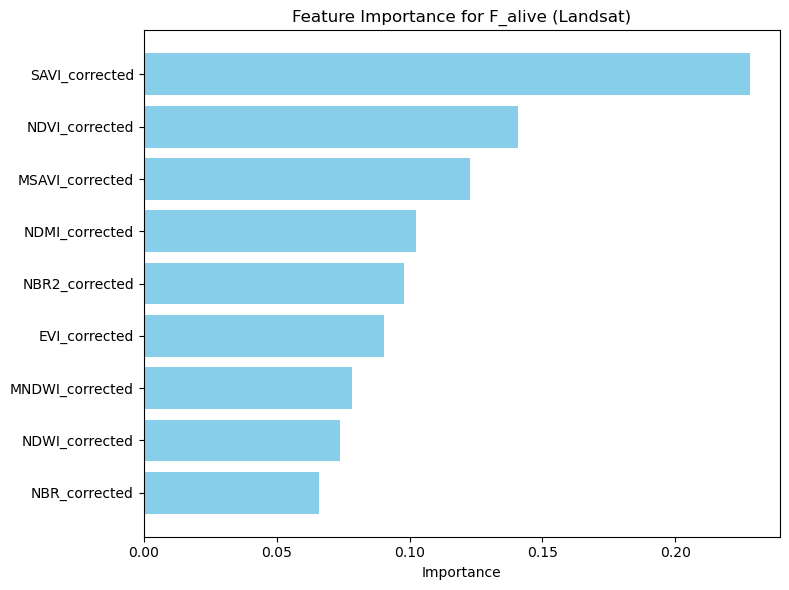


Random Forest performance metrics (Sentinel2):
R2_train: 0.920
R2_test: 0.422
RMSE_train: 0.010
RMSE_test: 0.032

Feature importance ranking:
             Index  Importance
0    EVI_corrected    0.389476
1   NBR2_corrected    0.121812
2   NDMI_corrected    0.103123
3  MNDWI_corrected    0.083516
4    NBR_corrected    0.079026
5  MSAVI_corrected    0.064262
6   NDWI_corrected    0.059922
7   SAVI_corrected    0.052107
8   NDVI_corrected    0.046757


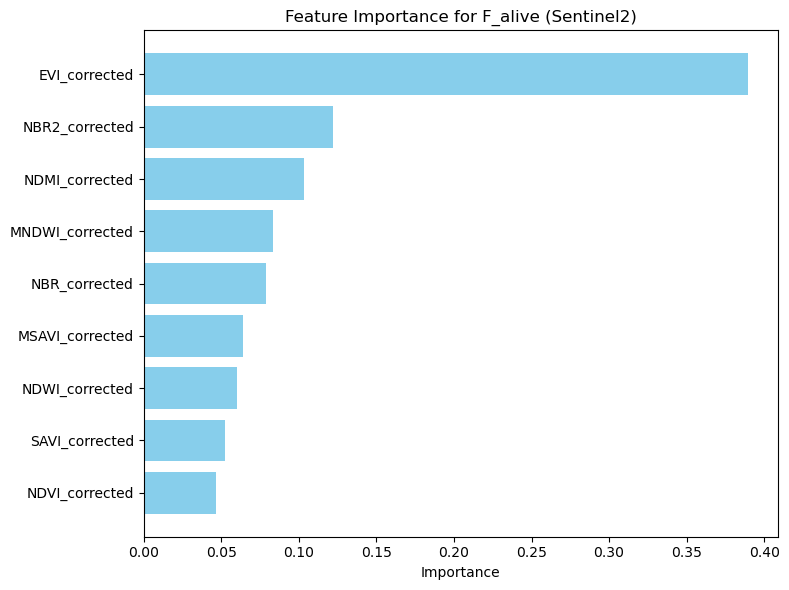


Random Forest performance metrics (MOD09A1):
R2_train: 0.915
R2_test: 0.242
RMSE_train: 0.013
RMSE_test: 0.037

Feature importance ranking:
             Index  Importance
0    NBR_corrected    0.235827
1    EVI_corrected    0.177339
2  MSAVI_corrected    0.160451
3   SAVI_corrected    0.146779
4   NDVI_corrected    0.071727
5   NDMI_corrected    0.058313
6   NBR2_corrected    0.058064
7   NDWI_corrected    0.050625
8  MNDWI_corrected    0.040874


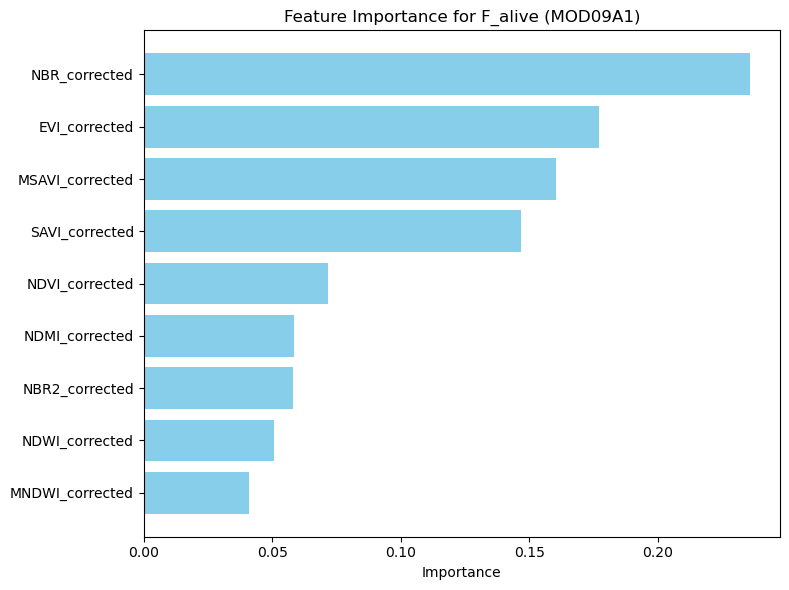


Random Forest performance metrics (MOD13Q1):
R2_train: 0.896
R2_test: 0.378
RMSE_train: 0.014
RMSE_test: 0.034

Feature importance ranking:
            Index  Importance
0   EVI_corrected    0.697091
1  NDVI_corrected    0.302909


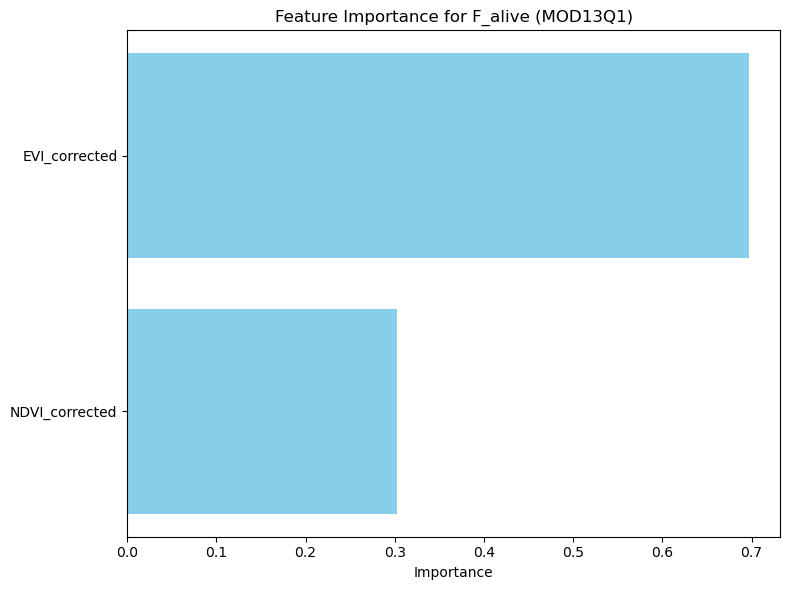

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

def rf_index_importance(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS',
                        test_size=0.3, random_state=42, n_estimators=500, plot=True, verbose=True):
    """
    Train a Random Forest to identify the most important RS indices 
    for predicting the seasonal field variable (e.g., F_veg).

    Parameters
    ----------
    merged_df : pd.DataFrame
        Data containing 'Habitat', 'Year', 'Season', RS indices, and field variable.
    field_col : str
        Name of the field variable column (target).
    rs_indices : list
        List of RS index columns. If None, will auto-detect columns ending in '_corrected'.
    satellite_name : str
        Name of the satellite, used for labeling plot and output.
    test_size : float
        Fraction of data for testing.
    random_state : int
        Random seed.
    n_estimators : int
        Number of trees in the forest.
    plot : bool
        If True, plot the feature importances.
    verbose : bool
        If True, print metrics and importance table.

    Returns
    -------
    importance_df : pd.DataFrame
        DataFrame with feature importances ranked.
    model : RandomForestRegressor
        Trained Random Forest model.
    metrics : dict
        R² and RMSE scores on train/test sets.
    """

    # Auto-detect RS indices if not provided
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]

    # Drop rows with missing values in relevant columns
    df = merged_df.dropna(subset=[field_col] + rs_indices).copy()

    X = df[rs_indices].values
    y = df[field_col].values

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Random Forest model
    rf = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=random_state,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)

    # Predictions & metrics
    y_train_pred = rf.predict(X_train)
    y_test_pred = rf.predict(X_test)
    metrics = {
        'R2_train': r2_score(y_train, y_train_pred),
        'R2_test': r2_score(y_test, y_test_pred),
        'RMSE_train': mean_squared_error(y_train, y_train_pred, squared=False),
        'RMSE_test': mean_squared_error(y_test, y_test_pred, squared=False),
    }

    # Feature importances
    importances = rf.feature_importances_
    importance_df = pd.DataFrame({
        'Index': rs_indices,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False).reset_index(drop=True)

    if verbose:
        print(f"\nRandom Forest performance metrics ({satellite_name}):")
        for k, v in metrics.items():
            print(f"{k}: {v:.3f}")
        print("\nFeature importance ranking:")
        print(importance_df)

    # Plot feature importance
    if plot:
        plt.figure(figsize=(8, 6))
        plt.barh(importance_df['Index'], importance_df['Importance'], color='skyblue')
        plt.gca().invert_yaxis()
        plt.xlabel('Importance')
        plt.title(f'Feature Importance for {field_col} ({satellite_name})')
        plt.tight_layout()
        plt.show()

    return importance_df, rf, metrics


# --- Example usage with multiple satellites and corresponding indices ---
rs_index_list = ['NDVI_corrected', 'EVI_corrected', 'SAVI_corrected',
                 'MSAVI_corrected', 'NDMI_corrected', 'NBR_corrected',
                 'NBR2_corrected', 'NDWI_corrected', 'MNDWI_corrected']

sat_names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']

for df, sat in zip(merged_dfs1, sat_names):
    # Select appropriate indices for MOD13Q1
    if sat == 'MOD13Q1':
        indices = ['NDVI_corrected', 'EVI_corrected']
    else:
        indices = rs_index_list

    rf_index_importance(df, field_col='F_alive', rs_indices=indices,
                        satellite_name=sat, test_size=0.3, random_state=42, n_estimators=500)



Random Forest performance metrics (Landsat):
R2_train: 0.937
R2_test: 0.646
RMSE_train: 0.027
RMSE_test: 0.071

Feature importance ranking:
             Index  Importance
0   NDVI_corrected    0.306824
1  MNDWI_corrected    0.194004
2   NBR2_corrected    0.148354
3   NDMI_corrected    0.115342
4   NDWI_corrected    0.064204
5    NBR_corrected    0.061143
6  MSAVI_corrected    0.045764
7    EVI_corrected    0.033783
8   SAVI_corrected    0.030580


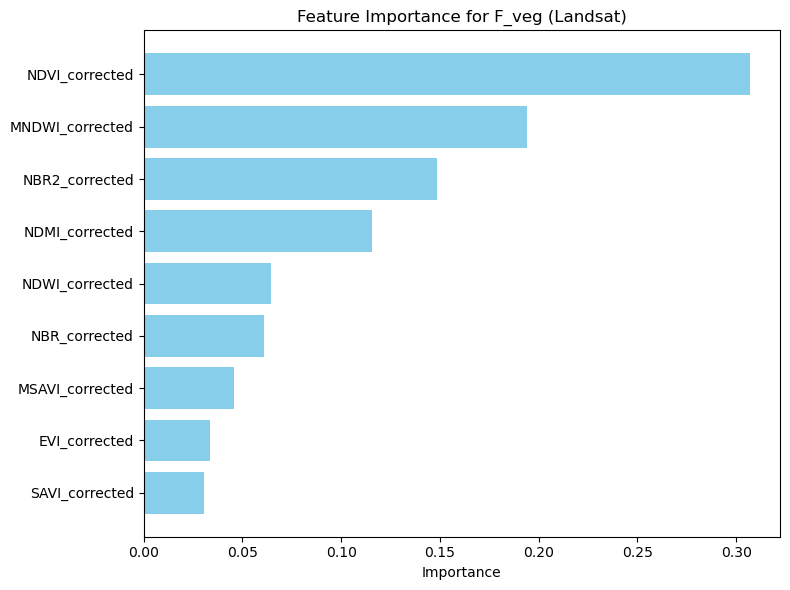

Saved plot: plots\Landsat_Macrochloa steppe_seasonal_plot.png
Saved plot: plots\Landsat_Gully_seasonal_plot.png
Saved plot: plots\Landsat_Reg_seasonal_plot.png
Saved plot: plots\Landsat_Alluvial spread area_seasonal_plot.png
Saved plot: plots\Landsat_Wadi_seasonal_plot.png
Saved plot: plots\Landsat_Salty steppe_seasonal_plot.png
Saved combined plot: plots\Landsat_all_habitats_seasonal_plot.png

Random Forest performance metrics (Sentinel2):
R2_train: 0.931
R2_test: 0.507
RMSE_train: 0.026
RMSE_test: 0.077

Feature importance ranking:
             Index  Importance
0    EVI_corrected    0.173413
1   NBR2_corrected    0.155462
2  MNDWI_corrected    0.128260
3   NDMI_corrected    0.109437
4   NDWI_corrected    0.107072
5    NBR_corrected    0.103731
6  MSAVI_corrected    0.095206
7   NDVI_corrected    0.063998
8   SAVI_corrected    0.063420


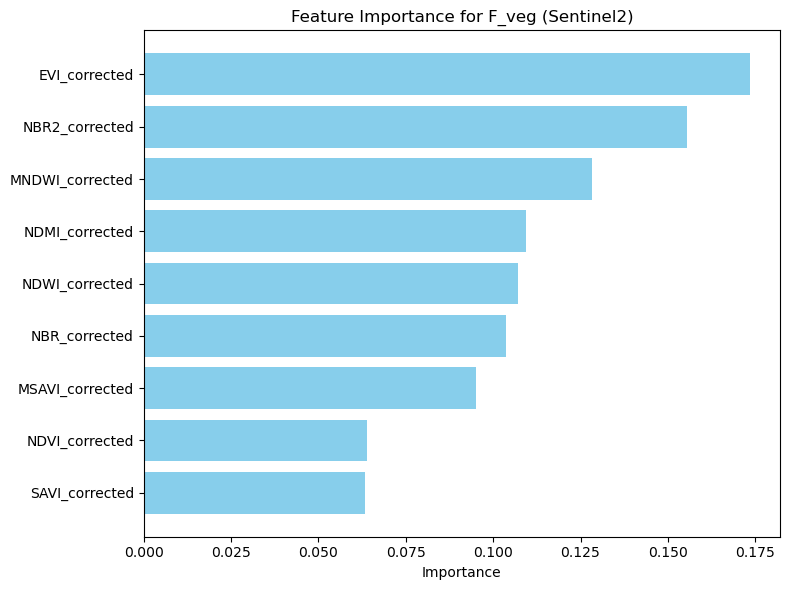

Saved plot: plots\Sentinel2_Macrochloa steppe_seasonal_plot.png
Saved plot: plots\Sentinel2_Gully_seasonal_plot.png
Saved plot: plots\Sentinel2_Reg_seasonal_plot.png
Saved plot: plots\Sentinel2_Alluvial spread area_seasonal_plot.png
Saved plot: plots\Sentinel2_Wadi_seasonal_plot.png
Saved plot: plots\Sentinel2_Salty steppe_seasonal_plot.png
Saved combined plot: plots\Sentinel2_all_habitats_seasonal_plot.png

Random Forest performance metrics (MOD09A1):
R2_train: 0.925
R2_test: 0.419
RMSE_train: 0.032
RMSE_test: 0.076

Feature importance ranking:
             Index  Importance
0   NDVI_corrected    0.305766
1    NBR_corrected    0.208705
2   NDWI_corrected    0.141099
3    EVI_corrected    0.072801
4   NBR2_corrected    0.064955
5  MSAVI_corrected    0.061362
6   NDMI_corrected    0.052073
7  MNDWI_corrected    0.050946
8   SAVI_corrected    0.042294


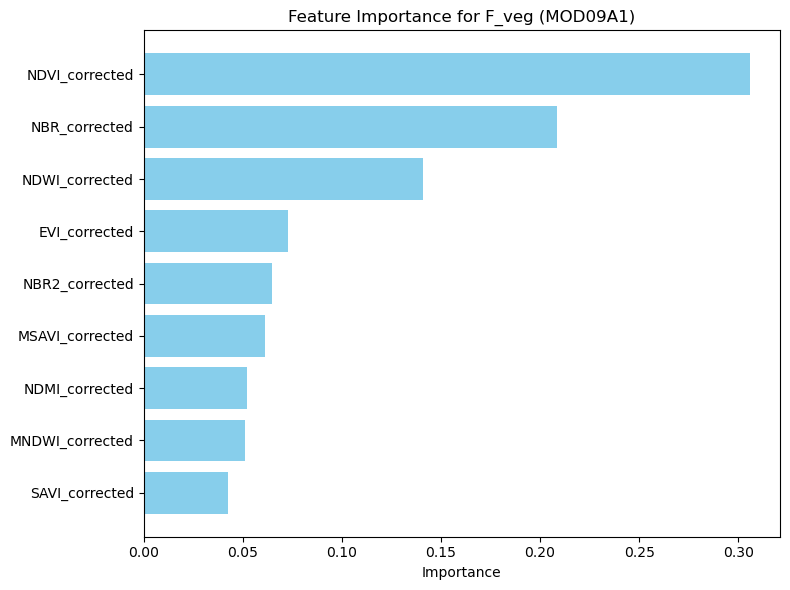

Saved plot: plots\MOD09A1_Macrochloa steppe_seasonal_plot.png
Saved plot: plots\MOD09A1_Gully_seasonal_plot.png
Saved plot: plots\MOD09A1_Reg_seasonal_plot.png
Saved plot: plots\MOD09A1_Alluvial spread area_seasonal_plot.png
Saved plot: plots\MOD09A1_Wadi_seasonal_plot.png
Saved plot: plots\MOD09A1_Salty steppe_seasonal_plot.png
Saved combined plot: plots\MOD09A1_all_habitats_seasonal_plot.png

Random Forest performance metrics (MOD13Q1):
R2_train: 0.887
R2_test: 0.198
RMSE_train: 0.039
RMSE_test: 0.090

Feature importance ranking:
            Index  Importance
0  NDVI_corrected    0.629264
1   EVI_corrected    0.370736


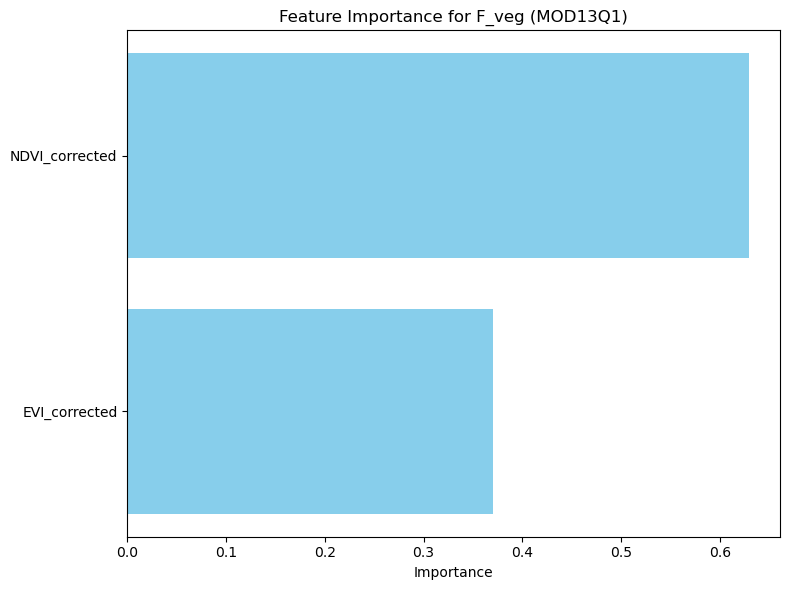

Saved plot: plots\MOD13Q1_Macrochloa steppe_seasonal_plot.png
Saved plot: plots\MOD13Q1_Gully_seasonal_plot.png
Saved plot: plots\MOD13Q1_Reg_seasonal_plot.png
Saved plot: plots\MOD13Q1_Alluvial spread area_seasonal_plot.png
Saved plot: plots\MOD13Q1_Wadi_seasonal_plot.png
Saved plot: plots\MOD13Q1_Salty steppe_seasonal_plot.png
Saved combined plot: plots\MOD13Q1_all_habitats_seasonal_plot.png


In [200]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from scipy import optimize

# --- Seasonal sine function ---
def seasonal_func(t, y0, amp, tau, phi):
    return y0 + amp * np.sin(2 * np.pi * t / tau + phi)

# --- Random Forest function ---
def rf_index_importance(merged_df, field_col='F_veg', rs_indices=None, satellite_name='RS',
                        test_size=0.3, random_state=42, n_estimators=500, plot=True, verbose=True):
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]

    df = merged_df.dropna(subset=[field_col]+rs_indices).copy()
    X = df[rs_indices].values
    y = df[field_col].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)

    rf = RandomForestRegressor(n_estimators=n_estimators, random_state=random_state, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_train_pred = rf.predict(X_train)
    y_test_pred = rf.predict(X_test)

    metrics = {
        'R2_train': r2_score(y_train, y_train_pred),
        'R2_test': r2_score(y_test, y_test_pred),
        'RMSE_train': mean_squared_error(y_train, y_train_pred, squared=False),
        'RMSE_test': mean_squared_error(y_test, y_test_pred, squared=False)
    }

    importances = rf.feature_importances_
    importance_df = pd.DataFrame({'Index': rs_indices, 'Importance': importances})\
                    .sort_values(by='Importance', ascending=False).reset_index(drop=True)

    if verbose:
        print(f"\nRandom Forest performance metrics ({satellite_name}):")
        for k, v in metrics.items():
            print(f"{k}: {v:.3f}")
        print("\nFeature importance ranking:")
        print(importance_df)

    if plot:
        plt.figure(figsize=(8,6))
        plt.barh(importance_df['Index'], importance_df['Importance'], color='skyblue')
        plt.gca().invert_yaxis()
        plt.xlabel('Importance')
        plt.title(f'Feature Importance for {field_col} ({satellite_name})')
        plt.tight_layout()
        plt.show()

    return importance_df, rf, metrics

# --- Per-habitat seasonal plot ---
def plot_seasonal_avg_per_habitat_dual_axis(merged_df, field_col='F_veg', rs_indices=None,
                                            satellite_name='RS', outdir='plots', top_n=3):
    if 'Habitat' not in merged_df.columns:
        raise ValueError("merged_df must contain 'Habitat' column for this plot")

    os.makedirs(outdir, exist_ok=True)
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]

    season_order = ['Spring','Summer','Fall','Winter']
    merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)
    habitats = merged_df['Habitat'].unique()
    season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}

    for hab in habitats:
        df_hab = merged_df[merged_df['Habitat']==hab].copy()
        df_avg = df_hab.groupby(['Year','Season'])[[field_col]+rs_indices].mean().reset_index()
        df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays))
        # df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str) + '-' + df_avg['Season'].map(season_middays))
        x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)
        y_field = df_avg[field_col].values.astype(float)

        n_indices = min(len(rs_indices), top_n)
        ncols = 2
        nrows = int(np.ceil(n_indices/ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(12,5*nrows), squeeze=False)

        params_field = [np.nan]*4
        if len(y_field)>=4:
            p0_field = [np.nanmean(y_field), (np.nanmax(y_field)-np.nanmin(y_field))/2, 365, 0]
            try:
                params_field, _ = optimize.curve_fit(seasonal_func, x_data, y_field, p0=p0_field)
            except:
                pass

        for i, ind in enumerate(rs_indices[:top_n]):
            row, col = divmod(i, ncols)
            ax1 = axes[row, col]
            y_rs = df_avg[ind].values.astype(float)
            params_rs = [np.nan]*4
            if len(y_rs)>=4:
                p0_rs = [np.nanmean(y_rs), (np.nanmax(y_rs)-np.nanmin(y_rs))/2, 365, 0]
                try:
                    params_rs, _ = optimize.curve_fit(seasonal_func, x_data, y_rs, p0=p0_rs)
                except:
                    pass

            ax1.scatter(df_avg['datetime'], y_field, c='green', alpha=0.5, label=f'Field ({field_col})')
            if np.all(np.isfinite(params_field)):
                ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field), c='green', lw=2.5, label='Field fit')
            ax1.set_ylabel(field_col, color='green')
            ax1.tick_params(axis='y', labelcolor='green')
            ax1.grid(lw=0.2)

            ax2 = ax1.twinx()
            ax2.scatter(df_avg['datetime'], y_rs, c='orange', alpha=0.5, label=f'{satellite_name} ({ind})')
            if np.all(np.isfinite(params_rs)):
                ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs), c='orange', lw=2.5, label='RS fit')
            ax2.set_ylabel(ind, color='orange')
            ax2.tick_params(axis='y', labelcolor='orange')

            corr = np.corrcoef(y_field, y_rs)[0,1] if len(y_field)>1 else np.nan
            ax1.set_title(f'{ind} vs {field_col} (corr={corr:.2f})', fontsize=14)
            ax1.legend(loc='upper left', fontsize=10)
            ax2.legend(loc='upper right', fontsize=10)
            ax1.set_xlabel('Date')

        total_subplots = nrows*ncols
        if total_subplots>n_indices:
            for j in range(n_indices, total_subplots):
                fig.delaxes(axes.flatten()[j])

        plt.suptitle(f'Habitat: {hab} ({satellite_name})', fontsize=16)
        plt.tight_layout()
        outfile = os.path.join(outdir, f"{satellite_name}_{hab}_seasonal_plot.png")
        plt.savefig(outfile, dpi=300, bbox_inches='tight')
        print(f"Saved plot: {outfile}")
        plt.close()

# --- Combined all-habitats seasonal plot ---
def plot_seasonal_avg_all_habitats_dual_axis(merged_df, field_col='F_veg', rs_indices=None,
                                             satellite_name='RS', outdir='plots'):
    if 'Habitat' not in merged_df.columns:
        raise ValueError("merged_df must contain 'Habitat' column for this plot")
    os.makedirs(outdir, exist_ok=True)
    if rs_indices is None:
        rs_indices = [col for col in merged_df.columns if col.endswith('_corrected')]

    season_order = ['Spring','Summer','Fall','Winter']
    merged_df['Season'] = pd.Categorical(merged_df['Season'], categories=season_order, ordered=True)
    habitats = merged_df['Habitat'].unique()
    season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}

    palette = sns.color_palette("tab20", len(habitats))
    habitat_colors = dict(zip(habitats, palette))

    n_indices = len(rs_indices)
    ncols = 2
    nrows = int(np.ceil(n_indices/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12,5*nrows), squeeze=False)

    for i, ind in enumerate(rs_indices):
        row, col = divmod(i, ncols)
        ax1 = axes[row, col]
        ax2 = ax1.twinx()

        for hab in habitats:
            df_hab = merged_df[merged_df['Habitat']==hab].copy()
            df_avg = df_hab.groupby(['Year','Season'])[[field_col, ind]].mean().reset_index()
            df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str) + '-' + df_avg['Season'].astype(str).map(season_middays))
            # df_avg['datetime'] = pd.to_datetime(df_avg['Year'].astype(str) + '-' + df_avg['Season'].map(season_middays))
            x_data = (df_avg['datetime'] - df_avg['datetime'].min()).dt.total_seconds() / (24*3600)

            y_field = df_avg[field_col].values.astype(float)
            params_field = [np.nan]*4
            if len(y_field)>=4:
                p0_field = [np.nanmean(y_field),(np.nanmax(y_field)-np.nanmin(y_field))/2,365,0]
                try:
                    params_field,_ = optimize.curve_fit(seasonal_func, x_data, y_field, p0=p0_field)
                except:
                    pass
            ax1.scatter(df_avg['datetime'], y_field, color=habitat_colors[hab], alpha=0.4, marker='o')
            if np.all(np.isfinite(params_field)):
                ax1.plot(df_avg['datetime'], seasonal_func(x_data, *params_field),
                         color=habitat_colors[hab], lw=2, linestyle='-',
                         label=f'{hab} Field')

            y_rs = df_avg[ind].values.astype(float)
            params_rs = [np.nan]*4
            if len(y_rs)>=4:
                p0_rs = [np.nanmean(y_rs),(np.nanmax(y_rs)-np.nanmin(y_rs))/2,365,0]
                try:
                    params_rs,_ = optimize.curve_fit(seasonal_func, x_data, y_rs, p0=p0_rs)
                except:
                    pass
            ax2.scatter(df_avg['datetime'], y_rs, color=habitat_colors[hab], alpha=0.4, marker='x')
            if np.all(np.isfinite(params_rs)):
                ax2.plot(df_avg['datetime'], seasonal_func(x_data, *params_rs),
                         color=habitat_colors[hab], lw=2, linestyle='--',
                         label=f'{hab} {satellite_name}')

        ax1.set_ylabel(field_col, color='green')
        ax2.set_ylabel(ind, color='orange')
        ax1.tick_params(axis='y', labelcolor='green')
        ax2.tick_params(axis='y', labelcolor='orange')
        ax1.set_xlabel('Date')
        ax1.set_title(f'{ind} vs {field_col}', fontsize=14)

        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='best')

    total_subplots = nrows*ncols
    if total_subplots>n_indices:
        for j in range(n_indices, total_subplots):
            fig.delaxes(axes.flatten()[j])

    plt.suptitle(f'Seasonal Averages All Habitats ({satellite_name})', fontsize=16)
    plt.tight_layout()
    outfile = os.path.join(outdir, f"{satellite_name}_all_habitats_seasonal_plot.png")
    plt.savefig(outfile, dpi=300, bbox_inches='tight')
    print(f"Saved combined plot: {outfile}")
    plt.close()

# --- Workflow Example ---
rs_index_list = ['NDVI_corrected','EVI_corrected','SAVI_corrected','MSAVI_corrected','NDMI_corrected',
                 'NBR_corrected','NBR2_corrected','NDWI_corrected','MNDWI_corrected']
sat_names = ['Landsat','Sentinel2','MOD09A1','MOD13Q1']

for df, sat in zip(merged_dfs1, sat_names):
    if sat=='MOD13Q1':
        indices = ['NDVI_corrected','EVI_corrected']
    else:
        indices = rs_index_list

    # Random Forest
    importance_df, rf_model, metrics = rf_index_importance(df, field_col='F_alive', rs_indices=indices,
                                                          satellite_name=sat, plot=True, verbose=True)
    top_indices = importance_df['Index'].tolist()[:3]

    # Per-habitat plots
    plot_seasonal_avg_per_habitat_dual_axis(df, field_col='F_alive', rs_indices=top_indices,
                                            satellite_name=sat, outdir='plots', top_n=3)
    # Combined all-habitats plot
    plot_seasonal_avg_all_habitats_dual_axis(df, field_col='F_alive', rs_indices=top_indices,
                                             satellite_name=sat, outdir='plots')


In [62]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_corr_heatmap(df, field_col='F_alive', rs_indices=None, title=None):
    """
    Plot a lower-triangle correlation heatmap for RS indices + field variable.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe containing RS indices and field variable.
    field_col : str
        Name of the field variable column.
    rs_indices : list
        List of RS index column names. If None, auto-detects columns ending with '_corrected'.
    title : str
        Optional title for the heatmap.
    """
    if rs_indices is None:
        rs_indices = [col for col in df.columns if col.endswith('_corrected')]
    
    # Select RS indices + field column
    corr_data = df[rs_indices + [field_col]].copy()
    
    # Remove NaN or inf values
    corr_data = corr_data.replace([np.inf, -np.inf], np.nan).dropna()
    
    # Compute correlation matrix
    corr_matrix = corr_data.corr()
    
    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    # Plot heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap='coolwarm',
        vmin=-1, vmax=1,
        linewidths=0.5
    )
    if title is None:
        title = f'Correlation Heatmap ({field_col} & RS Indices)'
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.show()
    
    return corr_matrix


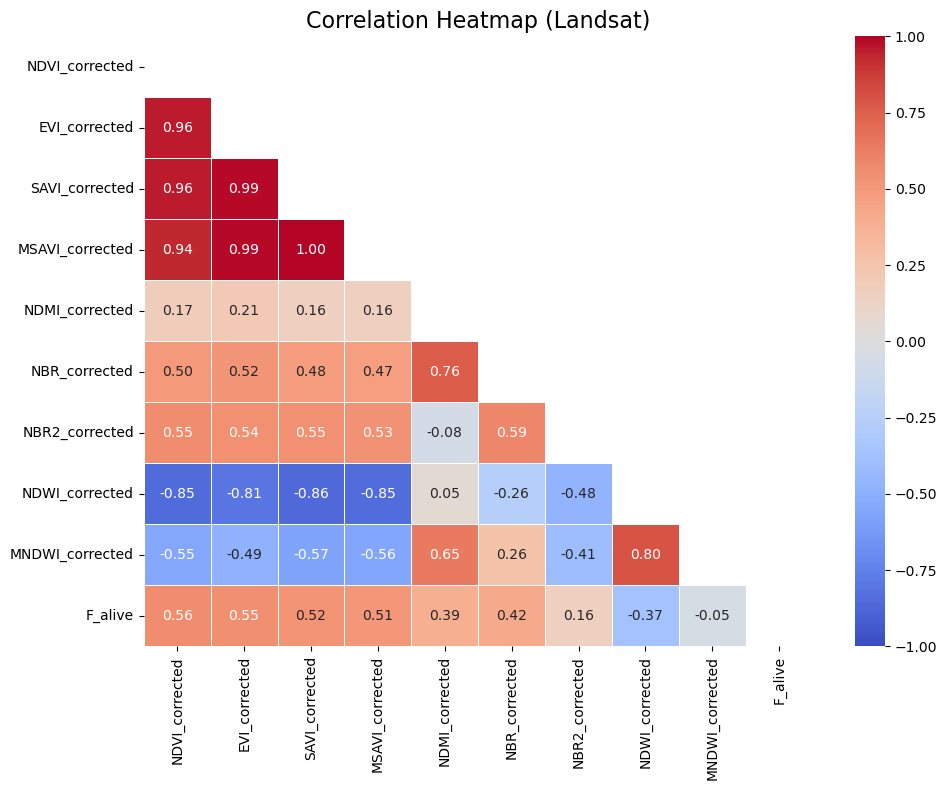

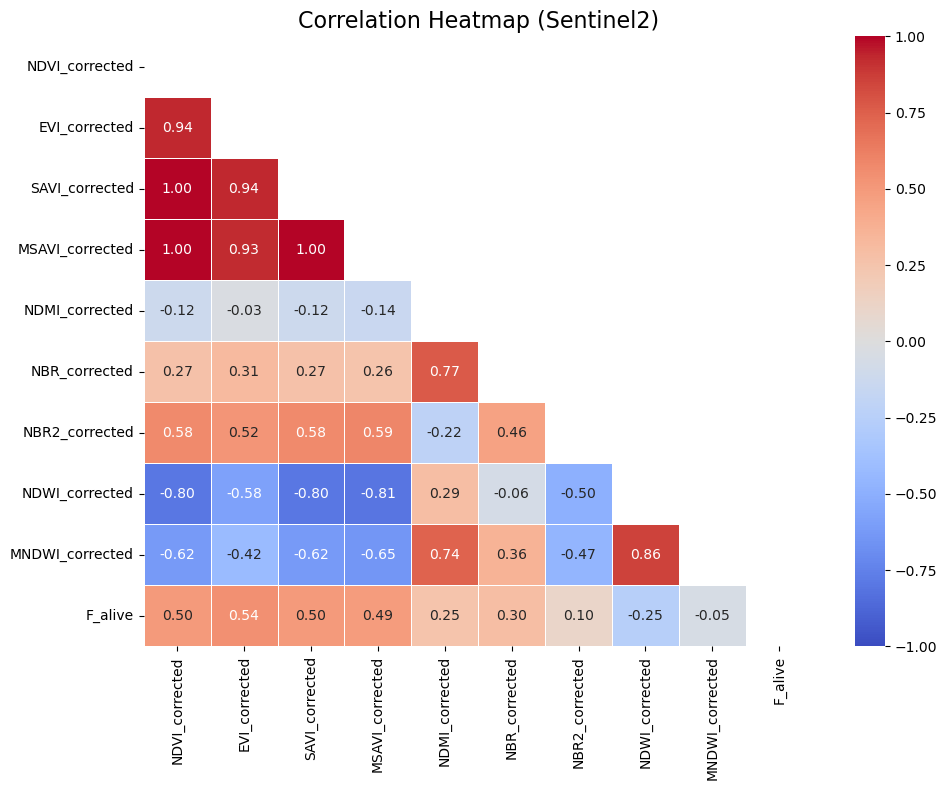

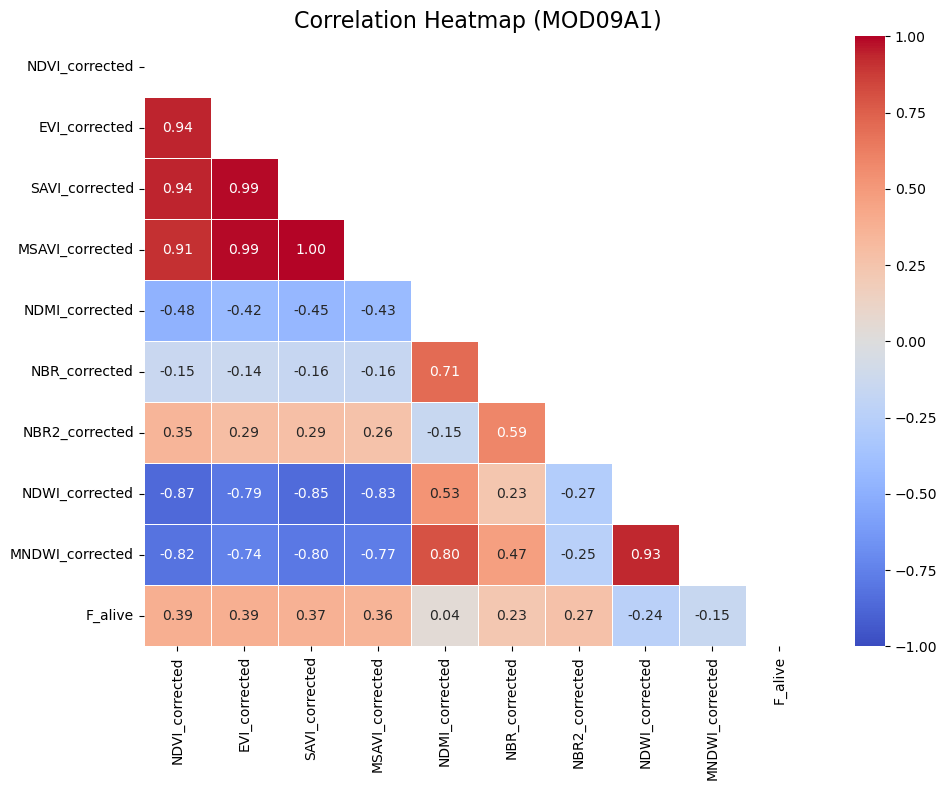

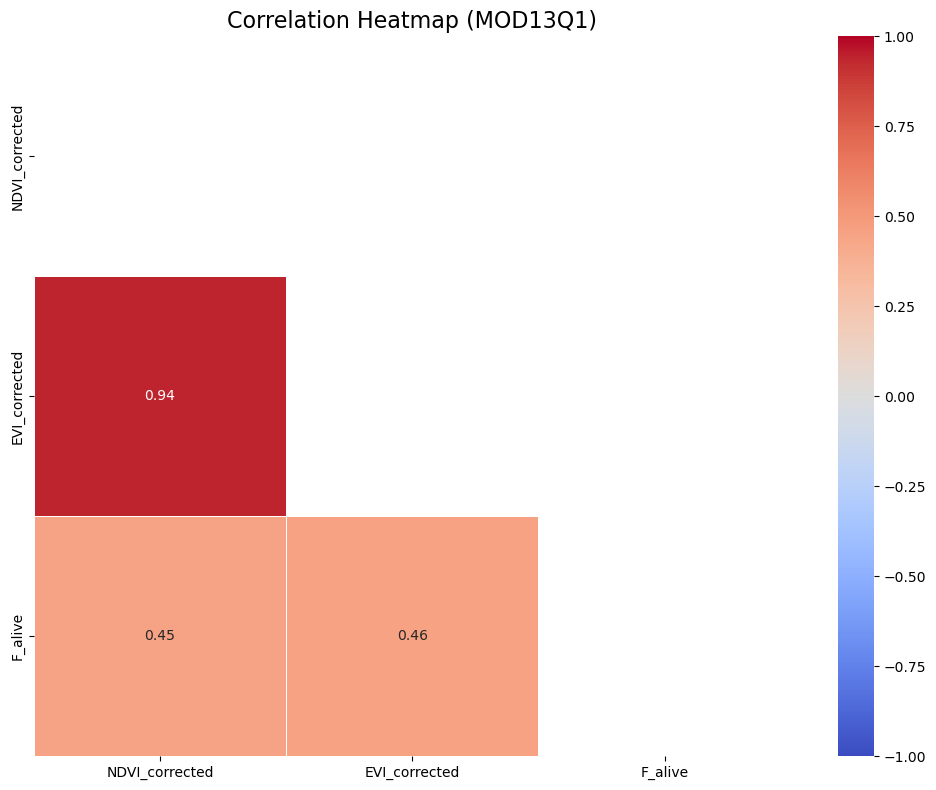

In [63]:
# --- Workflow Example ---
rs_index_list = [
    'NDVI_corrected','EVI_corrected','SAVI_corrected','MSAVI_corrected','NDMI_corrected',
    'NBR_corrected','NBR2_corrected','NDWI_corrected','MNDWI_corrected'
]
sat_names = ['Landsat','Sentinel2','MOD09A1','MOD13Q1']

for df, sat in zip(merged_dfs1, sat_names):
    # Select appropriate RS indices per satellite
    if sat == 'MOD13Q1':
        indices = ['NDVI_corrected', 'EVI_corrected']
    else:
        indices = rs_index_list
    
    # Generate heatmap per satellite
    corr_matrix = plot_corr_heatmap(
        df, 
        field_col='F_alive', 
        rs_indices=indices, 
        title=f'Correlation Heatmap ({sat})'
    )


## Discarded

### old version: Processed by two options:
- Station wide
- Habitat aggregated

In [ ]:
rs_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv',
         'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv',
         'MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv',
         'MOD13Q1_MarDec_2000_2024_All_FieldStations_agg.csv']

In [ ]:
# Standardize year column in both
field_df["Year"] = field_df["Year"].astype(int)
agg_df["year"] = agg_df["year"].astype(int)

# Create a Year_Season column in field_df to match agg_df
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

# Now you can merge on Station + Year_Season
merged = pd.merge(
    field_df,
    agg_df,
    left_on=["Station", "Year_Season"],
    right_on=["Station", "Year_Season"],
    how="inner"
)


In [55]:
infp = [
    'Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
    'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
    'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
    'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv'
]

# Field data
local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
local_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'
field_fp = local_foler + local_fp
field_df = pd.read_csv(field_fp)
field_df["Year"] = field_df["Year"].astype(int)
# Create a Year_Season column in field_df to match agg_df
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

for rs_file in infp:
    csv_file = rs_file.replace(".csv", "_agg.csv")
    print(f"\n--- Processing {csv_file} ---")
    rs_df = pd.read_csv(csv_file)
    
    # Now you can merge on Station + Year_Season
    merged = pd.merge(field_df, rs_df, on=["Station", "Year_Season"], how="inner")
    print("Merged shape:", merged.shape)

    # Export
    output_csv = csv_file.replace(".csv", "_merged.csv")
    merged.to_csv(output_csv, index=False)
    print(f"Field observation and RS metrics merged df saved to: {output_csv}")


--- Processing Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv ---
Merged shape: (3513, 29)
Field observation and RS metrics merged df saved to: Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg_merged.csv

--- Processing Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv ---
Merged shape: (2608, 29)
Field observation and RS metrics merged df saved to: Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg_merged.csv

--- Processing MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Merged shape: (3536, 29)
Field observation and RS metrics merged df saved to: MOD09A1_MarDec_2000_2024_All_FieldStations_agg_merged.csv

--- Processing MOD13Q1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Merged shape: (3536, 22)
Field observation and RS metrics merged df saved to: MOD13Q1_MarDec_2000_2024_All_FieldStations_agg_merged.csv


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import numpy as np
import os

# -----------------------------
# Paths
# -----------------------------
local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
local_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'
field_fp = os.path.join(local_foler, local_fp)

rs_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
         'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
         'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
         'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv'
        ]

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

In [2]:
field_df = pd.read_csv(field_fp)
field_df["Year"] = field_df["Year"].astype(int)
# Create a Year_Season column in field_df to match rs_df
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

In [4]:
field_df.head()

,Station,Lat,Lon,Year,Season,Alive,Dead,Ground,Unknown,Sum.not.unknown,GridSize,F_alive,F_dead,F_veg,F_ground,Habitat,Year_Season
0,ALBALF1,33.20027,-4.03529,2016,Spring,1,5,354,0,360,360,0.002778,0.013889,0.016667,0.983333,Macrochloa steppe,2016_Spring
1,ALBALF1,33.20027,-4.03529,2016,Summer,1,8,350,1,359,360,0.002786,0.022284,0.025070,0.974930,Macrochloa steppe,2016_Summer
2,ALBALF1,33.20027,-4.03529,2016,Fall,0,14,342,4,356,360,0.000000,0.039326,0.039326,0.960674,Macrochloa steppe,2016_Fall
3,ALBALF1,33.20027,-4.03529,2016,Winter,0,6,354,0,360,360,0.000000,0.016667,0.016667,0.983333,Macrochloa steppe,2016_Winter
4,ALBALF1,33.20027,-4.03529,2017,Spring,3,7,700,10,710,720,0.004225,0.009859,0.014085,0.985915,Macrochloa steppe,2017_Spring


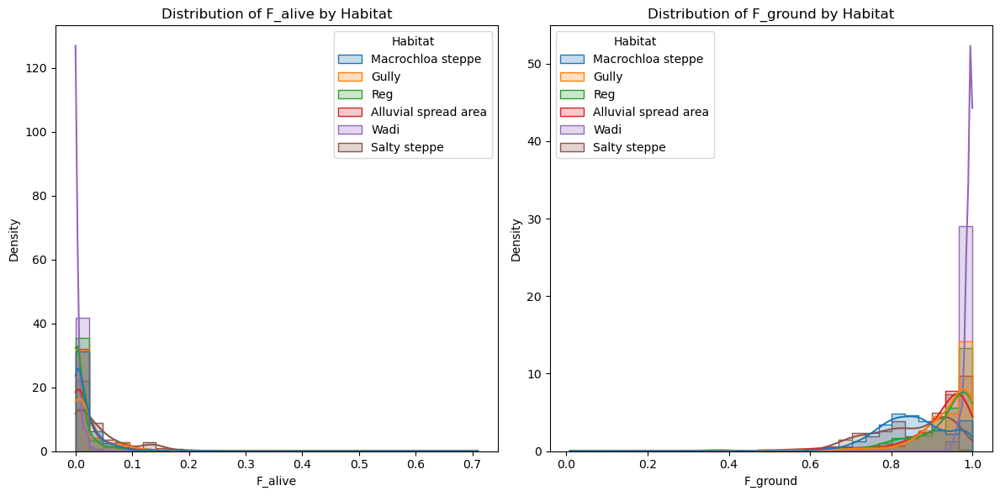

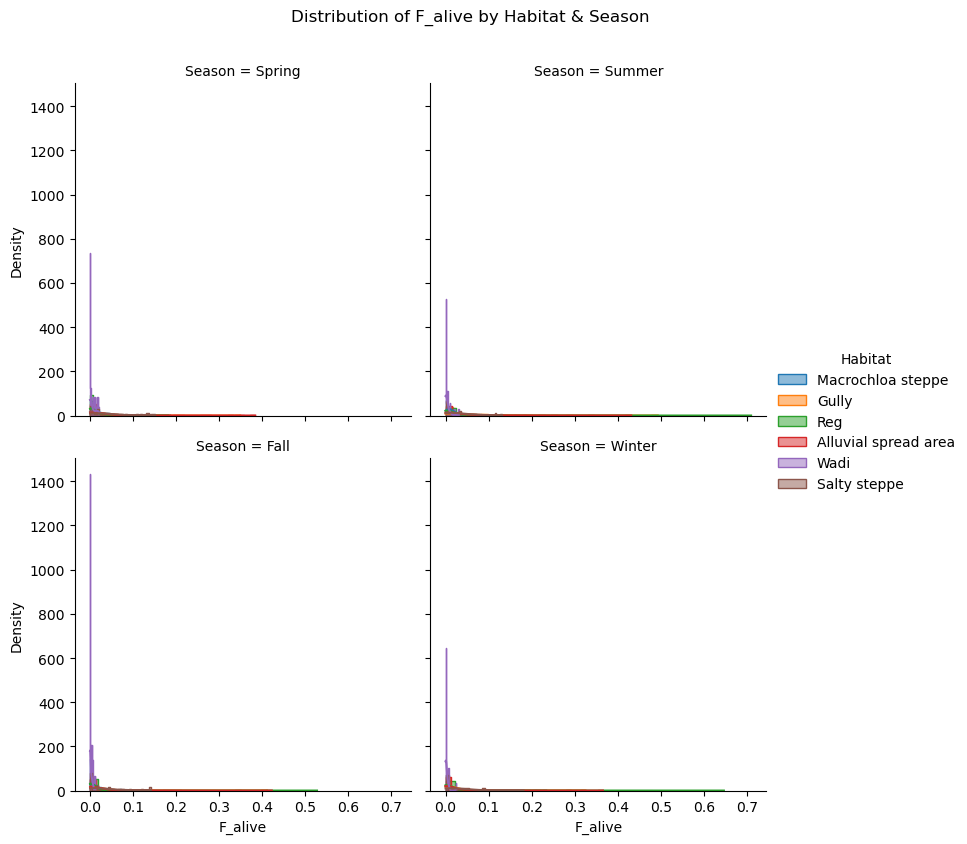

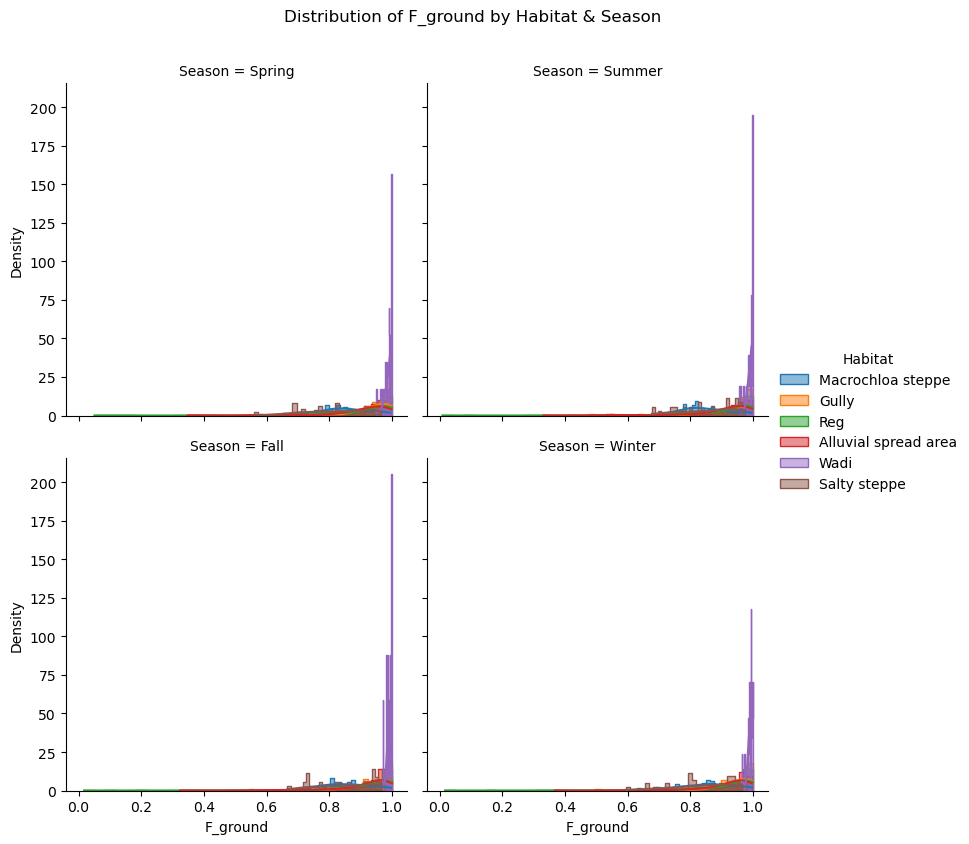

In [9]:
# Load your dataframe (replace with your file path)
# df = pd.read_csv("your_file.csv")
df = field_df

# Pick the columns of interest
cols_to_plot = ["F_alive", "F_ground"]

# Plot histograms
plt.figure(figsize=(12,6))

# # 1 Only histogram
# for i, col in enumerate(cols_to_plot, 1):
#     plt.subplot(1, 2, i)
#     sns.histplot(df[col], bins=30, kde=True, color="steelblue")
#     plt.title(f"Distribution of {col}")
#     plt.xlabel(col)
#     plt.ylabel("Count")

# 2 separated by habitats
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(1, 2, i)
    sns.histplot(data=df, x=col, hue="Habitat", bins=30, kde=True, 
                 element="step", stat="density", common_norm=False)
    plt.title(f"Distribution of {col} by Habitat")
    plt.xlabel(col)
    plt.ylabel("Density")
plt.tight_layout()
plt.show()

# 3 add variable on Season
for col in cols_to_plot:
    g = sns.FacetGrid(df, col="Season", hue="Habitat", col_wrap=2, sharex=True, sharey=True, height=4)
    g.map(sns.histplot, col, bins=30, stat="density", common_norm=False, element="step", kde=True)
    g.add_legend()
    g.set_axis_labels(col, "Density")
    g.fig.suptitle(f"Distribution of {col} by Habitat & Season", y=1.05)
    plt.show()


--- Processing Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv ---
Merged shape: (3513, 29)
RMSE: 0.0256, R²: 0.5651, CV-R²: 0.3309


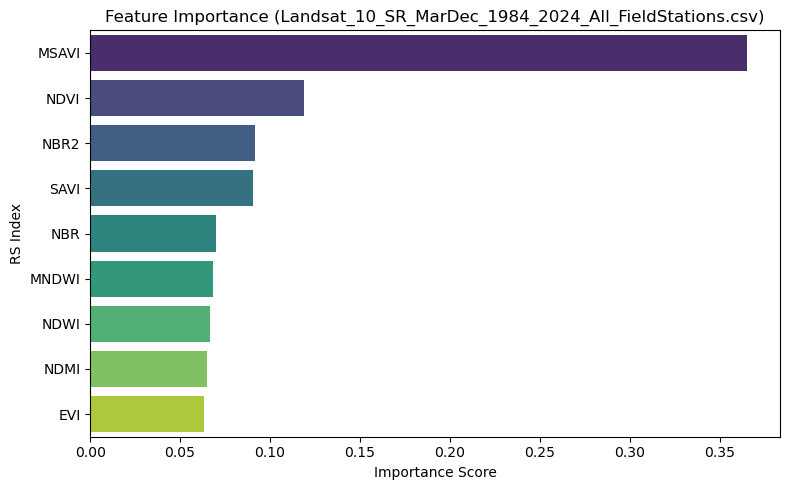

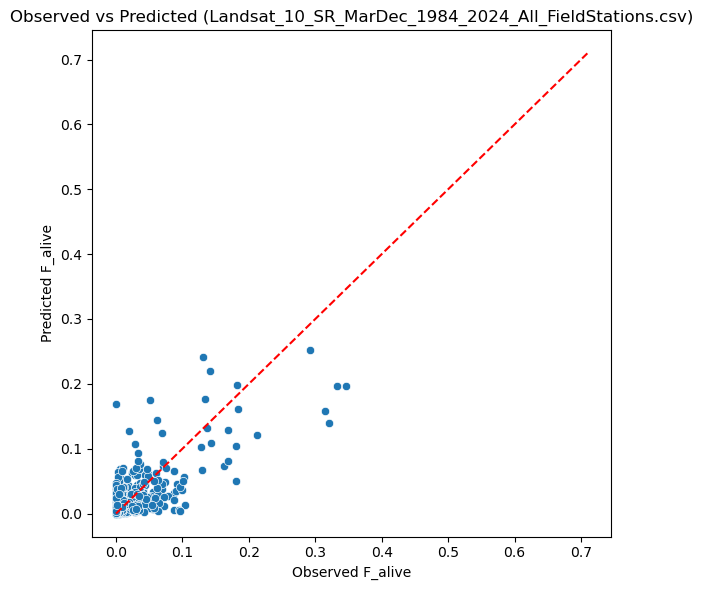


--- Processing Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv ---
Merged shape: (2608, 29)
RMSE: 0.0334, R²: 0.4327, CV-R²: 0.2255


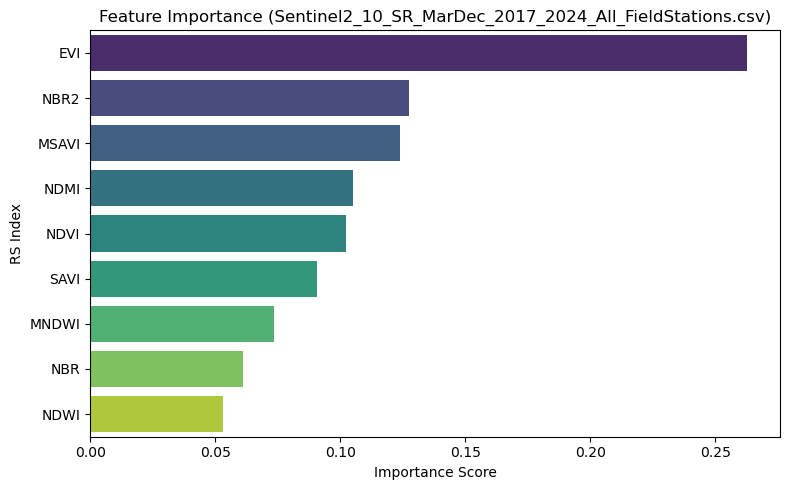

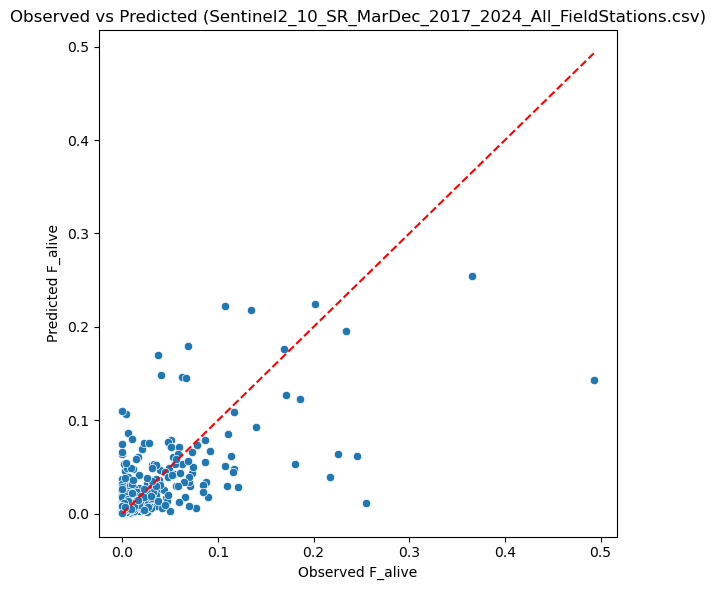


--- Processing MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Merged shape: (3536, 29)
RMSE: 0.0348, R²: 0.4252, CV-R²: 0.1622


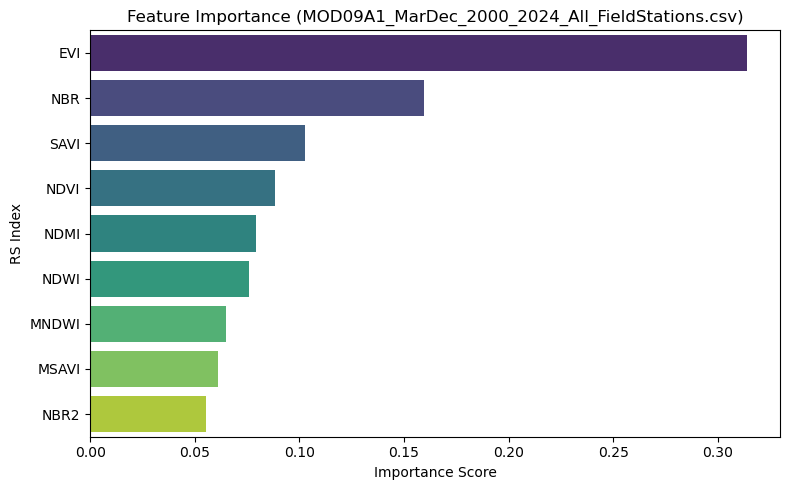

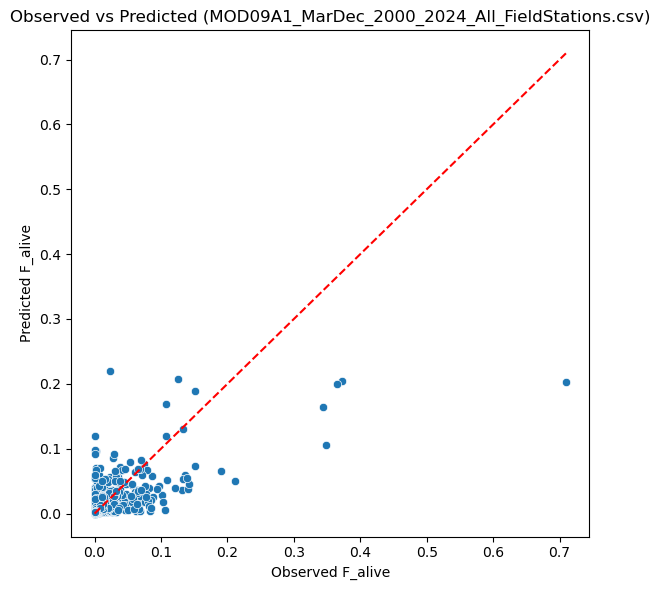


--- Processing MOD13Q1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Merged shape: (3536, 22)
RMSE: 0.0350, R²: 0.4211, CV-R²: 0.0873


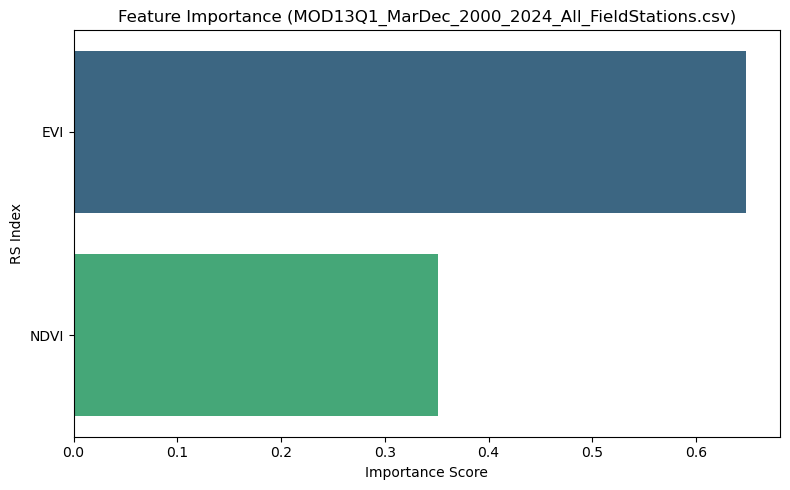

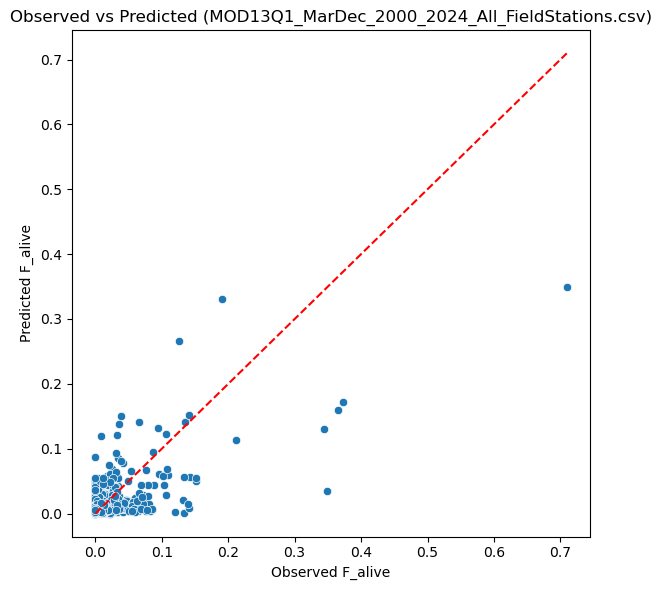

In [61]:

# -----------------------------
# Field data
# -----------------------------
field_df = pd.read_csv(field_fp)
field_df["Year"] = field_df["Year"].astype(int)
# Create a Year_Season column in field_df to match rs_df
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

# -----------------------------
# Loop through RS datasets
# -----------------------------
for rs_file in rs_fp:
    csv_file = rs_file.replace(".csv", "_agg.csv")
    print(f"\n--- Processing {csv_file} ---")
    rs_df = pd.read_csv(csv_file)
    
    # Standardize naming
    rs_df = rs_df.rename(columns={"year": "Year"})
    
    # Keep only relevant cols
    vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']
    available_cols = [c for c in vi_cols if c in rs_df.columns]
    
    # rs_df = rs_df[["Year", "Season", "Habitat"] + available_cols]
    
    # Merge with field data
    merged = pd.merge(field_df, rs_df, on=["Station", "Year_Season"], how="inner")
    print("Merged shape:", merged.shape)
    if merged.empty:
        print("⚠️ No overlap found, skipping this dataset.")
        continue
    
    # -----------------------------
    # Random Forest with Imputation
    # -----------------------------
    X = merged[available_cols]
    y = merged["F_alive"] #F_alive or F_veg
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Pipeline: Imputer + RF
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),  # fill NaNs with median
        ("rf", RandomForestRegressor(n_estimators=500, random_state=42))
    ])
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    cv_scores = cross_val_score(model, X, y, cv=5, scoring="r2")
    
    print(f"RMSE: {rmse:.4f}, R²: {r2:.4f}, CV-R²: {cv_scores.mean():.4f}")
    
    # -----------------------------
    # Feature Importance
    # -----------------------------
    rf = model.named_steps["rf"]  # get RF model from pipeline
    importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
    
    plt.figure(figsize=(8,5))
    sns.barplot(x=importances, y=importances.index, hue=importances.index,
                palette="viridis", dodge=False, legend=False)
    plt.title(f"Feature Importance ({rs_file})")
    plt.xlabel("Importance Score")
    plt.ylabel("RS Index")
    plt.tight_layout()
    out_fp = os.path.join(save_folder, f"{os.path.basename(csv_file).replace('.csv','')}F_alive_FeatureImportance.png")
    plt.savefig(out_fp, dpi=300)
    plt.show()
    plt.close()

    # -----------------------------
    # Observed vs Predicted
    # -----------------------------
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_test, y=y_pred)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
    plt.xlabel("Observed F_alive") #F_alive or F_veg
    plt.ylabel("Predicted F_alive") #F_alive or F_veg
    plt.title(f"Observed vs Predicted ({rs_file})")
    plt.tight_layout()
    out_fp = os.path.join(save_folder, f"{os.path.basename(csv_file).replace('agg.csv','')}F_alive_ObsVsPred.png")
    plt.savefig(out_fp, dpi=300)
    plt.show()
    plt.close()


In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import numpy as np
import os

# -----------------------------
# Paths
# -----------------------------
local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
field_fp = os.path.join(local_foler, 'Trophic survey data analysis_all_2016-2023_habitat.csv')

rs_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
         'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
         'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
         'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv']

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# Load field data
# -----------------------------
field_df = pd.read_csv(field_fp)
field_df["Year"] = field_df["Year"].astype(int)
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

# -----------------------------
# Loop through RS datasets
# -----------------------------
for rs_file in rs_fp:
    csv_file = rs_file.replace(".csv", "_agg.csv")
    print(f"\n--- Processing {csv_file} ---")
    
    rs_df = pd.read_csv(csv_file)
    
    # Standardize year
    if "year" in rs_df.columns:
        rs_df = rs_df.rename(columns={"year": "Year"})
    
    # Create Year_Season if needed
    if "Year_Season" not in rs_df.columns:
        rs_df["Year_Season"] = rs_df["Year"].astype(str) + "_" + rs_df["Season"]
    
    # Keep only available RS indices
    vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']
    available_cols = [c for c in vi_cols if c in rs_df.columns]
    
    # Merge with field data
    merged = pd.merge(field_df, rs_df, on=["Station", "Year_Season"], how="inner")
    print("Merged shape:", merged.shape)
    if merged.empty:
        print("⚠️ No overlap found, skipping this dataset.")
        continue
    
    X = merged[available_cols]
    y = merged["F_veg"]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # -----------------------------
    # Random Forest + RandomizedSearchCV
    # -----------------------------
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(random_state=42))
    ])
    
    param_grid = {
        "rf__n_estimators": [200, 500, 800],
        "rf__max_depth": [None, 5, 10, 20],
        "rf__max_features": ["sqrt", "log2", 0.5, 0.8],
        "rf__min_samples_split": [2, 5, 10],
        "rf__min_samples_leaf": [1, 2, 4]
    }
    
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=30,
        scoring="r2",
        cv=5,
        n_jobs=-1,
        verbose=1,
        random_state=42
    )
    
    search.fit(X_train, y_train)
    
    best_model = search.best_estimator_
    print("Best params:", search.best_params_)
    
    y_pred = best_model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"Test RMSE: {rmse:.4f}, R²: {r2:.4f}")
    
    # -----------------------------
    # Permutation Importance
    # -----------------------------
    result = permutation_importance(best_model, X_test, y_test,
                                    n_repeats=10,
                                    random_state=42,
                                    n_jobs=-1)
    
    perm_importances = pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=False)
    print("Permutation Importance:\n", perm_importances)
    
    # -----------------------------
    # Plot Feature Importance
    # -----------------------------
    plt.figure(figsize=(8,5))
    sns.barplot(x=perm_importances, y=perm_importances.index, color="mediumseagreen")
    plt.title(f"Permutation Importance ({rs_file})")
    plt.xlabel("Importance Score")
    plt.ylabel("RS Index")
    plt.tight_layout()
    out_fp = os.path.join(save_folder, rs_file.replace(".csv", "_PermutationImportance.png"))
    plt.savefig(out_fp, dpi=300)
    # plt.show()
    plt.close()
    
    # -----------------------------
    # Observed vs Predicted
    # -----------------------------
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_test, y=y_pred)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
    plt.xlabel("Observed F_veg")
    plt.ylabel("Predicted F_veg")
    plt.title(f"Observed vs Predicted ({rs_file})")
    plt.tight_layout()
    out_fp2 = os.path.join(save_folder, rs_file.replace(".csv", "_ObsVsPred.png"))
    plt.savefig(out_fp2, dpi=300)
    # plt.show()
    plt.close()



--- Processing Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv ---
Merged shape: (3513, 29)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'rf__n_estimators': 500, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_features': 0.5, 'rf__max_depth': None}
Test RMSE: 0.0621, R²: 0.6485
Permutation Importance:
 NDVI     0.822879
NBR2     0.219252
NDMI     0.204047
MSAVI    0.088687
SAVI     0.057578
MNDWI    0.056981
NDWI     0.056739
EVI      0.051770
NBR      0.050169
dtype: float64


C:\Users\PangY\AppData\Local\Temp\ipykernel_6660\3550979163.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perm_importances, y=perm_importances.index,



--- Processing Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv ---
Merged shape: (2608, 29)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'rf__n_estimators': 500, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_features': 0.5, 'rf__max_depth': None}
Test RMSE: 0.0799, R²: 0.5221
Permutation Importance:
 EVI      0.143435
NBR2     0.111058
NDMI     0.063080
MSAVI    0.056446
NDVI     0.047821
MNDWI    0.043281
SAVI     0.037820
NBR      0.034124
NDWI     0.027544
dtype: float64


C:\Users\PangY\AppData\Local\Temp\ipykernel_6660\3550979163.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perm_importances, y=perm_importances.index,



--- Processing MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Merged shape: (3536, 29)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'rf__n_estimators': 500, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_features': 0.5, 'rf__max_depth': None}
Test RMSE: 0.0683, R²: 0.5528
Permutation Importance:
 NDWI     2.420464
NDVI     0.993391
EVI      0.374149
MNDWI    0.278241
MSAVI    0.198651
NBR      0.151236
SAVI     0.131780
NDMI     0.038269
NBR2     0.034742
dtype: float64


C:\Users\PangY\AppData\Local\Temp\ipykernel_6660\3550979163.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perm_importances, y=perm_importances.index,



--- Processing MOD13Q1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Merged shape: (3536, 22)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'rf__n_estimators': 500, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 2, 'rf__max_features': 0.5, 'rf__max_depth': 10}
Test RMSE: 0.0840, R²: 0.3246
Permutation Importance:
 EVI     0.433133
NDVI    0.397676
dtype: float64


C:\Users\PangY\AppData\Local\Temp\ipykernel_6660\3550979163.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perm_importances, y=perm_importances.index,


Test accuracy: 0.708, CV accuracy: 0.547
Permutation importance (higher = better at separating habitats):
NDMI     0.168016
NDVI     0.116162
NBR      0.070705
NBR2     0.066516
MSAVI    0.065808
MNDWI    0.039938
NDWI     0.029408
EVI      0.012822
SAVI     0.009256
dtype: float64


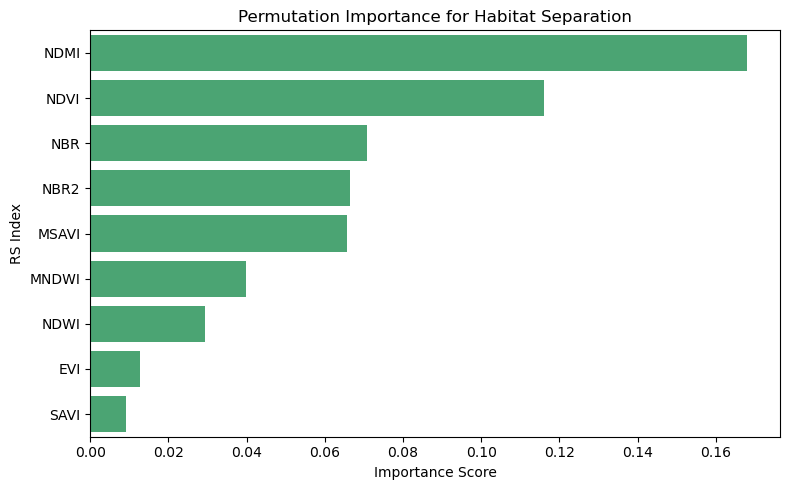

In [64]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# -----------------------------
# Load data
# -----------------------------
# local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
rs_fp = 'Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv'  # 
df = pd.read_csv(rs_fp)

# Keep only indices + Habitat
vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']
available_cols = [c for c in vi_cols if c in df.columns]

# Remove rows with missing Habitat
df = df.dropna(subset=["Habitat"])

X = df[available_cols]
y = df["Habitat"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Pipeline: Imputer + RandomForestClassifier
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=500, random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# -----------------------------
# Evaluate classifier
# -----------------------------
acc = pipeline.score(X_test, y_test)
cv_acc = cross_val_score(pipeline, X, y, cv=5, scoring="accuracy").mean()
print(f"Test accuracy: {acc:.3f}, CV accuracy: {cv_acc:.3f}")

# -----------------------------
# Permutation importance
# -----------------------------
perm_result = permutation_importance(pipeline, X_test, y_test,
                                     n_repeats=10,
                                     random_state=42,
                                     n_jobs=-1)

perm_importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
print("Permutation importance (higher = better at separating habitats):")
print(perm_importances)

# -----------------------------
# Plot permutation importance
# -----------------------------
plt.figure(figsize=(8,5))
sns.barplot(x=perm_importances, y=perm_importances.index,
            color="mediumseagreen")
plt.title("Permutation Importance for Habitat Separation")
plt.xlabel("Importance Score")
plt.ylabel("RS Index")
plt.tight_layout()
plt.show()



--- Processing Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv ---
Test accuracy: 0.712, CV accuracy: 0.613
Permutation importance (higher = better at separating habitats):
NDMI     0.202502
NDVI     0.161496
MSAVI    0.098664
NBR2     0.074593
MNDWI    0.067617
NBR      0.062603
NDWI     0.060242
EVI      0.049103
SAVI     0.010073
dtype: float64

--- Processing Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv ---
Test accuracy: 0.725, CV accuracy: 0.686
Permutation importance (higher = better at separating habitats):
NDMI     0.162167
NBR2     0.122118
EVI      0.085075
NDWI     0.082234
MNDWI    0.061641
NBR      0.035407
SAVI     0.006832
MSAVI    0.006583
NDVI     0.005474
dtype: float64

--- Processing MOD09A1_MarDec_2000_2024_All_FieldStations.csv ---
Test accuracy: 0.702, CV accuracy: 0.664
Permutation importance (higher = better at separating habitats):
NBR      0.190737
NDWI     0.134762
NDVI     0.103341
EVI      0.056168
MSAVI    0.034900
NDMI     0.034886
MNDWI

<Figure size 1200x600 with 0 Axes>

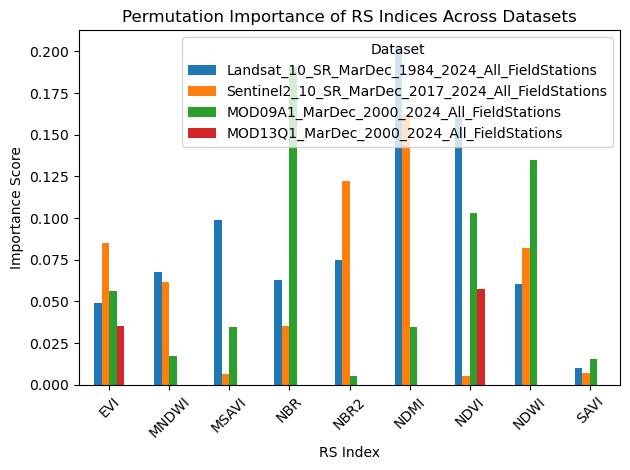

In [65]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# -----------------------------
# Paths to RS datasets
# -----------------------------
rs_files = [
    'Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
    'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
    'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
    'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv'
]

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# RS indices to evaluate
# -----------------------------
vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']

# -----------------------------
# Store permutation importance results
# -----------------------------
all_perm_importances = {}

# -----------------------------
# Loop through each RS dataset
# -----------------------------
for rs_file in rs_files:
    print(f"\n--- Processing {rs_file} ---")
    df = pd.read_csv(rs_file)
    
    # Keep only RS indices + Habitat
    available_cols = [c for c in vi_cols if c in df.columns]
    
    # Remove rows with missing Habitat
    df = df.dropna(subset=["Habitat"])
    
    if df.empty or len(df["Habitat"].unique()) < 2:
        print("⚠️ Not enough data or classes to train, skipping this dataset.")
        continue
    
    X = df[available_cols]
    y = df["Habitat"]
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Pipeline: Imputer + RF Classifier
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(n_estimators=500, random_state=42))
    ])
    
    pipeline.fit(X_train, y_train)
    
    # Evaluate accuracy
    acc = pipeline.score(X_test, y_test)
    cv_acc = cross_val_score(pipeline, X, y, cv=5, scoring="accuracy").mean()
    print(f"Test accuracy: {acc:.3f}, CV accuracy: {cv_acc:.3f}")
    
    # Permutation importance
    perm_result = permutation_importance(
        pipeline, X_test, y_test,
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )
    
    # perm_importances = pd.Series(perm_result.importances_mean, index=X.columns)
    perm_importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
    print("Permutation importance (higher = better at separating habitats):")
    print(perm_importances)

    all_perm_importances[rs_file] = perm_importances

# -----------------------------
# Combine all permutation importance into a DataFrame
# -----------------------------
perm_df = pd.DataFrame(all_perm_importances).fillna(0)

# -----------------------------
# Plot side-by-side for comparison
# -----------------------------
plt.figure(figsize=(12,6))
perm_df.plot(kind="bar")
plt.title("Permutation Importance of RS Indices Across Datasets")
plt.ylabel("Importance Score")
plt.xlabel("RS Index")
plt.xticks(rotation=45)
plt.legend([os.path.splitext(f)[0] for f in perm_df.columns], title="Dataset")
plt.tight_layout()
out_fp = os.path.join(save_folder, rs_file.replace(".csv", "_Imf.png"))
plt.savefig(out_fp, dpi=300)
plt.show()


--- Processing Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv ---
Test accuracy: 0.708, CV accuracy: 0.547
Permutation importance (higher = better at separating habitats):
NDMI     0.168016
NDVI     0.116162
NBR      0.070705
NBR2     0.066516
MSAVI    0.065808
MNDWI    0.039938
NDWI     0.029408
EVI      0.012822
SAVI     0.009256
dtype: float64

--- Processing Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv ---
Test accuracy: 0.735, CV accuracy: 0.538
Permutation importance (higher = better at separating habitats):
NDMI     0.151535
NBR2     0.102100
NDWI     0.086430
MNDWI    0.066074
EVI      0.056866
NBR      0.042165
NDVI    -0.001131
SAVI    -0.001616
MSAVI   -0.006785
dtype: float64

--- Processing MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv ---
Test accuracy: 0.712, CV accuracy: 0.529
Permutation importance (higher = better at separating habitats):
NBR      0.192000
NDWI     0.086870
NDVI     0.038652
MSAVI    0.026696
NDMI     0.021348
EVI      0.

<Figure size 1200x600 with 0 Axes>

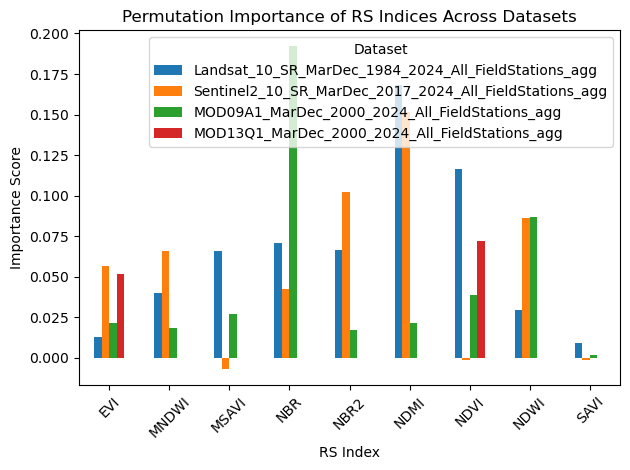

In [91]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# -----------------------------
# Paths to RS datasets
# -----------------------------
rs_files = [
    'Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
    'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
    'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
    'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv'
]

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# RS indices to evaluate
# -----------------------------
vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']

# -----------------------------
# Store permutation importance results
# -----------------------------
all_perm_importances = {}

# -----------------------------
# Loop through each RS dataset
# -----------------------------
for rs_file in rs_files:
    rs_file = rs_file.replace(".csv", "_agg.csv")
    print(f"\n--- Processing {rs_file} ---")
    df = pd.read_csv(rs_file)
    
    # Keep only RS indices + Habitat
    available_cols = [c for c in vi_cols if c in df.columns]
    
    # Remove rows with missing Habitat
    df = df.dropna(subset=["Habitat"])
    
    if df.empty or len(df["Habitat"].unique()) < 2:
        print("⚠️ Not enough data or classes to train, skipping this dataset.")
        continue
    
    X = df[available_cols]
    y = df["Habitat"]
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Pipeline: Imputer + RF Classifier
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(n_estimators=500, random_state=42))
    ])
    
    pipeline.fit(X_train, y_train)
    
    # Evaluate accuracy
    acc = pipeline.score(X_test, y_test)
    cv_acc = cross_val_score(pipeline, X, y, cv=5, scoring="accuracy").mean()
    print(f"Test accuracy: {acc:.3f}, CV accuracy: {cv_acc:.3f}")
    
    # Permutation importance
    perm_result = permutation_importance(
        pipeline, X_test, y_test,
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )
    
    # perm_importances = pd.Series(perm_result.importances_mean, index=X.columns)
    perm_importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
    print("Permutation importance (higher = better at separating habitats):")
    print(perm_importances)

    all_perm_importances[rs_file] = perm_importances

# -----------------------------
# Combine all permutation importance into a DataFrame
# -----------------------------
perm_df = pd.DataFrame(all_perm_importances).fillna(0)

# -----------------------------
# Plot side-by-side for comparison
# -----------------------------
plt.figure(figsize=(12,6))
perm_df.plot(kind="bar")
plt.title("Permutation Importance of RS Indices Across Datasets")
plt.ylabel("Importance Score")
plt.xlabel("RS Index")
plt.xticks(rotation=45)
plt.legend([os.path.splitext(f)[0] for f in perm_df.columns], title="Dataset")
plt.tight_layout()
out_fp = os.path.join(save_folder, rs_file.replace(".csv", "_Imf.png"))
plt.savefig(out_fp, dpi=300)
plt.show()

### Re-generated the plots

### Tree_cover removed dataset
- /Corrected_Indices/

In [78]:
rs_corr_fp = ['Corrected_Indices/Landsat10_corrected.csv',
              'Corrected_Indices/Sentinel2_corrected.csv',
              'Corrected_Indices/MOD09A1_corrected.csv', 
              'Corrected_Indices/MOD13Q1_corrected.csv']

In [85]:
save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

filename = os.path.splitext(os.path.basename(rs_corr_fp[0]))[0]
shortname = filename.split("_")[0]   # e.g., "Landsat10"
out_fp1 = os.path.join(save_folder, f"{shortname}_F_alive_FeatureImportance.png")
print(out_fp1)

out_fp2 = os.path.join(save_folder, os.path.basename(rs_corr_fp[0]).replace(".csv", "_PermutationImportance.png"))
print(out_fp2)

plots\Landsat10_F_alive_FeatureImportance.png
plots\Landsat10_corrected_PermutationImportance.png


Test accuracy: 0.708, CV accuracy: 0.547
Permutation importance (higher = better at separating habitats):
NDMI     0.168016
NDVI     0.116162
NBR      0.070705
NBR2     0.066516
MSAVI    0.065808
MNDWI    0.039938
NDWI     0.029408
EVI      0.012822
SAVI     0.009256
dtype: float64


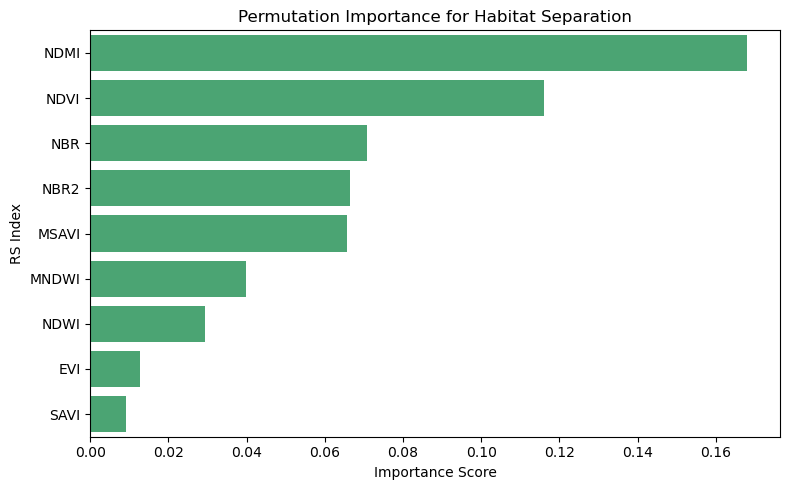

In [79]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# -----------------------------
# Load data
# -----------------------------
# local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
rs_fp = 'Corrected_Indices/Landsat10_corrected_agg.csv'  # 
df = pd.read_csv(rs_fp)

# Keep only indices + Habitat
vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']
available_cols = [c for c in vi_cols if c in df.columns]

# Remove rows with missing Habitat
df = df.dropna(subset=["Habitat"])

X = df[available_cols]
y = df["Habitat"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Pipeline: Imputer + RandomForestClassifier
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=500, random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# -----------------------------
# Evaluate classifier
# -----------------------------
acc = pipeline.score(X_test, y_test)
cv_acc = cross_val_score(pipeline, X, y, cv=5, scoring="accuracy").mean()
print(f"Test accuracy: {acc:.3f}, CV accuracy: {cv_acc:.3f}")

# -----------------------------
# Permutation importance
# -----------------------------
perm_result = permutation_importance(pipeline, X_test, y_test,
                                     n_repeats=10,
                                     random_state=42,
                                     n_jobs=-1)

perm_importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
print("Permutation importance (higher = better at separating habitats):")
print(perm_importances)

# -----------------------------
# Plot permutation importance
# -----------------------------
plt.figure(figsize=(8,5))
sns.barplot(x=perm_importances, y=perm_importances.index,
            color="mediumseagreen")
plt.title("Permutation Importance for Habitat Separation")
plt.xlabel("Importance Score")
plt.ylabel("RS Index")
plt.tight_layout()
plt.show()


In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import numpy as np
import os

# -----------------------------
# Paths
# -----------------------------
local_folder = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
field_fp = os.path.join(local_folder, 'Trophic survey data analysis_all_2016-2023_habitat.csv')

rs_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
         'Corrected_Indices/Sentinel2_corrected.csv',
         'Corrected_Indices/MOD09A1_corrected.csv', 
         'Corrected_Indices/MOD13Q1_corrected.csv']

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# Load field data
# -----------------------------
field_df = pd.read_csv(field_fp)
field_df["Year"] = field_df["Year"].astype(int)
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

# -----------------------------
# Loop through RS datasets
# -----------------------------
for rs_file in rs_fp:
    csv_file = rs_file.replace(".csv", "_agg.csv")
    print(f"\n--- Processing {csv_file} ---")
    
    rs_df = pd.read_csv(csv_file)
    
    # Standardize year
    if "year" in rs_df.columns:
        rs_df = rs_df.rename(columns={"year": "Year"})
    
    # Create Year_Season if needed
    if "Year_Season" not in rs_df.columns:
        rs_df["Year_Season"] = rs_df["Year"].astype(str) + "_" + rs_df["Season"]
    
    # Keep only available RS indices
    vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']
    available_cols = [c for c in vi_cols if c in rs_df.columns]
    
    # Merge with field data
    merged = pd.merge(field_df, rs_df, on=["Station", "Year_Season"], how="inner")
    print("Merged shape:", merged.shape)
    if merged.empty:
        print("No overlap found, skipping this dataset.")
        continue
    
    X = merged[available_cols]
    y = merged["F_veg"]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # -----------------------------
    # Random Forest + RandomizedSearchCV
    # -----------------------------
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(random_state=42))
    ])
    
    param_grid = {
        "rf__n_estimators": [200, 500, 800],
        "rf__max_depth": [None, 5, 10, 20],
        "rf__max_features": ["sqrt", "log2", 0.5, 0.8],
        "rf__min_samples_split": [2, 5, 10],
        "rf__min_samples_leaf": [1, 2, 4]
    }
    
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=30,
        scoring="r2",
        cv=5,
        n_jobs=-1,
        verbose=1,
        random_state=42
    )
    
    search.fit(X_train, y_train)
    
    best_model = search.best_estimator_
    print("Best params:", search.best_params_)
    
    y_pred = best_model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"Test RMSE: {rmse:.4f}, R²: {r2:.4f}")
    
    # -----------------------------
    # Permutation Importance
    # -----------------------------
    result = permutation_importance(best_model, X_test, y_test,
                                    n_repeats=10,
                                    random_state=42,
                                    n_jobs=-1)
    
    perm_importances = pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=False)
    print("Permutation Importance:\n", perm_importances)
    
    # -----------------------------
    # Plot Feature Importance
    # -----------------------------
    plt.figure(figsize=(8,5))
    sns.barplot(x=perm_importances, y=perm_importances.index, color="mediumseagreen")
    plt.title(f"Permutation Importance ({rs_file})")
    plt.xlabel("Importance Score")
    plt.ylabel("RS Index")
    plt.tight_layout() 
    out_fp = os.path.join(save_folder, os.path.basename(rs_file).replace(".csv", "_PermutationImportance.png"))
    plt.savefig(out_fp, dpi=300)
    # plt.show()
    plt.close()
    
    # -----------------------------
    # Observed vs Predicted
    # -----------------------------
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_test, y=y_pred)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
    plt.xlabel("Observed F_veg")
    plt.ylabel("Predicted F_veg")
    plt.title(f"Observed vs Predicted ({rs_file})")
    plt.tight_layout()
    out_fp = os.path.join(save_folder, os.path.basename(rs_file).replace(".csv", "_ObsVsPred.png"))
    plt.savefig(out_fp, dpi=300)
    # plt.show()
    plt.close()


--- Processing Corrected_Indices/Landsat10_corrected_agg.csv ---
Merged shape: (3513, 39)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'rf__n_estimators': 500, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_features': 0.5, 'rf__max_depth': None}
Test RMSE: 0.0621, R²: 0.6485
Permutation Importance:
 NDVI     0.822879
NBR2     0.219252
NDMI     0.204047
MSAVI    0.088687
SAVI     0.057578
MNDWI    0.056981
NDWI     0.056739
EVI      0.051770
NBR      0.050169
dtype: float64

--- Processing Corrected_Indices/Sentinel2_corrected_agg.csv ---
Merged shape: (2608, 39)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'rf__n_estimators': 500, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_features': 0.5, 'rf__max_depth': None}
Test RMSE: 0.0799, R²: 0.5221
Permutation Importance:
 EVI      0.143435
NBR2     0.111058
NDMI     0.063080
MSAVI    0.056446
NDVI     0.047821
MNDWI    0.043281
SAVI     0.0378


--- Processing Corrected_Indices/Landsat10_corrected_agg.csv ---
Merged shape: (3513, 39)
RMSE: 0.0256, R²: 0.5651, CV-R²: 0.3309


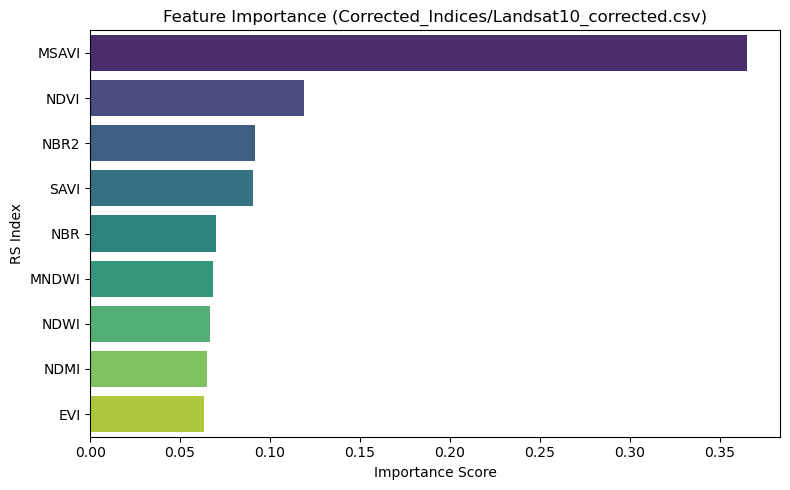

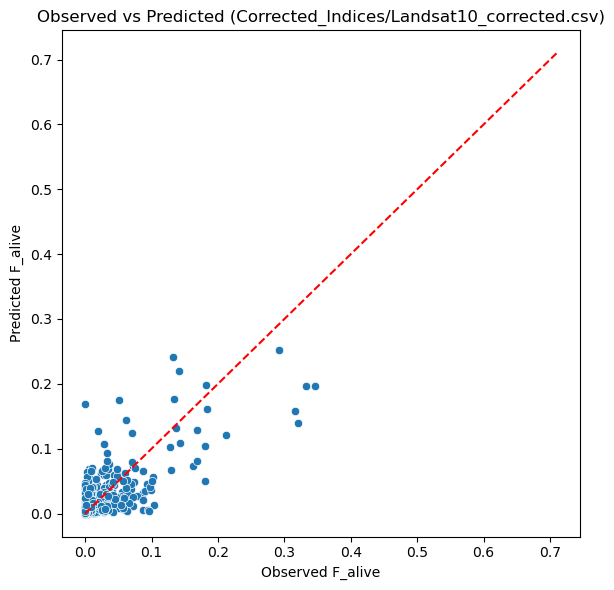


--- Processing Corrected_Indices/Sentinel2_corrected_agg.csv ---
Merged shape: (2608, 39)
RMSE: 0.0334, R²: 0.4327, CV-R²: 0.2255


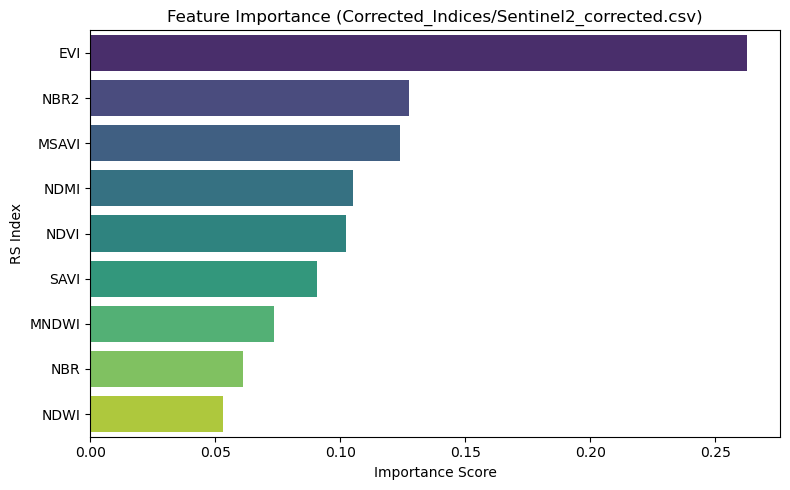

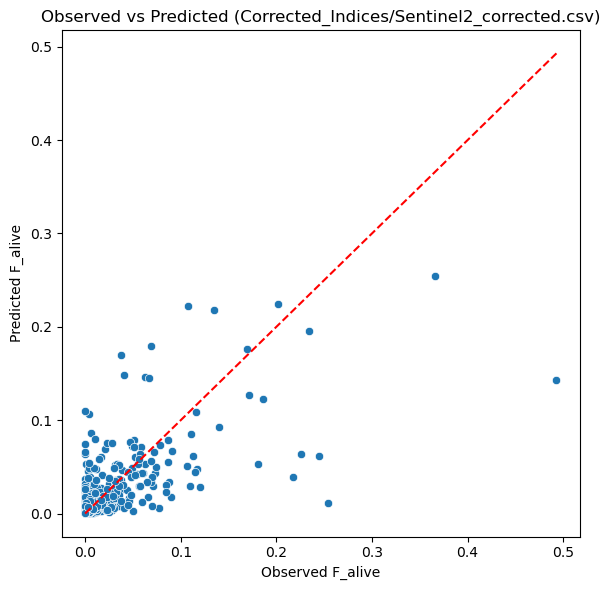


--- Processing Corrected_Indices/MOD09A1_corrected_agg.csv ---
Merged shape: (3536, 39)
RMSE: 0.0348, R²: 0.4252, CV-R²: 0.1622


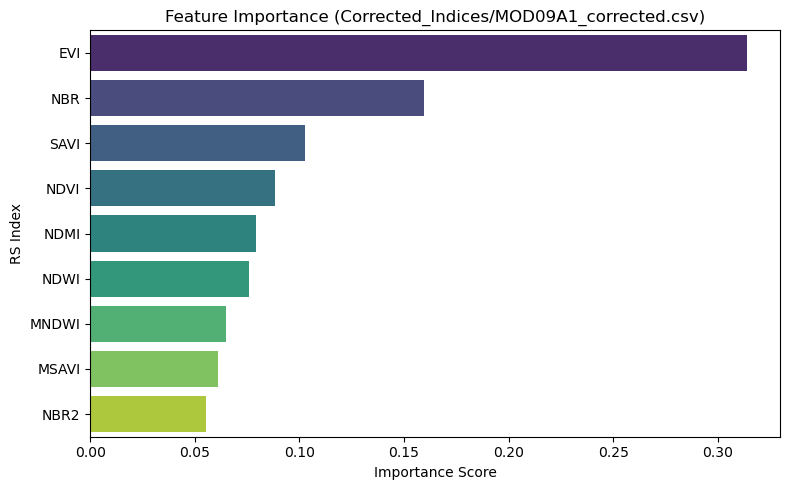

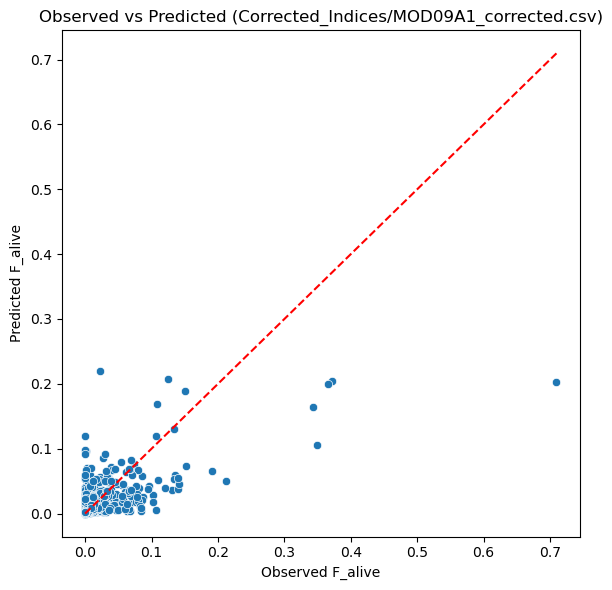


--- Processing Corrected_Indices/MOD13Q1_corrected_agg.csv ---
Merged shape: (3536, 25)
RMSE: 0.0350, R²: 0.4211, CV-R²: 0.0873


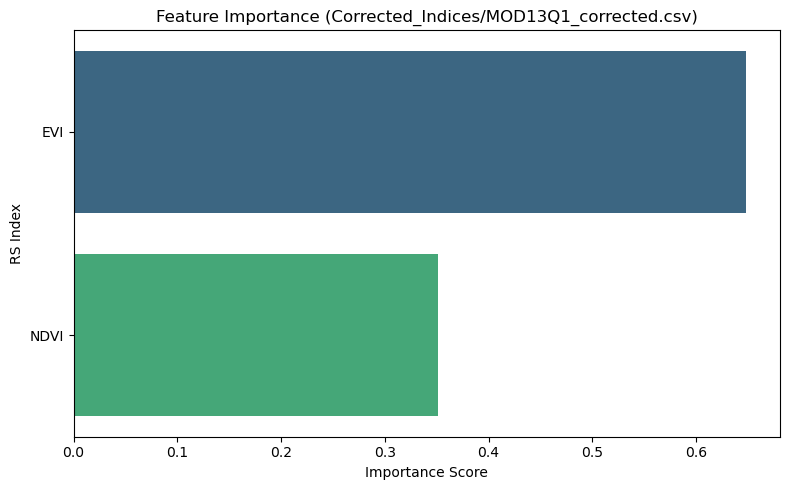

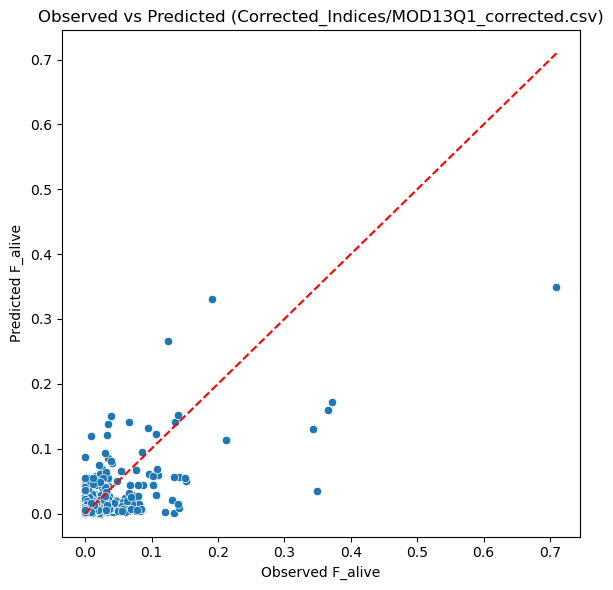

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import numpy as np
import os

# -----------------------------
# Paths
# -----------------------------
local_folder = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
local_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'
field_fp = os.path.join(local_folder, local_fp)

rs_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
         'Corrected_Indices/Sentinel2_corrected.csv',
         'Corrected_Indices/MOD09A1_corrected.csv', 
         'Corrected_Indices/MOD13Q1_corrected.csv']

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# Field data
# -----------------------------
field_df = pd.read_csv(field_fp)
field_df["Year"] = field_df["Year"].astype(int)
# Create a Year_Season column in field_df to match rs_df
field_df["Year_Season"] = field_df["Year"].astype(str) + "_" + field_df["Season"]

# -----------------------------
# Loop through RS datasets
# -----------------------------
for rs_file in rs_fp:
    csv_file = rs_file.replace(".csv", "_agg.csv")
    print(f"\n--- Processing {csv_file} ---")
    rs_df = pd.read_csv(csv_file)
    
    # Standardize naming
    rs_df = rs_df.rename(columns={"year": "Year"})
    
    # Keep only relevant cols
    vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']
    available_cols = [c for c in vi_cols if c in rs_df.columns]
    
    # rs_df = rs_df[["Year", "Season", "Habitat"] + available_cols]
    
    # Merge with field data
    merged = pd.merge(field_df, rs_df, on=["Station", "Year_Season"], how="inner")
    print("Merged shape:", merged.shape)
    if merged.empty:
        print("No overlap found, skipping this dataset.")
        continue
    
    # -----------------------------
    # Random Forest with Imputation
    # -----------------------------
    X = merged[available_cols]
    y = merged["F_alive"] #F_alive or F_veg
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Pipeline: Imputer + RF
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),  # fill NaNs with median
        ("rf", RandomForestRegressor(n_estimators=500, random_state=42))
    ])
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    cv_scores = cross_val_score(model, X, y, cv=5, scoring="r2")
    
    print(f"RMSE: {rmse:.4f}, R²: {r2:.4f}, CV-R²: {cv_scores.mean():.4f}")
    
    # -----------------------------
    # Feature Importance
    # -----------------------------
    rf = model.named_steps["rf"]  # get RF model from pipeline
    importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
    
    plt.figure(figsize=(8,5))
    sns.barplot(x=importances, y=importances.index, hue=importances.index,
                palette="viridis", dodge=False, legend=False)
    plt.title(f"Feature Importance ({rs_file})")
    plt.xlabel("Importance Score")
    plt.ylabel("RS Index")
    plt.tight_layout()
    out_fp = os.path.join(save_folder, os.path.basename(csv_file).replace(".csv", "_F_alive_FeatureImportance.png"))
    plt.savefig(out_fp, dpi=300)
    plt.show()
    plt.close()

    # -----------------------------
    # Observed vs Predicted
    # -----------------------------
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_test, y=y_pred)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
    plt.xlabel("Observed F_alive") #F_alive or F_veg
    plt.ylabel("Predicted F_alive") #F_alive or F_veg
    plt.title(f"Observed vs Predicted ({rs_file})")
    plt.tight_layout()
    out_fp = os.path.join(save_folder, os.path.basename(csv_file).replace(".csv", "_F_alive_ObsVsPred.png"))
    plt.savefig(out_fp, dpi=300)
    plt.show()
    plt.close()



--- Processing Corrected_Indices/Landsat10_corrected_agg.csv ---
Test accuracy: 0.708, CV accuracy: 0.547
Permutation importance (higher = better at separating habitats):
NDMI     0.168016
NDVI     0.116162
NBR      0.070705
NBR2     0.066516
MSAVI    0.065808
MNDWI    0.039938
NDWI     0.029408
EVI      0.012822
SAVI     0.009256
dtype: float64

--- Processing Corrected_Indices/Sentinel2_corrected_agg.csv ---
Test accuracy: 0.735, CV accuracy: 0.538
Permutation importance (higher = better at separating habitats):
NDMI     0.151535
NBR2     0.102100
NDWI     0.086430
MNDWI    0.066074
EVI      0.056866
NBR      0.042165
NDVI    -0.001131
SAVI    -0.001616
MSAVI   -0.006785
dtype: float64

--- Processing Corrected_Indices/MOD09A1_corrected_agg.csv ---
Test accuracy: 0.712, CV accuracy: 0.529
Permutation importance (higher = better at separating habitats):
NBR      0.192000
NDWI     0.086870
NDVI     0.038652
MSAVI    0.026696
NDMI     0.021348
EVI      0.021174
MNDWI    0.018087
NBR2  

<Figure size 1200x600 with 0 Axes>

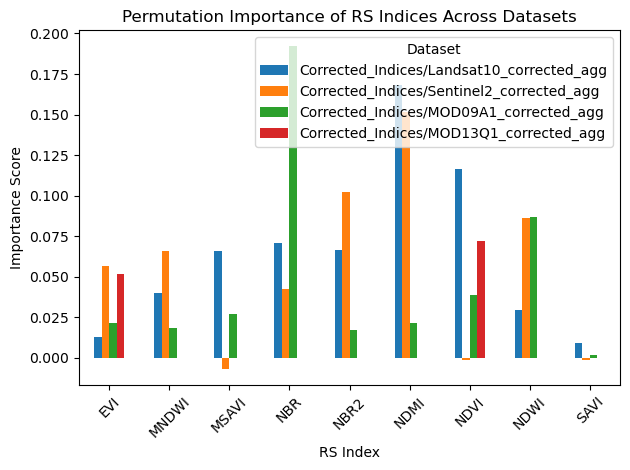

In [89]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# -----------------------------
# Paths to RS datasets
# -----------------------------
rs_files = ['Corrected_Indices/Landsat10_corrected_agg.csv', 
            'Corrected_Indices/Sentinel2_corrected_agg.csv',
            'Corrected_Indices/MOD09A1_corrected_agg.csv', 
            'Corrected_Indices/MOD13Q1_corrected_agg.csv']

save_folder = "plots"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# RS indices to evaluate
# -----------------------------
vi_cols = ['EVI','MNDWI','MSAVI','NBR','NBR2','NDMI','NDVI','NDWI','SAVI']

# -----------------------------
# Store permutation importance results
# -----------------------------
all_perm_importances = {}

# -----------------------------
# Loop through each RS dataset
# -----------------------------
for rs_file in rs_files:
    print(f"\n--- Processing {rs_file} ---")
    df = pd.read_csv(rs_file)
    
    # Keep only RS indices + Habitat
    available_cols = [c for c in vi_cols if c in df.columns]
    
    # Remove rows with missing Habitat
    df = df.dropna(subset=["Habitat"])
    
    if df.empty or len(df["Habitat"].unique()) < 2:
        print("Not enough data or classes to train, skipping this dataset.")
        continue
    
    X = df[available_cols]
    y = df["Habitat"]
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Pipeline: Imputer + RF Classifier
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(n_estimators=500, random_state=42))
    ])
    
    pipeline.fit(X_train, y_train)
    
    # Evaluate accuracy
    acc = pipeline.score(X_test, y_test)
    cv_acc = cross_val_score(pipeline, X, y, cv=5, scoring="accuracy").mean()
    print(f"Test accuracy: {acc:.3f}, CV accuracy: {cv_acc:.3f}")
    
    # Permutation importance
    perm_result = permutation_importance(
        pipeline, X_test, y_test,
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )
    
    # perm_importances = pd.Series(perm_result.importances_mean, index=X.columns)
    perm_importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
    print("Permutation importance (higher = better at separating habitats):")
    print(perm_importances)

    all_perm_importances[rs_file] = perm_importances

# -----------------------------
# Combine all permutation importance into a DataFrame
# -----------------------------
perm_df = pd.DataFrame(all_perm_importances).fillna(0)

# -----------------------------
# Plot side-by-side for comparison
# -----------------------------
plt.figure(figsize=(12,6))
perm_df.plot(kind="bar")
plt.title("Permutation Importance of RS Indices Across Datasets")
plt.ylabel("Importance Score")
plt.xlabel("RS Index")
plt.xticks(rotation=45)
plt.legend([os.path.splitext(f)[0] for f in perm_df.columns], title="Dataset")
plt.tight_layout()
out_fp = os.path.join(save_folder, os.path.basename(csv_file).replace(".csv", "_Imf.png"))
plt.savefig(out_fp, dpi=300)
plt.show()


### Old version- discarded: Aggregated rs df

In [74]:
# Field data
local_folder = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
csv_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'

# Remote sensing data (generated from 'GEE demo.ipynb')
rs_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
         'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
         'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
         'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv']

rs_agg_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv',
             'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv',
             'MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv',
             'MOD13Q1_MarDec_2000_2024_All_FieldStations_agg.csv']

# corr_folder = '/Corrected_Indices/'
rs_corr_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
              'Corrected_Indices/Sentinel2_corrected.csv',
              'Corrected_Indices/MOD09A1_corrected.csv', 
              'Corrected_Indices/MOD13Q1_corrected.csv']

rs_corr_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
              'Corrected_Indices/Sentinel2_corrected.csv',
              'Corrected_Indices/MOD09A1_corrected.csv', 
              'Corrected_Indices/MOD13Q1_corrected.csv']

In [51]:
sta_df = pd.read_csv(local_foler + csv_fp)
rs_df1 = pd.read_csv(rs_agg_fp[0])
rs_df2 = pd.read_csv(rs_agg_fp[1])
rs_df3 = pd.read_csv(rs_agg_fp[2])
rs_df4 = pd.read_csv(rs_agg_fp[3])

In [8]:
sta_df.head()

,Station,Lat,Lon,Year,Season,Alive,Dead,Ground,Unknown,Sum.not.unknown,GridSize,F_alive,F_dead,F_veg,F_ground,Habitat
0,ALBALF1,33.20027,-4.03529,2016,Spring,1,5,354,0,360,360,0.002778,0.013889,0.016667,0.983333,Macrochloa steppe
1,ALBALF1,33.20027,-4.03529,2016,Summer,1,8,350,1,359,360,0.002786,0.022284,0.025070,0.974930,Macrochloa steppe
2,ALBALF1,33.20027,-4.03529,2016,Fall,0,14,342,4,356,360,0.000000,0.039326,0.039326,0.960674,Macrochloa steppe
3,ALBALF1,33.20027,-4.03529,2016,Winter,0,6,354,0,360,360,0.000000,0.016667,0.016667,0.983333,Macrochloa steppe
4,ALBALF1,33.20027,-4.03529,2017,Spring,3,7,700,10,710,720,0.004225,0.009859,0.014085,0.985915,Macrochloa steppe


In [52]:
rs_df1.head()

,Station,Season,Year_Season,Habitat,EVI,MNDWI,MSAVI,NBR,NBR2,NDMI,NDVI,NDWI,SAVI,year
0,ALBALF1,Fall,1984_Fall,Macrochloa steppe,0.088245,-0.369274,0.091272,-0.028706,0.098450,-0.126798,0.107373,-0.254537,0.095548,1984.0
1,ALBALF1,Spring,1984_Spring,Macrochloa steppe,0.084098,-0.384143,0.092803,-0.006194,0.116976,-0.123081,0.105065,-0.274018,0.096161,1984.0
2,ALBALF1,Summer,1984_Summer,Macrochloa steppe,0.093934,-0.394963,0.102712,-0.031509,0.098031,-0.129135,0.118101,-0.280152,0.106816,1984.0
3,ALBALF1,Fall,1985_Fall,Macrochloa steppe,0.085152,-0.394988,0.092170,0.001522,0.133326,-0.131879,0.113672,-0.277542,0.097634,1985.0
4,ALBALF1,Spring,1985_Spring,Macrochloa steppe,0.088786,-0.409110,0.095957,-0.029933,0.113077,-0.142528,0.115259,-0.283088,0.100996,1985.0


In [76]:
import pandas as pd

# Your CSV files
infp = [
    'Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
    'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
    'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
    'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv'
]

rs_corr_fp = ['Corrected_Indices/Landsat10_corrected.csv', 
              'Corrected_Indices/Sentinel2_corrected.csv',
              'Corrected_Indices/MOD09A1_corrected.csv', 
              'Corrected_Indices/MOD13Q1_corrected.csv']

# Define a helper to map month → season
def month_to_season(month):
    if month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Fall"
    else:
        return "Winter"

for csv_file in rs_corr_fp: #infp or rs_corr_fp
    # Load data
    df = pd.read_csv(csv_file, parse_dates=["date"])
    
    # Extract year and season
    df["year"] = df["date"].dt.year
    df["Season"] = df["date"].dt.month.map(month_to_season)
    df["Year_Season"] = df["year"].astype(str) + "_" + df["Season"]
    
    # Select numeric indices automatically (instead of hardcoding)
    numeric_cols = df.select_dtypes(include="number").columns.tolist()
    indices = [c for c in numeric_cols if c not in ["Lat", "Lon"]]  # drop coords if not needed
    
    # Group and aggregate
    df_result = (
        df.groupby(["Station", "year", "Season", "Year_Season", "Habitat"], as_index=False)[indices]
        .mean()
    )
    
    # Export
    output_csv = csv_file.replace(".csv", "_agg.csv")
    df_result.to_csv(output_csv, index=False)
    print(f"Aggregated averages saved to: {output_csv}")

Aggregated averages saved to: Corrected_Indices/Landsat10_corrected_agg.csv
Aggregated averages saved to: Corrected_Indices/Sentinel2_corrected_agg.csv
Aggregated averages saved to: Corrected_Indices/MOD09A1_corrected_agg.csv
Aggregated averages saved to: Corrected_Indices/MOD13Q1_corrected_agg.csv


In [35]:
infp = [
    'Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv',
    'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv',
    'MOD09A1_MarDec_2000_2024_All_FieldStations.csv',
    'MOD13Q1_MarDec_2000_2024_All_FieldStations.csv'
]

for csv_file in rs_fp:
    df1 = pd.read_csv(csv_file)
    print(f"The shape of this {csv_file} is {df1.shape}.")
    output_csv = csv_file.replace(".csv", "_Sorted.csv")
    df2 = pd.read_csv(output_csv)
    print(f"The shape of this {output_csv} is {df2.shape}.")
    output_csv = csv_file.replace(".csv", "_agg.csv")
    df3 = pd.read_csv(output_csv)
    print(f"The shape of this {output_csv} is {df3.shape}.")

The shape of this Landsat_10_SR_MarDec_1984_2024_All_FieldStations.csv is (109296, 16).
The shape of this Landsat_10_SR_MarDec_1984_2024_All_FieldStations_Sorted.csv is (161376, 13).
The shape of this Landsat_10_SR_MarDec_1984_2024_All_FieldStations_agg.csv is (17661, 14).
The shape of this Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations.csv is (36079, 16).
The shape of this Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_Sorted.csv is (6144, 13).
The shape of this Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_agg.csv is (3091, 14).
The shape of this MOD09A1_MarDec_2000_2024_All_FieldStations.csv is (108492, 16).
The shape of this MOD09A1_MarDec_2000_2024_All_FieldStations_Sorted.csv is (60000, 13).
The shape of this MOD09A1_MarDec_2000_2024_All_FieldStations_agg.csv is (11500, 14).
The shape of this MOD13Q1_MarDec_2000_2024_All_FieldStations.csv is (54569, 9).
The shape of this MOD13Q1_MarDec_2000_2024_All_FieldStations_Sorted.csv is (60000, 6).
The shape of this MOD13Q1_Ma

In [77]:
for csv_file in rs_corr_fp:
    df1 = pd.read_csv(csv_file)
    print(f"The shape of this {csv_file} is {df1.shape}.")
    output_csv = csv_file.replace(".csv", "_agg.csv")
    df3 = pd.read_csv(output_csv)
    print(f"The shape of this {output_csv} is {df3.shape}.")
    

The shape of this Corrected_Indices/Landsat10_corrected.csv is (109296, 26).
The shape of this Corrected_Indices/Landsat10_corrected_agg.csv is (17661, 24).
The shape of this Corrected_Indices/Sentinel2_corrected.csv is (36079, 26).
The shape of this Corrected_Indices/Sentinel2_corrected_agg.csv is (3091, 24).
The shape of this Corrected_Indices/MOD09A1_corrected.csv is (108492, 26).
The shape of this Corrected_Indices/MOD09A1_corrected_agg.csv is (11500, 24).
The shape of this Corrected_Indices/MOD13Q1_corrected.csv is (54569, 12).
The shape of this Corrected_Indices/MOD13Q1_corrected_agg.csv is (11500, 10).


### Discarded! Correlation and linear regression analysis

In [46]:
# Field data
local_foler = 'C:/Users/PangY/OneDrive - Smithsonian Institution/Bustard/01_Data/Reneco/Vegetation Cover and Food Availability Studies/'
csv_fp = 'Trophic survey data analysis_all_2016-2023_habitat.csv'

# Remote sensing data (generated from 'GEE demo.ipynb')
rs_fp = ['Landsat_10_SR_MarDec_1984_2024_All_FieldStations_sorted.csv',
         'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_sorted.csv',
         'MOD09A1_MarDec_2000_2024_All_FieldStations_sorted.csv',
         'MOD13Q1_MarDec_2000_2024_All_FieldStations_sorted.csv']

In [37]:
# Load field data
df = pd.read_csv(local_foler + csv_fp)
df.head()

,Station,Lat,Lon,Year,Season,Alive,Dead,Ground,Unknown,Sum.not.unknown,GridSize,F_alive,F_dead,F_veg,F_ground,Habitat
0,ALBALF1,33.20027,-4.03529,2016,Spring,1,5,354,0,360,360,0.002778,0.013889,0.016667,0.983333,Macrochloa steppe
1,ALBALF1,33.20027,-4.03529,2016,Summer,1,8,350,1,359,360,0.002786,0.022284,0.025070,0.974930,Macrochloa steppe
2,ALBALF1,33.20027,-4.03529,2016,Fall,0,14,342,4,356,360,0.000000,0.039326,0.039326,0.960674,Macrochloa steppe
3,ALBALF1,33.20027,-4.03529,2016,Winter,0,6,354,0,360,360,0.000000,0.016667,0.016667,0.983333,Macrochloa steppe
4,ALBALF1,33.20027,-4.03529,2017,Spring,3,7,700,10,710,720,0.004225,0.009859,0.014085,0.985915,Macrochloa steppe


In [47]:
# Load remote sensing data
df1 = pd.read_csv(rs_fp[0])
df2 = pd.read_csv(rs_fp[1])
df3 = pd.read_csv(rs_fp[2])
df4 = pd.read_csv(rs_fp[3])

In [48]:
df1.head()

,year,Season,Year_Season,Habitat,EVI,MNDWI,MSAVI,NBR,NBR2,NDMI,NDVI,NDWI,SAVI
0,1984,Spring,1984 Spring,Alluvial spread area,0.070014,-0.344109,0.076334,-0.044523,0.047797,-0.093383,0.086290,-0.252857,0.079163
1,1984,Spring,1984 Spring,Gully,0.074049,-0.364926,0.078313,-0.058145,0.059492,-0.117277,0.092679,-0.245979,0.082131
2,1984,Spring,1984 Spring,Macrochloa steppe,0.081285,-0.383745,0.086407,-0.070246,0.053946,-0.123736,0.108747,-0.272993,0.092074
3,1984,Spring,1984 Spring,Reg,0.074281,-0.370574,0.080291,-0.045479,0.063234,-0.110451,0.094765,-0.255203,0.084271
4,1984,Spring,1984 Spring,Salty steppe,0.068283,-0.315275,0.073657,-0.023927,0.060812,-0.082373,0.081270,-0.236716,0.075805


In [51]:
import pandas as pd
import statsmodels.api as sm

# --- Field survey data ---
field_csv = 'Trophic survey data analysis_all_2016-2023_habitat.csv'
field_df = pd.read_csv(field_csv)

# Filter for analysis years
field_df = field_df[field_df['Year'].isin([2016, 2023])]

# --- RS datasets ---
rs_files = [
    'Landsat_10_SR_MarDec_1984_2024_All_FieldStations_sorted.csv',
    'Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_sorted.csv',
    'MOD09A1_MarDec_2000_2024_All_FieldStations_sorted.csv',
    # 'MOD13Q1_MarDec_2000_2024_All_FieldStations_sorted.csv'
]

# RS indices of interest
indices = ['EVI', 'MNDWI','MSAVI', 'NBR', 'NBR2', 'NDMI', 'NDVI', 'NDWI', 'SAVI']

# Loop through RS files
for rs_file in rs_files:
    # Load RS data
    rs_df = pd.read_csv(rs_file)
    
    # Filter for analysis years
    rs_df = rs_df[rs_df['year'].isin([2016, 2023])]
    
    # Merge with field data on Year/Season/Habitat
    merged_df = pd.merge(
        field_df,
        rs_df[['year', 'Season', 'Habitat'] + indices],
        left_on=['Year', 'Season', 'Habitat'],
        right_on=['year', 'Season', 'Habitat'],
        how='inner'
    )
    
    # --- Correlation analysis ---
    corr_matrix = merged_df[indices + ['F_alive']].corr()
    corr_with_F_alive = corr_matrix['F_alive'].sort_values(ascending=False)
    
    # Export correlation to CSV
    output_corr_csv = rs_file.replace('.csv', '_Falive_correlation.csv')
    corr_with_F_alive.to_csv(output_corr_csv, header=True)
    
    print(f"\n--- {rs_file} ---")
    print("Correlation with F_alive:\n", corr_with_F_alive)
    
    # --- Optional: Linear regression ---
   # Keep only the relevant columns and drop missing or infinite values
X = merged_df[indices]
y = merged_df['F_alive']

# Remove rows with NaN or inf
mask = X.replace([np.inf, -np.inf], np.nan).notna().all(axis=1) & y.notna()
X_clean = X[mask]
y_clean = y[mask]

# Add constant for intercept
X_clean = sm.add_constant(X_clean)

# Fit the OLS model
model = sm.OLS(y_clean, X_clean).fit()
print(model.summary())



--- Landsat_10_SR_MarDec_1984_2024_All_FieldStations_sorted.csv ---
Correlation with F_alive:
 F_alive    1.000000
EVI        0.157512
MSAVI      0.157025
SAVI       0.151976
NDMI       0.132909
NDVI       0.122831
NBR        0.109002
NBR2       0.091564
MNDWI      0.068433
NDWI      -0.107009
Name: F_alive, dtype: float64

--- Sentinel2_10_SR_MarDec_2017_2024_All_FieldStations_sorted.csv ---
Correlation with F_alive:
 F_alive    1.000000
NDWI       0.121485
NBR2       0.094006
MNDWI      0.073560
NBR        0.025619
EVI        0.023036
MSAVI     -0.028306
SAVI      -0.030322
NDVI      -0.030327
NDMI      -0.108396
Name: F_alive, dtype: float64

--- MOD09A1_MarDec_2000_2024_All_FieldStations_sorted.csv ---
Correlation with F_alive:
 F_alive    1.000000
NDMI       0.085598
MSAVI      0.071293
NBR        0.059276
SAVI       0.053769
MNDWI      0.048018
EVI        0.044575
NDVI      -0.000991
NDWI      -0.023829
NBR2      -0.049798
Name: F_alive, dtype: float64
                          

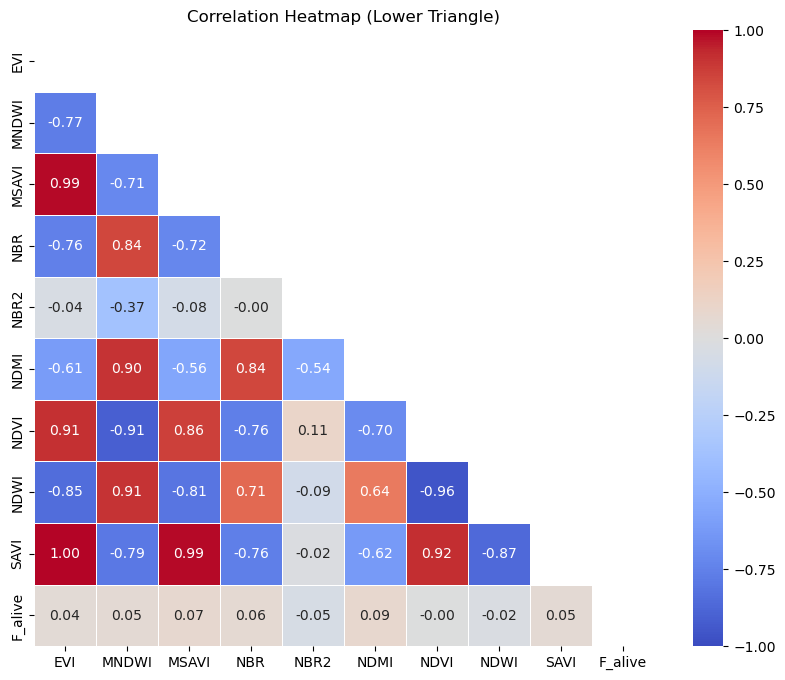

In [53]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Select RS indices + F_alive
corr_data = merged_df[indices + ['F_alive']]

# Drop NaN or inf values
corr_data = corr_data.replace([np.inf, -np.inf], np.nan).dropna()

# Compute correlation matrix
corr_matrix = corr_data.corr()

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # True for upper triangle

# Plot heatmap with mask
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,           # hide upper triangle
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title('Correlation Heatmap (Lower Triangle)')
plt.show()


# II. Veg resources with Field & VI metrics
- the Bustard Occurance data are in shp 'Houbara_Count_Stand_Dissolve.shp'
- the RS indices values were extracted to the Occurance points, and the resutls were saved to 'Landsat_10_SR_MarDec_1984_2024_BustardPoint.csv' etc
- 

In [64]:
import geopandas as gpd
import pandas as pd

# Load shapefile
occ_shp = gpd.read_file("Houbara_Count_Stand_Dissolve.shp")

index_fp = ['Landsat_10_SR_MarDec_1984_2024_BustardPoint.csv',
            'Sentinel2_10_SR_MarDec_2017_2024_BustardPoint.csv',
            'MOD09A1_MarDec_2000_2024_BustardPoint.csv',
            'MOD13Q1_MarDec_2000_2024_BustardPoint.csv']

names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']
merged_dfs = [pd.read_csv(f'Corrected_Indices/{name}_corrected_merged.csv') for name in names]

# Print sizes
for name, df in zip(names, merged_dfs):
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

Landsat: 3300 rows × 26 columns
Sentinel2: 2510 rows × 26 columns
MOD09A1: 3536 rows × 26 columns
MOD13Q1: 3536 rows × 19 columns


Landsat: 3300 rows × 26 columns
Sentinel2: 2510 rows × 26 columns
MOD09A1: 3536 rows × 26 columns
MOD13Q1: 3536 rows × 19 columns


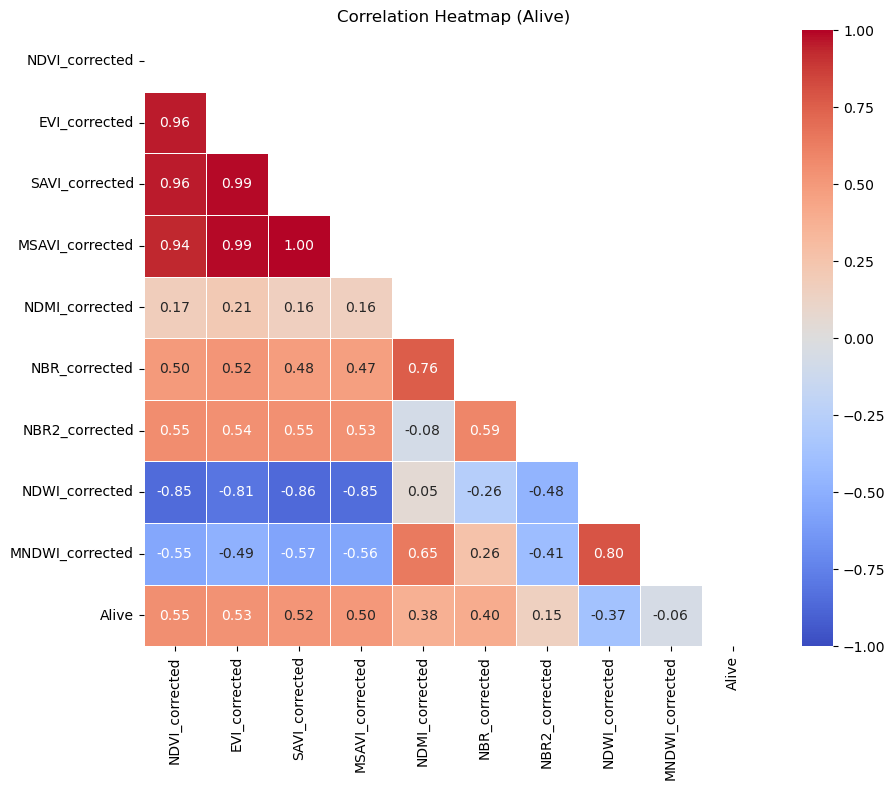

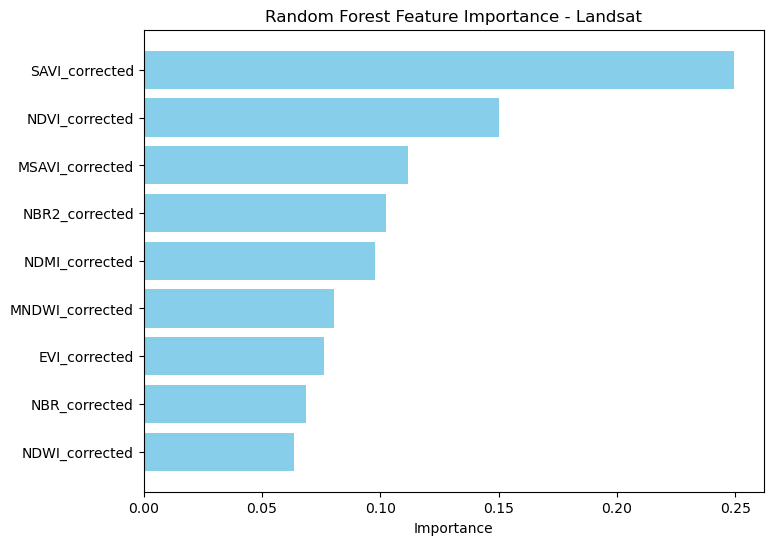

In [66]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# -------------------------------
# 1. Load data
# -------------------------------
# Occurrence shapefile
occ_shp = gpd.read_file("Houbara_Count_Stand_Dissolve.shp")

# RS indices CSVs
names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']
merged_dfs = [pd.read_csv(f'Corrected_Indices/{name}_corrected_merged.csv') for name in names]

# Print basic info
for name, df in zip(names, merged_dfs):
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")
    # print(df.head(1))  # first line

# -------------------------------
# 2. Prepare field and RS data
# -------------------------------
# Example: create GeoDataFrame from vegetation station
def df_to_gdf(df, lat_col='Lat', lon_col='Lon', crs="EPSG:4326"):
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df[lon_col], df[lat_col]), crs=crs)

gdfs = [df_to_gdf(df) for df in merged_dfs]

# -------------------------------
# 3. Correlation heatmap function
# -------------------------------
def plot_corr_heatmap(df, field_col='Alive', rs_indices=None):
    if rs_indices is None:
        rs_indices = [c for c in df.columns if c.endswith('_corrected')]
    corr_data = df[rs_indices + [field_col]].replace([np.inf, -np.inf], np.nan).dropna()
    corr_matrix = corr_data.corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    plt.figure(figsize=(10,8))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
                cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
    plt.title(f'Correlation Heatmap ({field_col})')
    plt.show()
    
    return corr_matrix

# Example: run correlation for Landsat
land_corr = plot_corr_heatmap(merged_dfs[0], field_col='Alive')

# -------------------------------
# 4. Random Forest feature importance
# -------------------------------
def rf_index_importance(df, field_col='Alive', rs_indices=None, satellite_name='RS',
                        test_size=0.3, random_state=42, n_estimators=500):
    if rs_indices is None:
        rs_indices = [c for c in df.columns if c.endswith('_corrected')]
    df_clean = df.dropna(subset=[field_col]+rs_indices)
    
    X = df_clean[rs_indices].values
    y = df_clean[field_col].values
    
    X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                        test_size=test_size,
                                                        random_state=random_state)
    rf = RandomForestRegressor(n_estimators=n_estimators, random_state=random_state, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    y_train_pred = rf.predict(X_train)
    y_test_pred = rf.predict(X_test)
    
    metrics = {
        'R2_train': r2_score(y_train, y_train_pred),
        'R2_test': r2_score(y_test, y_test_pred),
        'RMSE_train': mean_squared_error(y_train, y_train_pred, squared=False),
        'RMSE_test': mean_squared_error(y_test, y_test_pred, squared=False)
    }
    
    importance_df = pd.DataFrame({
        'Index': rs_indices,
        'Importance': rf.feature_importances_
    }).sort_values('Importance', ascending=False).reset_index(drop=True)
    
    # Plot
    plt.figure(figsize=(8,6))
    plt.barh(importance_df['Index'], importance_df['Importance'], color='skyblue')
    plt.gca().invert_yaxis()
    plt.xlabel('Importance')
    plt.title(f'Random Forest Feature Importance - {satellite_name}')
    plt.show()
    
    return importance_df, rf, metrics

# Example: Landsat
rf_index_importance(merged_dfs[0], field_col='Alive', satellite_name='Landsat')

# -------------------------------
# 5. Extract RS values at occurrence points
# -------------------------------
def attach_nearest_station(occ_gdf, station_gdf, projected_epsg=None):
    """
    Attach the nearest station attributes to occurrence points.

    Parameters
    ----------
    occ_gdf : GeoDataFrame
        Occurrence points with geometry column.
    station_gdf : GeoDataFrame
        Station points with geometry column.
    projected_epsg : int, optional
        EPSG code for projected CRS (meters). If None, will try to auto-select UTM zone.

    Returns
    -------
    merged_gdf : GeoDataFrame
        Occurrence points with nearest station attributes attached.
    nearest_idx_series : pd.Series
        Index of nearest station for each occurrence point.
    """
    # Ensure CRS are set
    if occ_gdf.crs is None or station_gdf.crs is None:
        raise ValueError("Both occ_gdf and station_gdf must have a CRS set.")

    # Auto-detect UTM zone if projected_epsg not provided
    if projected_epsg is None:
        # Approximate center longitude of occurrence points
        center_lon = occ_gdf.geometry.x.mean()
        utm_zone = int((center_lon + 180) // 6) + 1
        hemisphere = '326' if occ_gdf.geometry.y.mean() >= 0 else '327'
        projected_epsg = int(f"{hemisphere}{utm_zone:02d}")
        print(f"Reprojecting to EPSG:{projected_epsg} for distance calculation.")

    # Reproject to projected CRS for accurate distance calculations
    occ_proj = occ_gdf.to_crs(epsg=projected_epsg)
    station_proj = station_gdf.to_crs(epsg=projected_epsg)

    # Compute nearest station index
    nearest_idx = occ_proj.geometry.apply(lambda p: station_proj.distance(p).idxmin())

    # Merge attributes from station
    merged_gdf = occ_proj.merge(
        station_proj.drop(columns='geometry'),
        left_on=nearest_idx,
        right_index=True,
        suffixes=('_occ', '_station')
    )

    # Optionally convert back to original CRS
    merged_gdf = merged_gdf.to_crs(occ_gdf.crs)

    return merged_gdf, nearest_idx

# -------------------------------
# 6. Threshold / preferred range analysis
# -------------------------------


In [18]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point

# Step 1: Load data
# Load bustard occurrence shapefile
occ_shp = gpd.read_file("Houbara_Count_Stand_Dissolve.shp")

# Load station/spectral data (merged CSVs per satellite)
names = ['Landsat', 'Sentinel2', 'MOD09A1', 'MOD13Q1']
merged_dfs = [pd.read_csv(f'Corrected_Indices/{name}_corrected_merged.csv') for name in names]

# Convert station data to GeoDataFrames
station_gdfs = []
for df in merged_dfs:
    gdf = gpd.GeoDataFrame(
        df, geometry=gpd.points_from_xy(df['Lon'], df['Lat']), crs="EPSG:4326"
    )
    station_gdfs.append(gdf)

# Check sizes
for name, df in zip(names, merged_dfs):
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")


Landsat: 3300 rows × 26 columns
Sentinel2: 2510 rows × 26 columns
MOD09A1: 3536 rows × 26 columns
MOD13Q1: 3536 rows × 19 columns


In [75]:
# Step 2: Attach nearest station to occurrence points
def attach_nearest_station(occ_gdf, station_gdf, projected_epsg=None):
    """
    Attach the nearest station to each occurrence feature.
    Works for polygon or point occurrence geometries.
    """
    # If no projected CRS is provided, estimate UTM zone from mean longitude
    if projected_epsg is None:
        # Use the mean longitude of all points
        lon_mean = occ_gdf.geometry.bounds[['minx', 'maxx']].mean().mean()
        lat_mean = occ_gdf.geometry.bounds[['miny', 'maxy']].mean().mean()
        hemisphere = '326' if lat_mean >= 0 else '327'
        utm_zone = int((lon_mean + 180) // 6) + 1
        projected_epsg = int(f"{hemisphere}{utm_zone:02d}")

    # Project both GeoDataFrames
    occ_proj = occ_gdf.to_crs(epsg=projected_epsg).copy()
    station_proj = station_gdf.to_crs(epsg=projected_epsg).copy()

    # If occurrences are polygons, compute centroids
    if not occ_proj.geometry.geom_type.isin(['Point']).all():
        occ_proj['geometry'] = occ_proj.geometry.centroid

    # Compute nearest station
    nearest_idx = occ_proj.geometry.apply(lambda p: station_proj.distance(p).idxmin())

    # Merge attributes from nearest station
    merged_gdf = occ_proj.merge(
        station_proj.drop(columns='geometry'),
        left_on=nearest_idx,
        right_index=True,
        suffixes=('_occ', '_station')
    )

    # Return to original CRS
    merged_gdf = merged_gdf.to_crs(occ_gdf.crs)
    return merged_gdf, nearest_idx

# Attach for all satellites
occ_with_stations = {} 
for name, station_gdf in zip(names, station_gdfs):
    merged, nearest_idx = attach_nearest_station(occ_shp, station_gdf)
    occ_with_stations[name] = merged
    print(f"{name}: {merged.shape[0]} occurrence points linked to stations")

Landsat: 1904 occurrence points linked to stations
Sentinel2: 1904 occurrence points linked to stations
MOD09A1: 1904 occurrence points linked to stations
MOD13Q1: 1904 occurrence points linked to stations


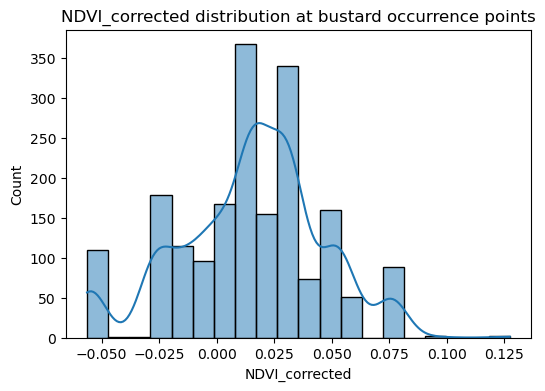

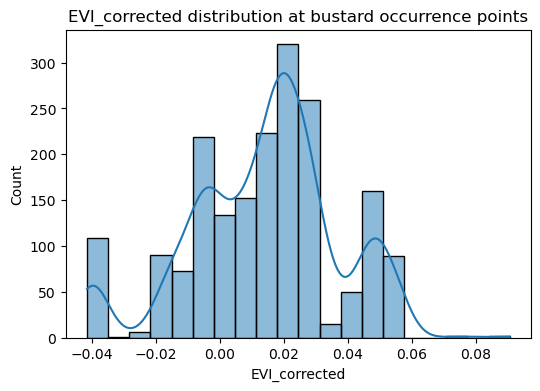

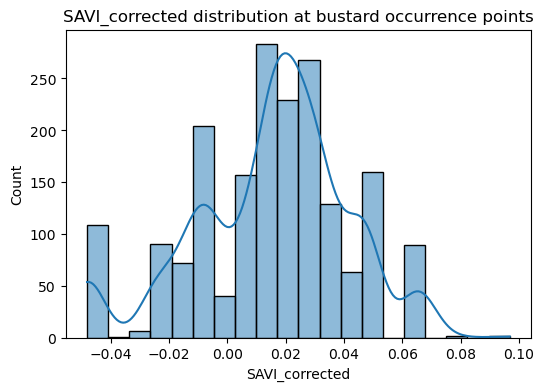

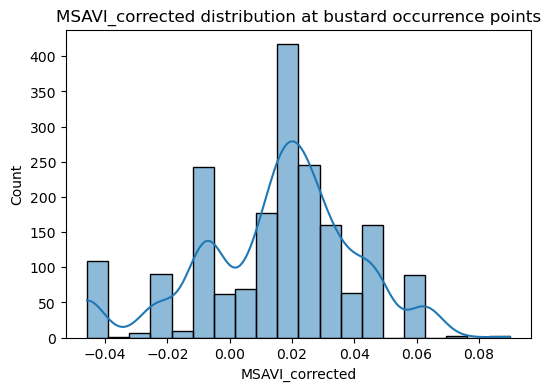

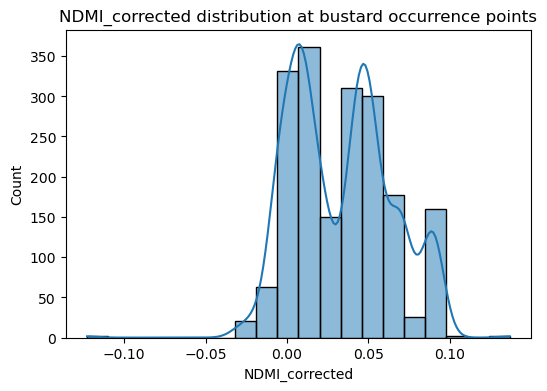

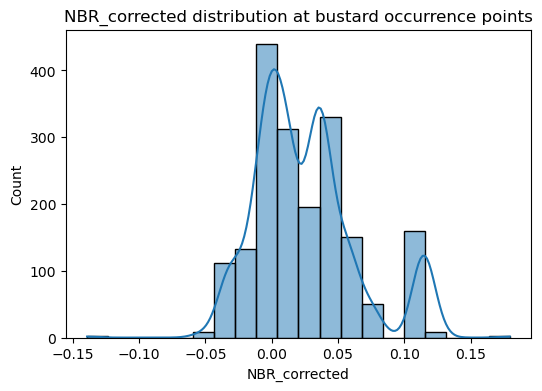

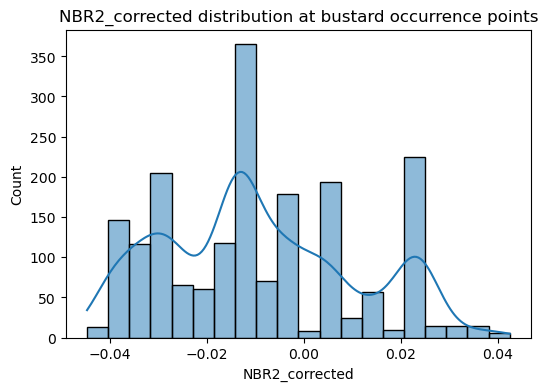

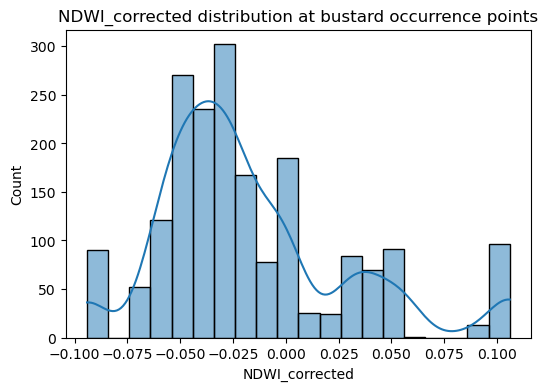

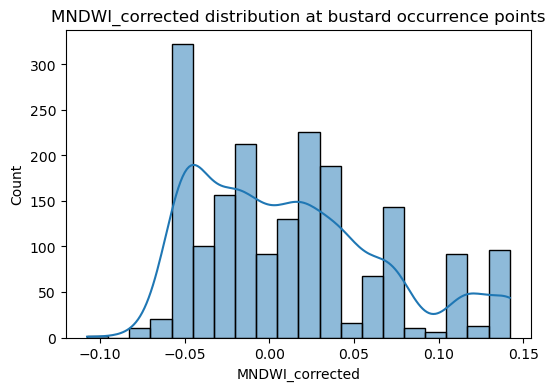

In [76]:
# Step 3: Explore vegetation index values at occurrence points
# Example for Landsat
df = occ_with_stations['Landsat']

# Plot distributions of NDVI, EVI, etc., at bustard occurrence points
rs_indices = [col for col in df.columns if col.endswith('_corrected')]
for ind in rs_indices:
    plt.figure(figsize=(6,4))
    sns.histplot(df[ind], kde=True, bins=20)
    plt.title(f'{ind} distribution at bustard occurrence points')
    plt.xlabel(ind)
    plt.ylabel('Count')
    plt.show()

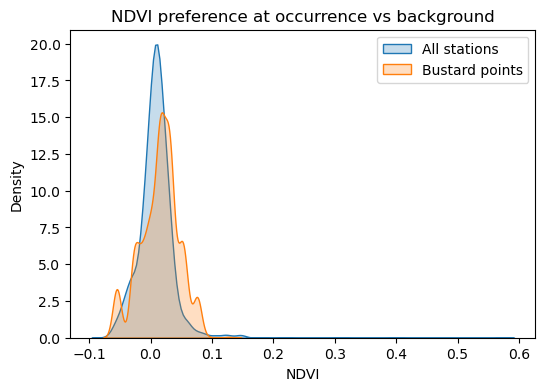

In [37]:
# # Step 4: Compare occurrence vs station background
# # Repeat for other indices to see which ranges are preferred.
# # Example: Landsat
# station_df = station_gdfs[0]  # All stations
# occ_df = occ_with_stations['Landsat']

# # Density plots for NDVI
# plt.figure(figsize=(6,4))
# sns.kdeplot(station_df['NDVI_corrected'], label='All stations', fill=True)
# sns.kdeplot(occ_df['NDVI_corrected'], label='Bustard points', fill=True)
# plt.xlabel('NDVI')
# plt.ylabel('Density')
# plt.title('NDVI preference at occurrence vs background')
# plt.legend()
# plt.show()


--- Landsat ---


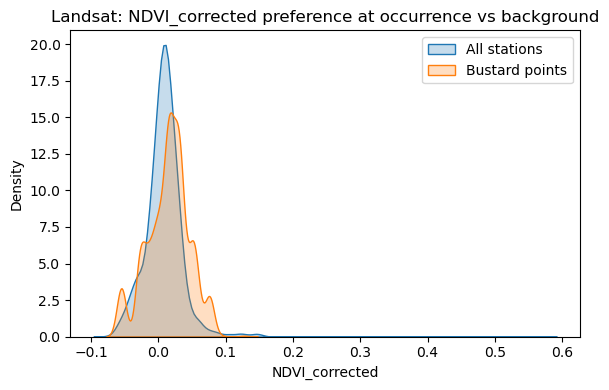

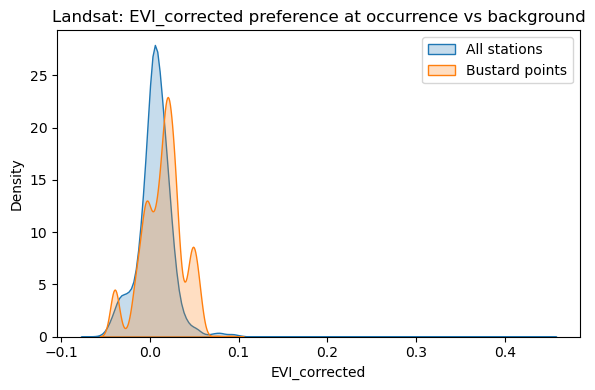

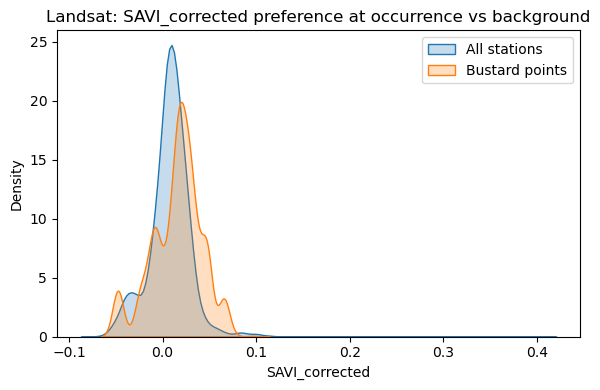

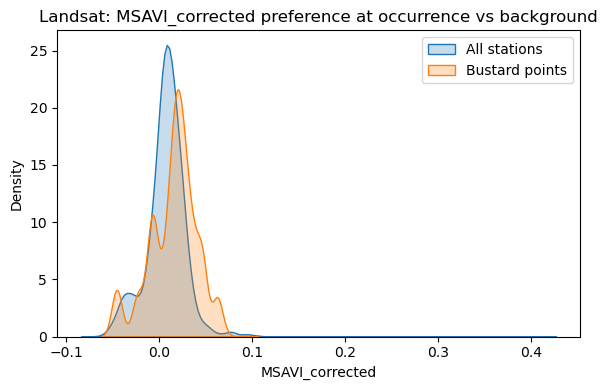

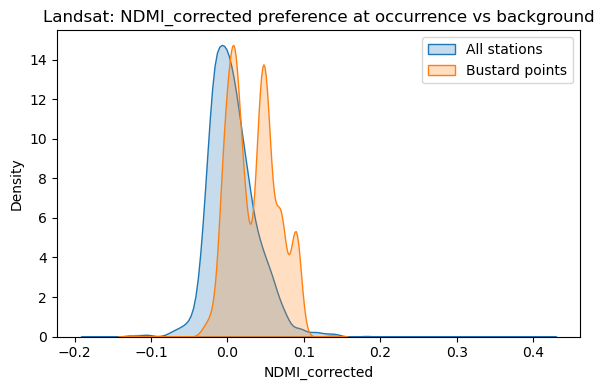

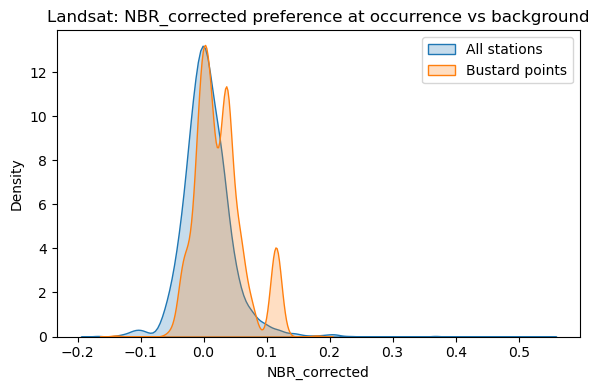

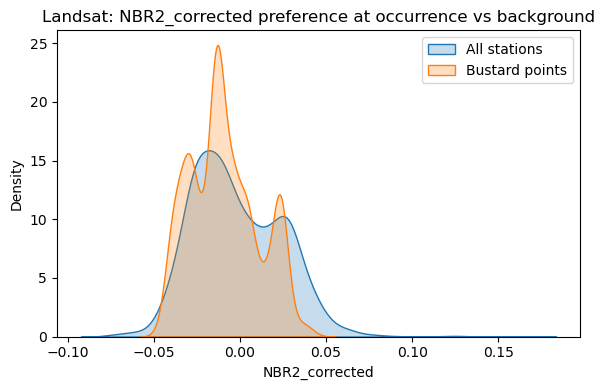

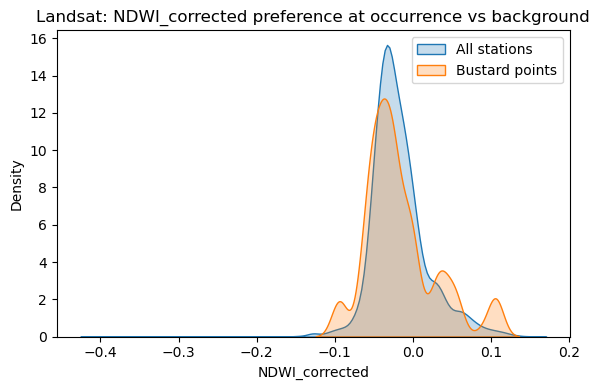

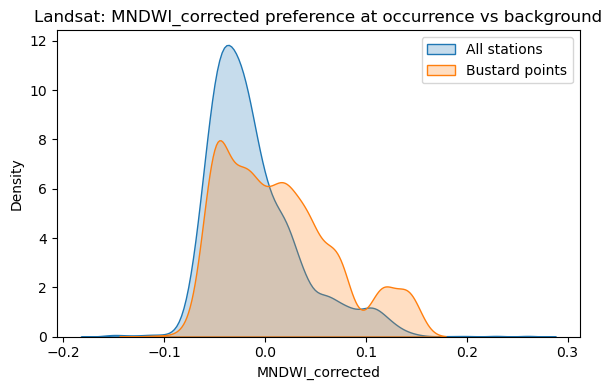

--- Sentinel2 ---


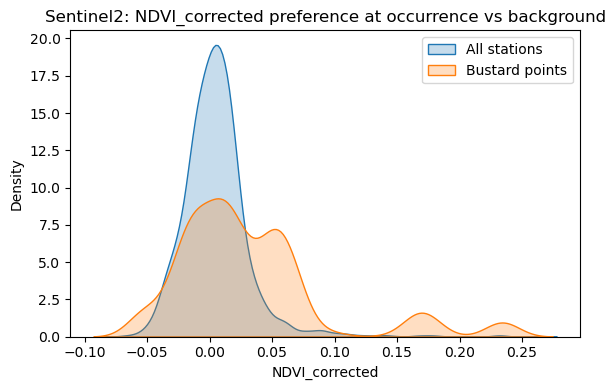

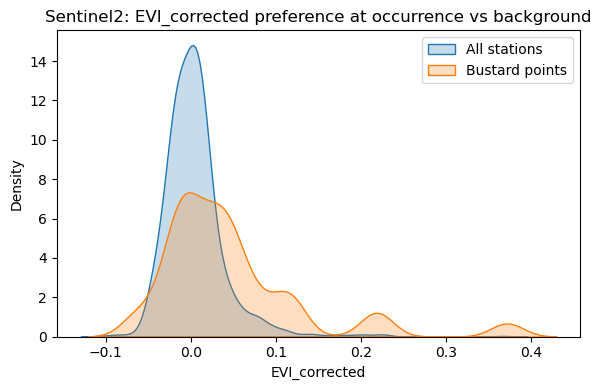

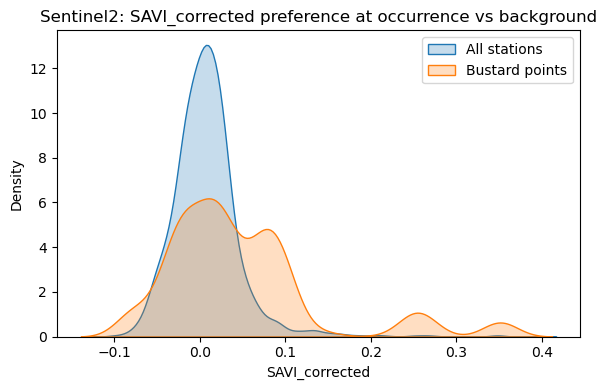

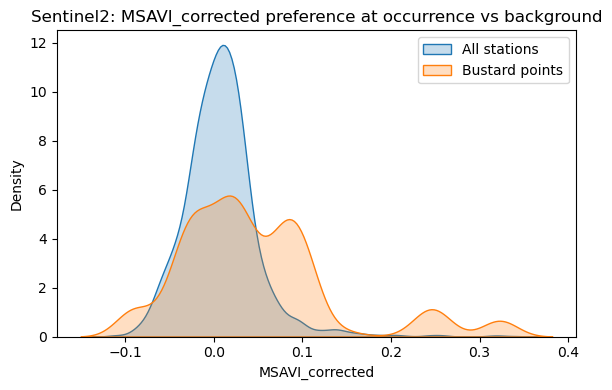

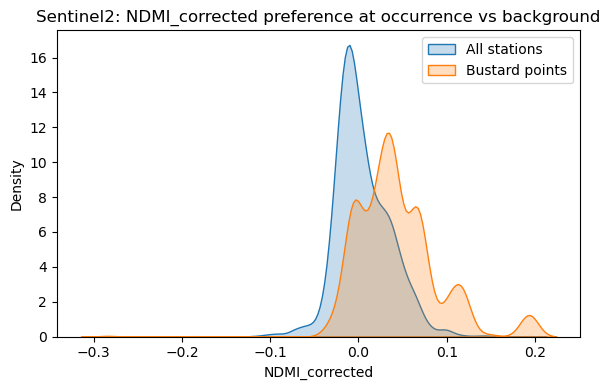

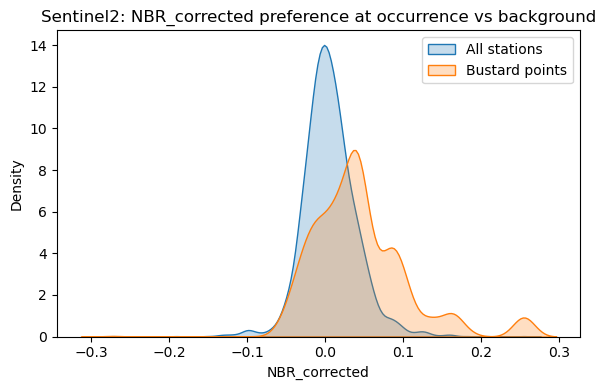

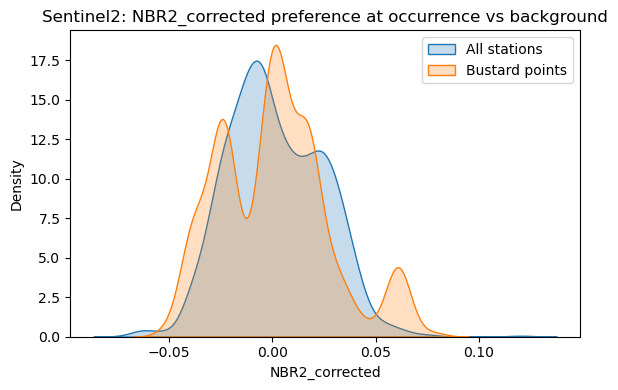

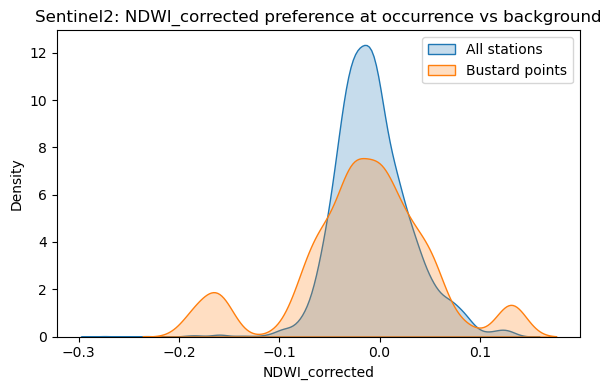

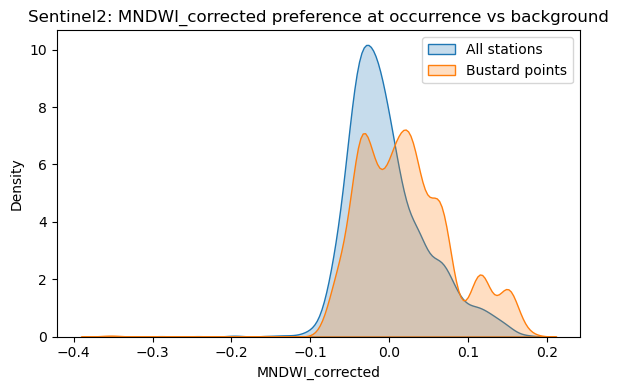

--- MOD09A1 ---


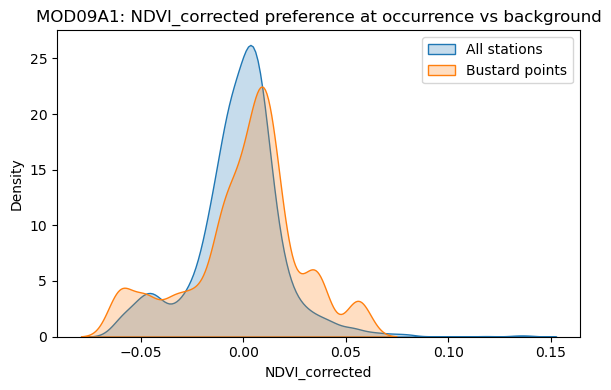

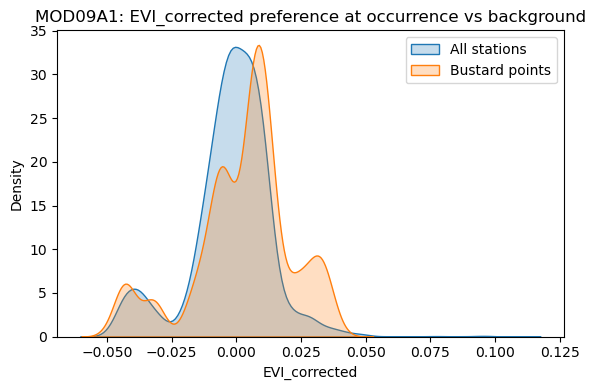

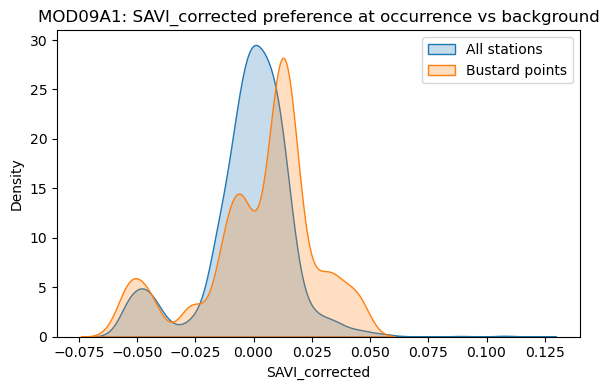

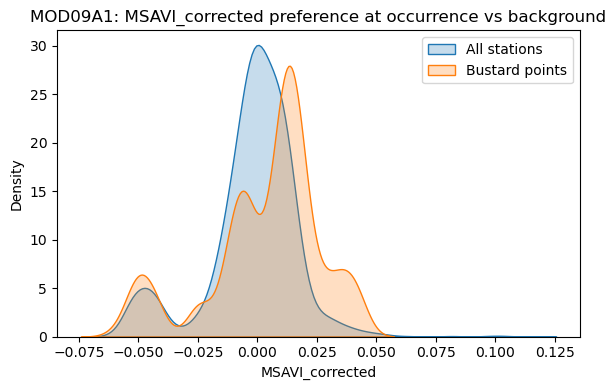

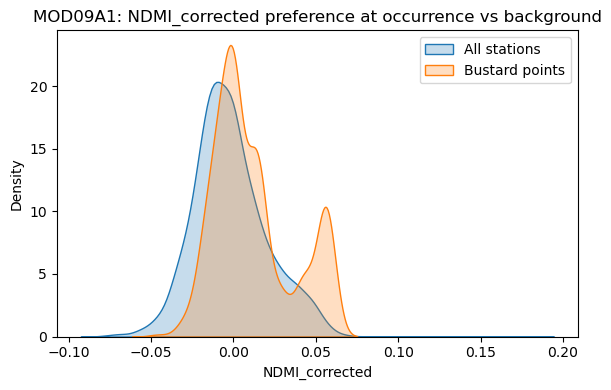

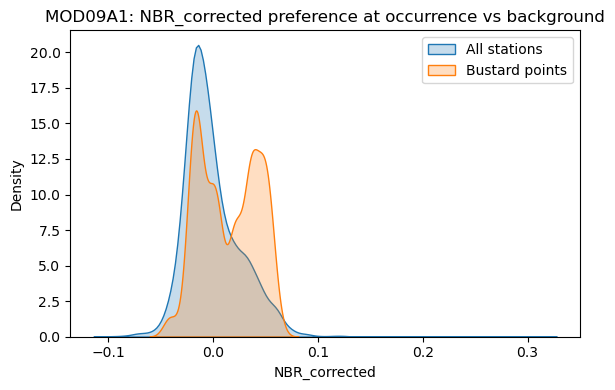

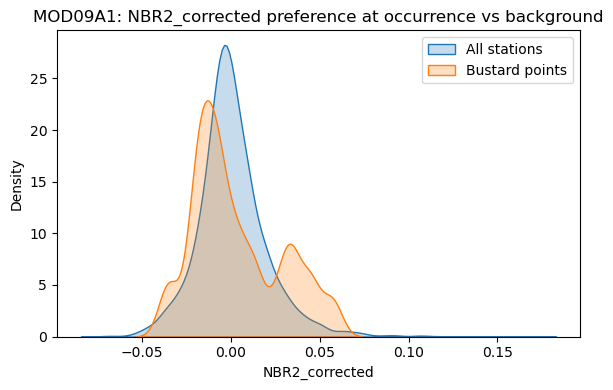

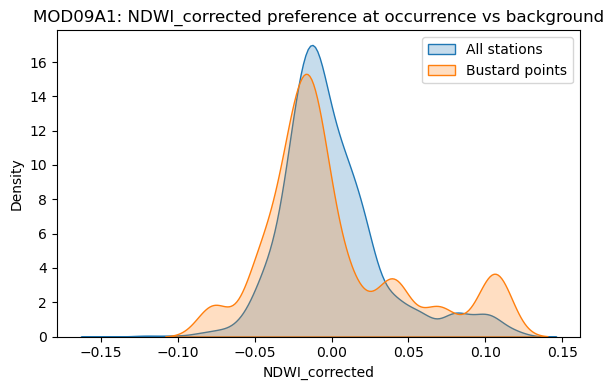

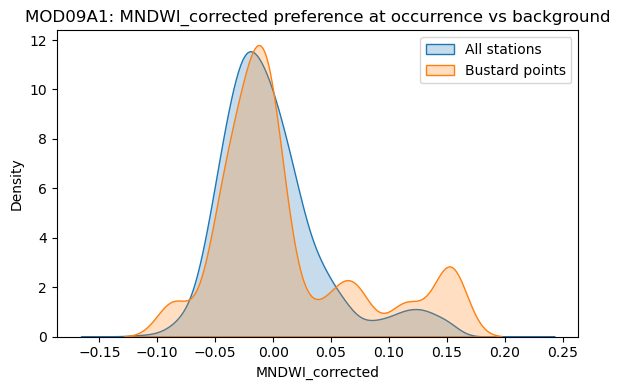

--- MOD13Q1 ---


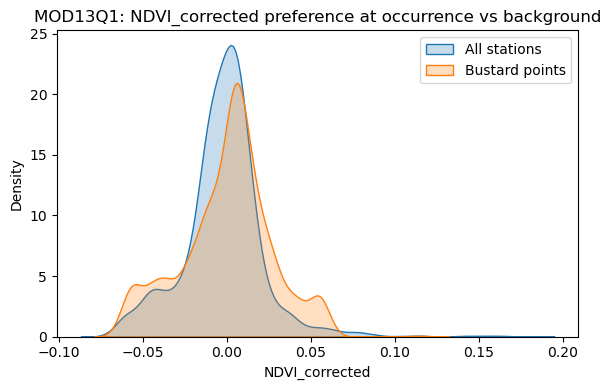

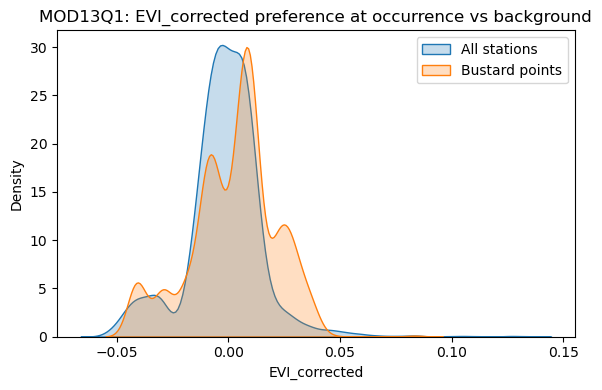

In [38]:
# Step 4: Compare occurrence vs station background
# Example: Landsat
def plot_occurrence_vs_station_density(occ_with_stations, station_gdfs, names, rs_indices=None):
    """
    Compare distributions of RS indices at bustard occurrence points vs all stations.
    
    Parameters
    ----------
    occ_with_stations : dict
        Dict of GeoDataFrames for each satellite with occurrence points linked to stations.
    station_gdfs : list
        List of station DataFrames for each satellite.
    names : list
        Names of the satellites corresponding to occ_with_stations and station_gdfs.
    rs_indices : list
        List of RS indices to compare. If None, automatically select columns ending with '_corrected'.
    """
    for df, occ_df, sat in zip(station_gdfs, [occ_with_stations[n] for n in names], names):
        print(f"--- {sat} ---")
        
        # Auto-detect indices if not provided
        if rs_indices is None:
            indices = [col for col in df.columns if col.endswith('_corrected')]
        else:
            indices = rs_indices
        
        for ind in indices:
            plt.figure(figsize=(6,4))
            sns.kdeplot(df[ind], label='All stations', fill=True)
            sns.kdeplot(occ_df[ind], label='Bustard points', fill=True)
            plt.xlabel(ind)
            plt.ylabel('Density')
            plt.title(f'{sat}: {ind} preference at occurrence vs background')
            plt.legend()
            plt.tight_layout()
            plt.show()
            
plot_occurrence_vs_station_density(occ_with_stations, station_gdfs, names)

Landsat: 1904 occurrence points linked to stations
Sentinel2: 1904 occurrence points linked to stations
MOD09A1: 1904 occurrence points linked to stations
MOD13Q1: 1904 occurrence points linked to stations


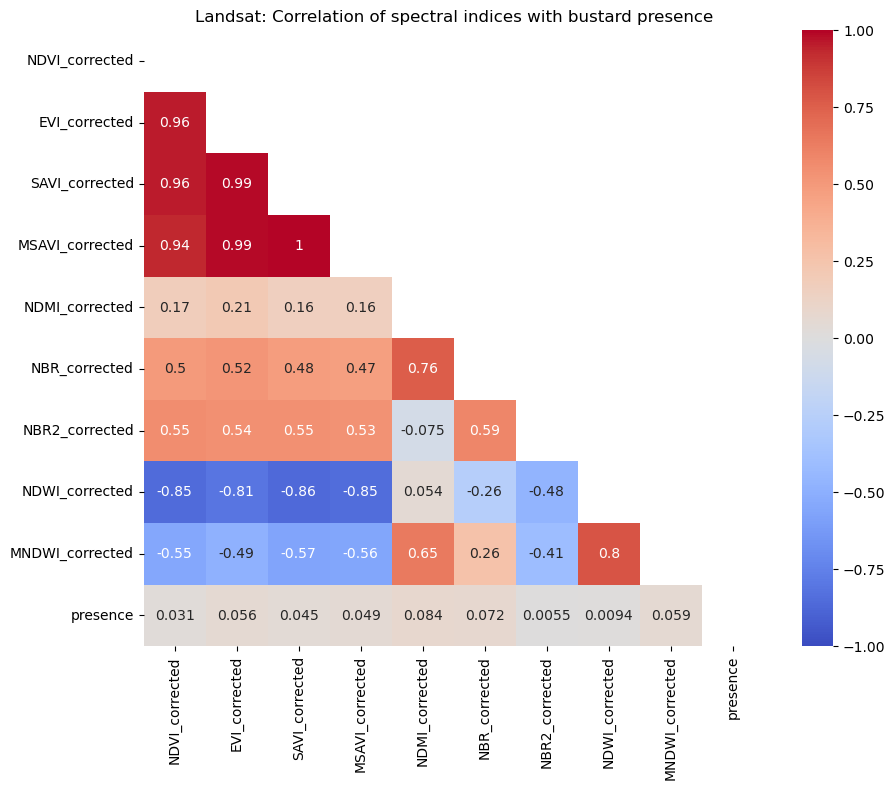

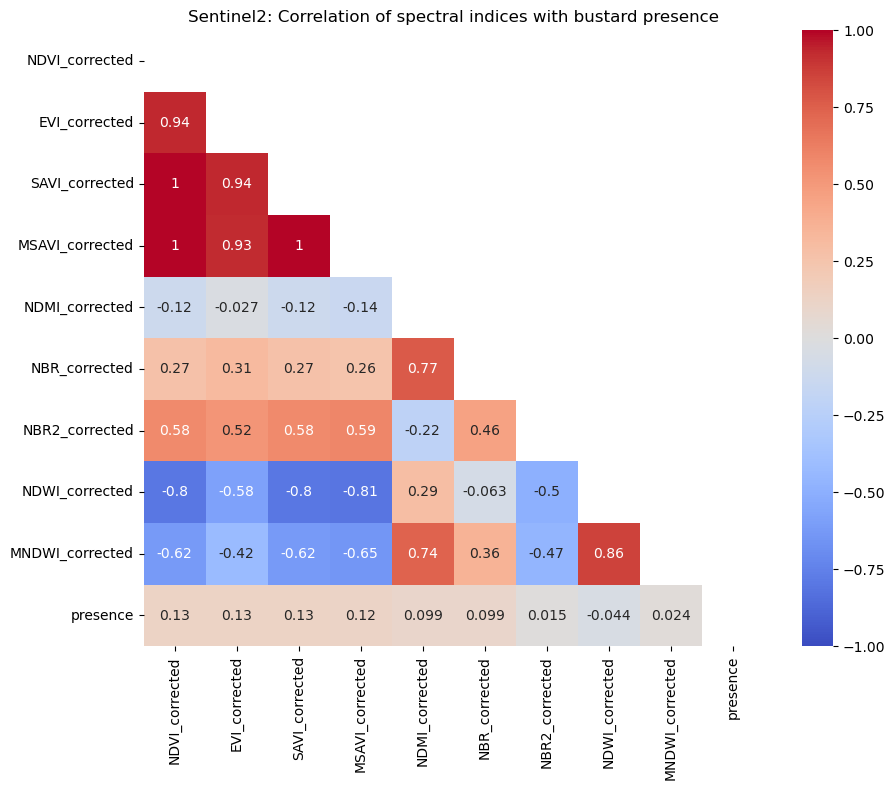

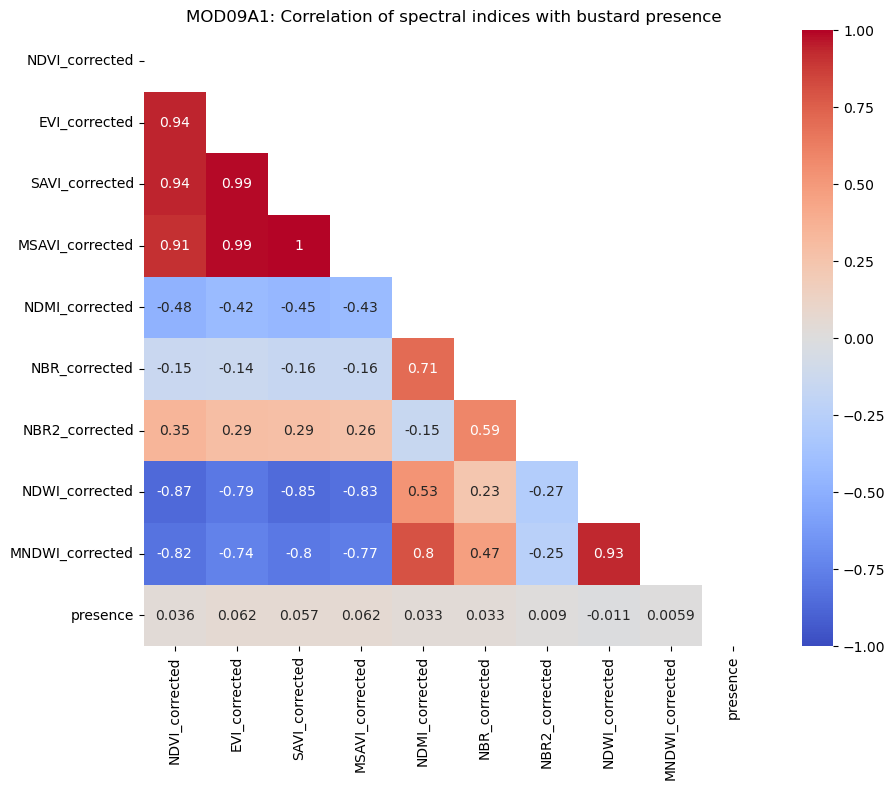

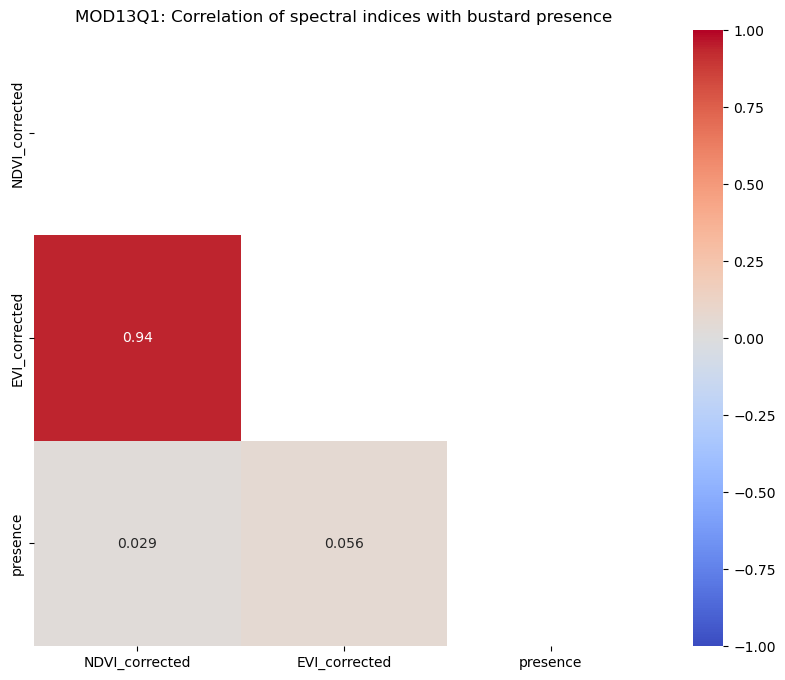

In [90]:
# Step 5: Correlation of bustard occurrence with vegetation indices
# --- Function to plot lower-triangle correlation heatmap of RS indices vs presence ---
def plot_corr_with_presence_loop(occ_with_stations, station_gdfs, sat_names):
    """
    Plot correlation of spectral indices with bustard presence for multiple satellites.

    Parameters
    ----------
    occ_with_stations : dict
        Dictionary with satellite names as keys and occurrence GeoDataFrames as values
        (must include 'nearest_idx' column).
    station_gdfs : list of GeoDataFrames
        List of corresponding station GeoDataFrames.
    sat_names : list of str
        Satellite names, matching keys of occ_with_stations and order of station_gdfs.
    """
    for sat, station_gdf in zip(sat_names, station_gdfs):
        occ_df = occ_with_stations[sat]

        # Determine RS indices automatically
        rs_indices = [col for col in station_gdf.columns if col.endswith('_corrected')]

        # Add presence column
        station_df = station_gdf.copy()
        station_df['presence'] = 0
        if 'nearest_idx' not in occ_df.columns:
            raise ValueError(f"'nearest_idx' missing in occurrence data for {sat}")
        station_df.loc[station_df.index.isin(occ_df['nearest_idx']), 'presence'] = 1

        # Correlation matrix
        corr_cols = rs_indices + ['presence']
        corr_matrix = station_df[corr_cols].corr()

        # Mask upper triangle
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

        # Plot heatmap
        plt.figure(figsize=(10,8))
        sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
        plt.title(f'{sat}: Correlation of spectral indices with bustard presence')
        plt.show()


# --- Example usage ---
occ_with_stations = {} 
for name, station_gdf in zip(names, station_gdfs):
    merged, nearest_idx = attach_nearest_station(occ_shp, station_gdf)
    # Add nearest_idx as a column
    merged['nearest_idx'] = nearest_idx
    occ_with_stations[name] = merged
    print(f"{name}: {merged.shape[0]} occurrence points linked to stations")

sat_names = ['Landsat','Sentinel2','MOD09A1','MOD13Q1']
plot_corr_with_presence_loop(occ_with_stations, station_gdfs, sat_names)


=== Satellite: Landsat ===
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       572
           1       0.86      0.76      0.81       571

    accuracy                           0.82      1143
   macro avg       0.82      0.82      0.82      1143
weighted avg       0.82      0.82      0.82      1143

ROC-AUC: 0.895
PR-AUC: 0.905
Top Feature Importances:
             Index  Importance
7   NDWI_corrected    0.155062
6   NBR2_corrected    0.150504
0   NDVI_corrected    0.125807
8  MNDWI_corrected    0.110200
4   NDMI_corrected    0.104210
2   SAVI_corrected    0.092167
5    NBR_corrected    0.092011
1    EVI_corrected    0.086142
3  MSAVI_corrected    0.083898


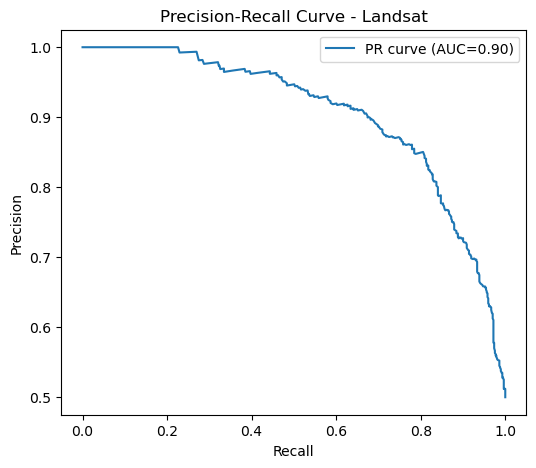

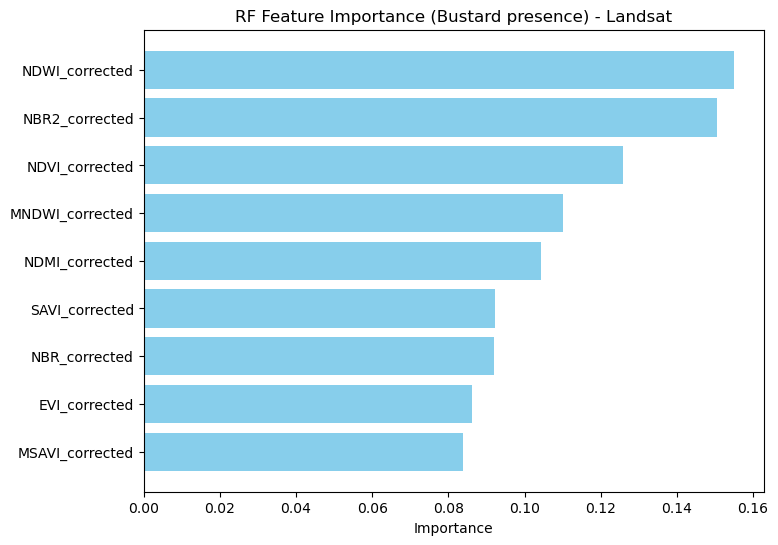

Suggested threshold for class 1 detection: 0.464

=== Satellite: Sentinel2 ===
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.94      0.86       572
           1       0.92      0.77      0.84       571

    accuracy                           0.85      1143
   macro avg       0.86      0.85      0.85      1143
weighted avg       0.86      0.85      0.85      1143

ROC-AUC: 0.951
PR-AUC: 0.954
Top Feature Importances:
             Index  Importance
6   NBR2_corrected    0.213822
4   NDMI_corrected    0.131168
7   NDWI_corrected    0.125119
8  MNDWI_corrected    0.119197
5    NBR_corrected    0.110484
1    EVI_corrected    0.084161
2   SAVI_corrected    0.073832
0   NDVI_corrected    0.071327
3  MSAVI_corrected    0.070890


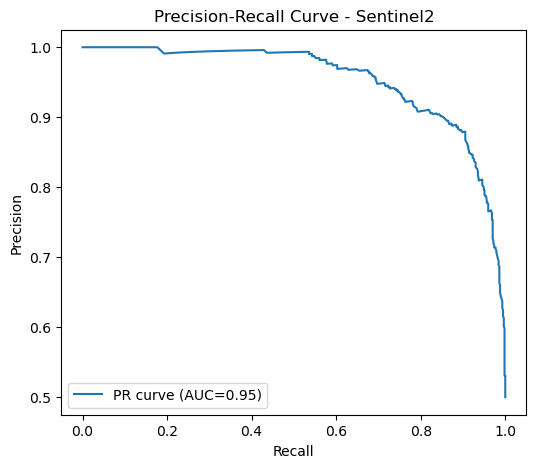

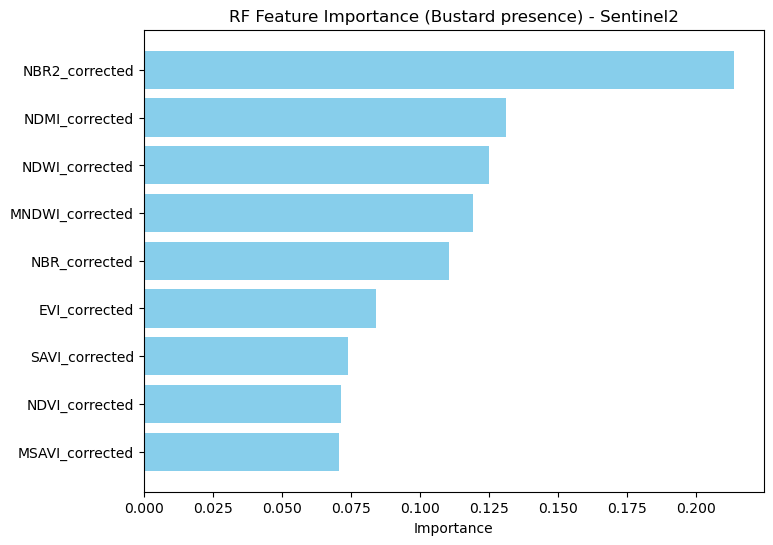

Suggested threshold for class 1 detection: 0.340

=== Satellite: MOD09A1 ===
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       572
           1       0.81      0.78      0.79       571

    accuracy                           0.80      1143
   macro avg       0.80      0.80      0.80      1143
weighted avg       0.80      0.80      0.80      1143

ROC-AUC: 0.880
PR-AUC: 0.887
Top Feature Importances:
             Index  Importance
7   NDWI_corrected    0.161354
5    NBR_corrected    0.147355
0   NDVI_corrected    0.123826
1    EVI_corrected    0.114159
8  MNDWI_corrected    0.102229
2   SAVI_corrected    0.098791
3  MSAVI_corrected    0.096747
4   NDMI_corrected    0.084071
6   NBR2_corrected    0.071467


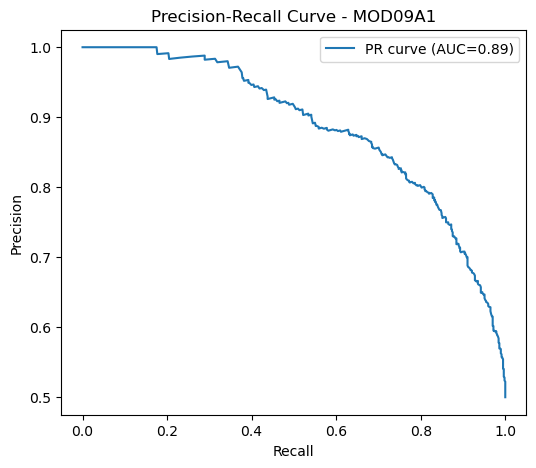

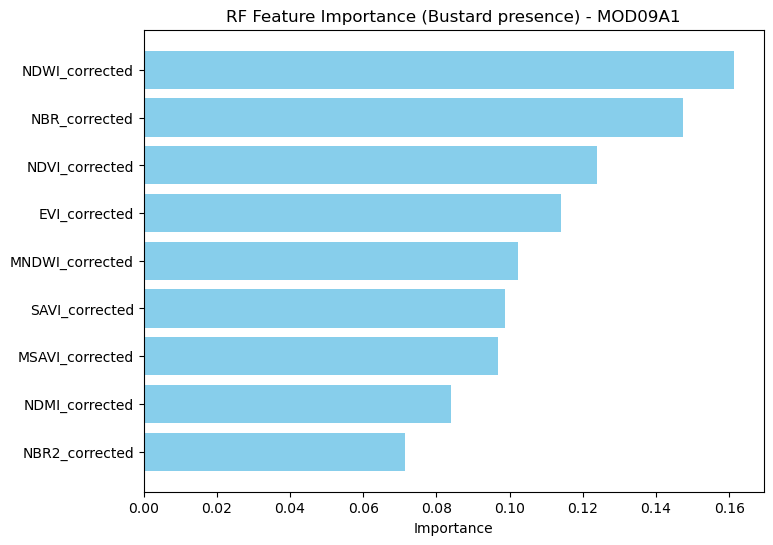

Suggested threshold for class 1 detection: 0.402

=== Satellite: MOD13Q1 ===
Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.68      0.67       572
           1       0.67      0.64      0.66       571

    accuracy                           0.66      1143
   macro avg       0.66      0.66      0.66      1143
weighted avg       0.66      0.66      0.66      1143

ROC-AUC: 0.733
PR-AUC: 0.755
Top Feature Importances:
            Index  Importance
0  NDVI_corrected    0.508803
1   EVI_corrected    0.491197


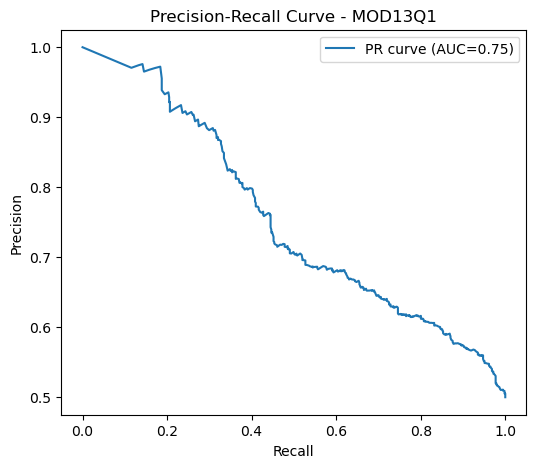

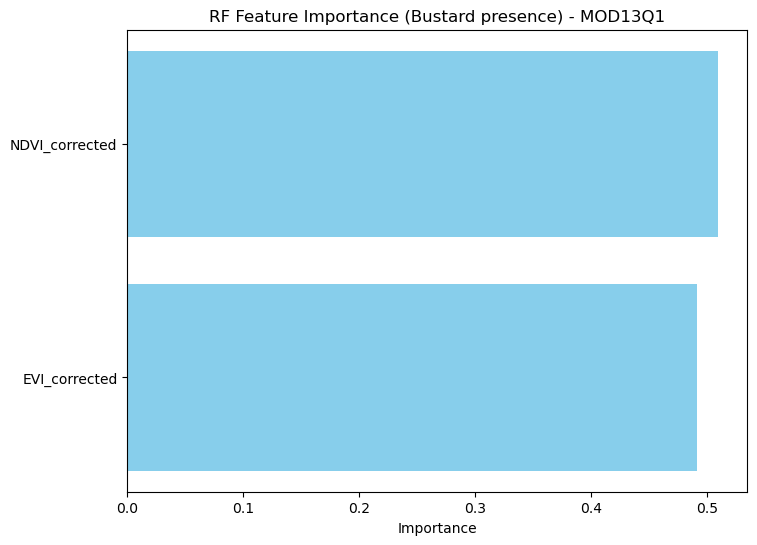

Suggested threshold for class 1 detection: 0.078


In [82]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ---- RF classification pipeline for all satellites ----
def run_rf_presence_pipeline(names, station_gdfs, occ_with_stations, rs_indices_suffix="_corrected"):
    """
    Run Random Forest classification for bustard presence using multiple satellite RS indices.

    Parameters
    ----------
    names : list of str
        Satellite names.
    station_gdfs : list of GeoDataFrames
        RS stations per satellite.
    occ_with_stations : dict
        Merged occurrence GeoDataFrames with nearest_idx column per satellite.
    rs_indices_suffix : str
        Suffix to automatically select RS index columns.

    Returns
    -------
    results_dict : dict
        Stores metrics, feature importance, and trained RF models for each satellite.
    """
    results_dict = {}

    for sat, station_df in zip(names, station_gdfs):
        print(f"\n=== Satellite: {sat} ===")

        # Copy to avoid modifying original
        df = station_df.copy()
        df['presence'] = 0

        # Get occurrence points
        occ_df = occ_with_stations.get(sat)
        if occ_df is None or occ_df.empty:
            print(f"No occurrence data for {sat}, skipping...")
            continue

        # Ensure nearest_idx exists
        if 'nearest_idx' not in occ_df.columns:
            occ_df = occ_df.copy()
            occ_df['nearest_idx'] = occ_df.index  # fallback if missing

        # Mark presence at station locations
        df.loc[occ_df['nearest_idx'], 'presence'] = 1

        # Select RS indices available in station_df
        rs_indices = [col for col in station_df.columns if col.endswith(rs_indices_suffix)]
        existing_indices = [col for col in rs_indices if col in df.columns]
        if not existing_indices:
            print(f"No RS indices for {sat}, skipping...")
            continue

        # Prepare X and y
        df_rf = df[existing_indices + ['presence']].dropna()
        X = df_rf[existing_indices]
        y = df_rf['presence']

        # Handle class imbalance with SMOTE
        sm = SMOTE(random_state=42)
        X_res, y_res = sm.fit_resample(X, y)

        # Split train/test
        X_train, X_test, y_train, y_test = train_test_split(
            X_res, y_res, test_size=0.3, random_state=42, stratify=y_res
        )

        # Train Random Forest
        rf = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
        rf.fit(X_train, y_train)

        # Predictions
        y_pred = rf.predict(X_test)
        y_proba = rf.predict_proba(X_test)[:,1]

        # Metrics
        cls_report = classification_report(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)
        precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
        pr_auc = auc(recall, precision)

        print("Classification Report:")
        print(cls_report)
        print(f"ROC-AUC: {roc_auc:.3f}")
        print(f"PR-AUC: {pr_auc:.3f}")

        # Feature importance
        imp_df = pd.DataFrame({'Index': existing_indices, 'Importance': rf.feature_importances_})
        imp_df = imp_df.sort_values('Importance', ascending=False)
        print("Top Feature Importances:")
        print(imp_df.head(10))

        # Store results
        results_dict[sat] = {
            'rf_model': rf,
            'metrics': {
                'classification_report': cls_report,
                'roc_auc': roc_auc,
                'pr_auc': pr_auc
            },
            'feature_importance': imp_df,
            'precision_recall_curve': (precision, recall, thresholds)
        }

        # Plot PR curve
        plt.figure(figsize=(6,5))
        plt.plot(recall, precision, label=f'PR curve (AUC={pr_auc:.2f})')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title(f'Precision-Recall Curve - {sat}')
        plt.legend()
        plt.show()

        # Plot feature importance
        plt.figure(figsize=(8,6))
        plt.barh(imp_df['Index'], imp_df['Importance'], color='skyblue')
        plt.gca().invert_yaxis()
        plt.xlabel("Importance")
        plt.title(f"RF Feature Importance (Bustard presence) - {sat}")
        plt.show()

        # Suggested threshold for minority class
        optimal_idx = np.argmax(recall - (1 - precision))
        optimal_threshold = thresholds[optimal_idx]
        print(f"Suggested threshold for class 1 detection: {optimal_threshold:.3f}")

    return results_dict

# ---- Example usage ----
results_dict = run_rf_presence_pipeline(names, station_gdfs, occ_with_stations)


# III Temporal dynamics
- Do seasonal or interannual changes in vegetation cover and spectral indices correspond with bustard occurrence patterns?
- Are there lag effects (e.g., bustards occurring after peak vegetation growth)?
- Do bustards track long-term greenness trends or respond to vegetation anomalies?



=== Satellite: Landsat ===


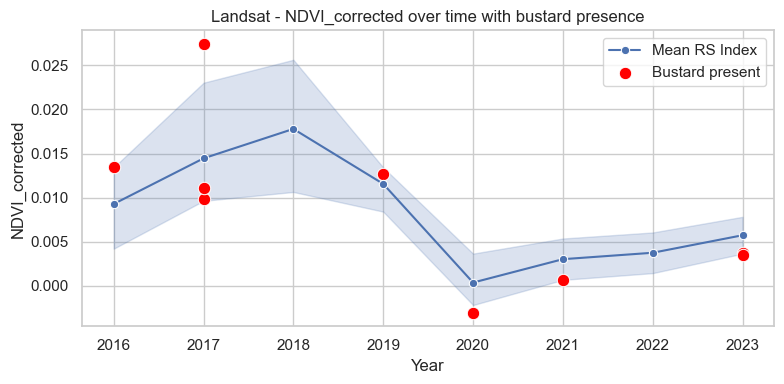

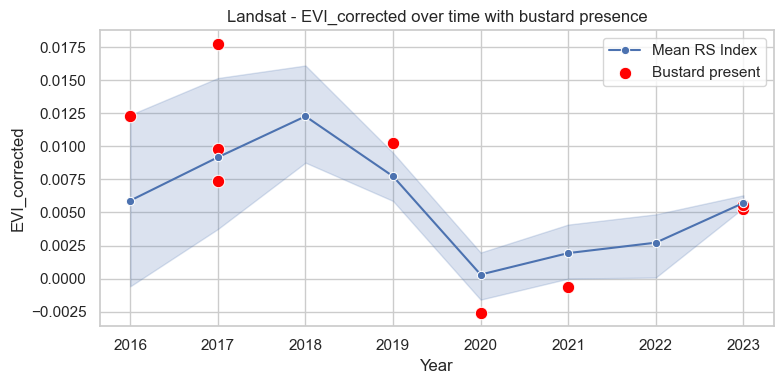

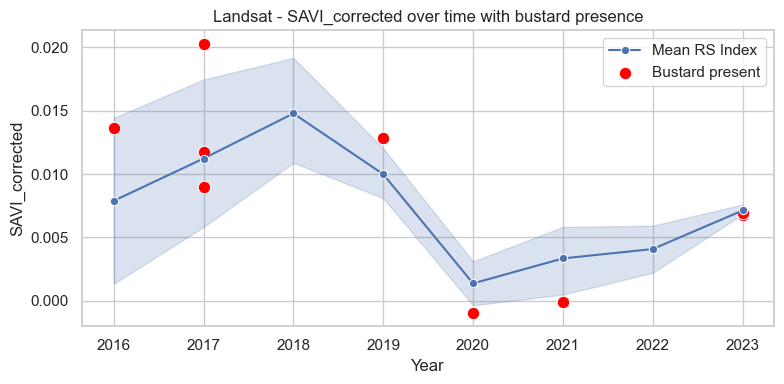

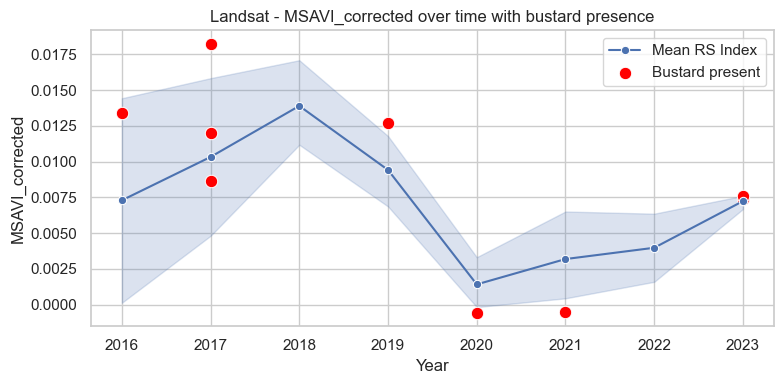

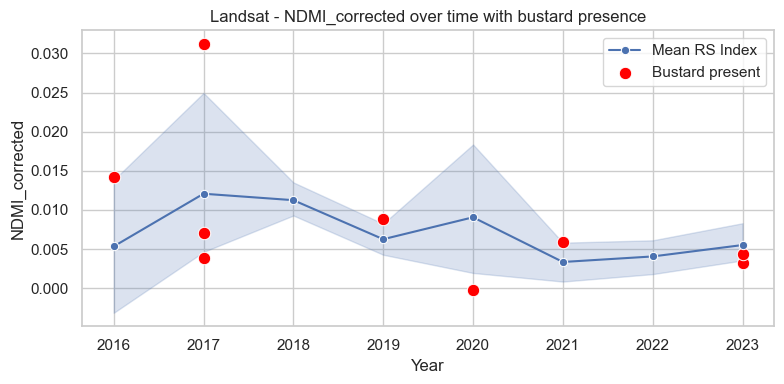

...

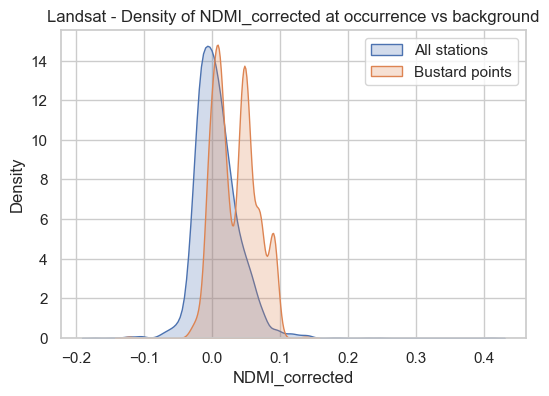

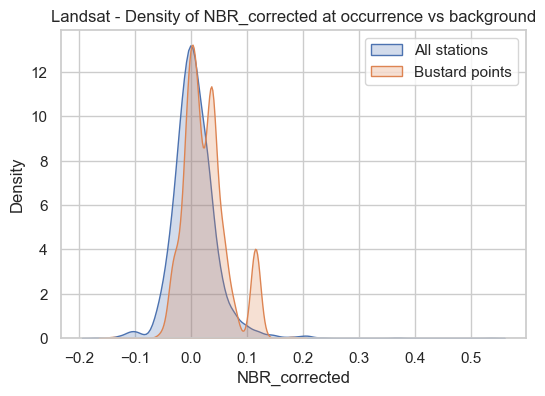

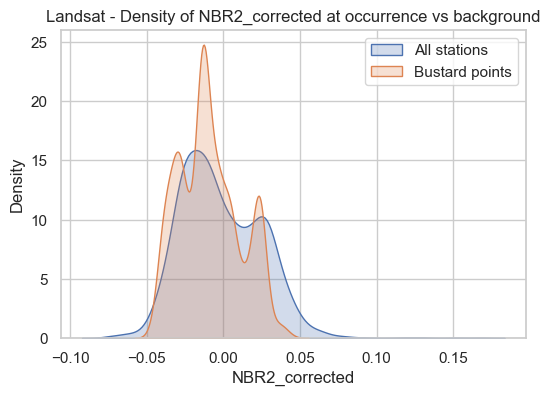

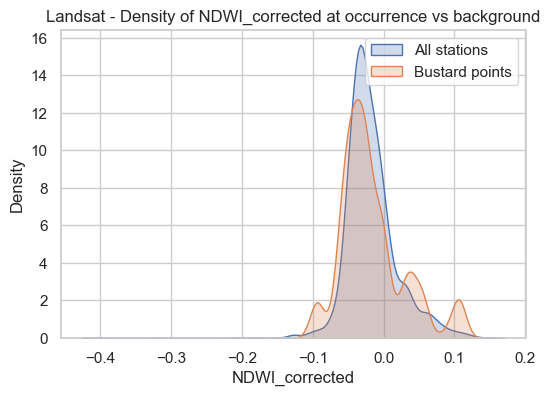

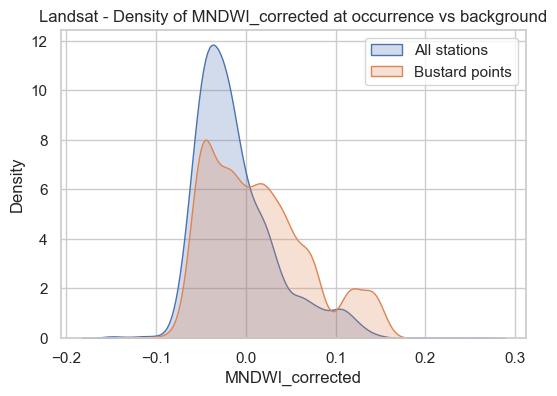

Landsat - NDVI_corrected_lag1 vs presence: Spearman r=0.207, p=0.256
Landsat - EVI_corrected_lag1 vs presence: Spearman r=0.013, p=0.945
Landsat - SAVI_corrected_lag1 vs presence: Spearman r=0.041, p=0.826
Landsat - MSAVI_corrected_lag1 vs presence: Spearman r=-0.006, p=0.976
Landsat - NDMI_corrected_lag1 vs presence: Spearman r=-0.076, p=0.679
Landsat - NBR_corrected_lag1 vs presence: Spearman r=0.249, p=0.170
Landsat - NBR2_corrected_lag1 vs presence: Spearman r=0.339, p=0.058
Landsat - NDWI_corrected_lag1 vs presence: Spearman r=-0.221, p=0.225
Landsat - MNDWI_corrected_lag1 vs presence: Spearman r=-0.135, p=0.462
Landsat - Annual NDVI_corrected vs presence: Spearman r=0.060, p=0.888
Landsat - Annual EVI_corrected vs presence: Spearman r=0.012, p=0.978
Landsat - Annual SAVI_corrected vs presence: Spearman r=0.012, p=0.978
Landsat - Annual MSAVI_corrected vs presence: Spearman r=0.012, p=0.978
Landsat - Annual NDMI_corrected vs presence: Spearman r=0.072, p=0.866
Landsat - Annual NBR

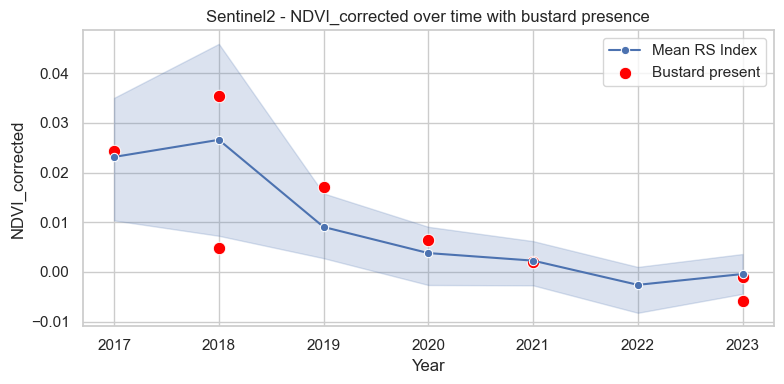

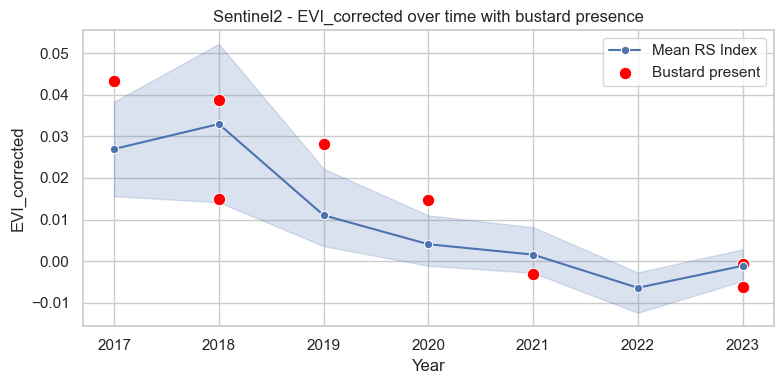

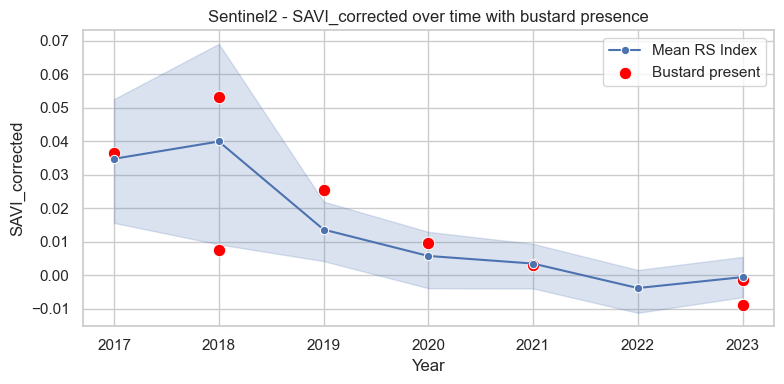

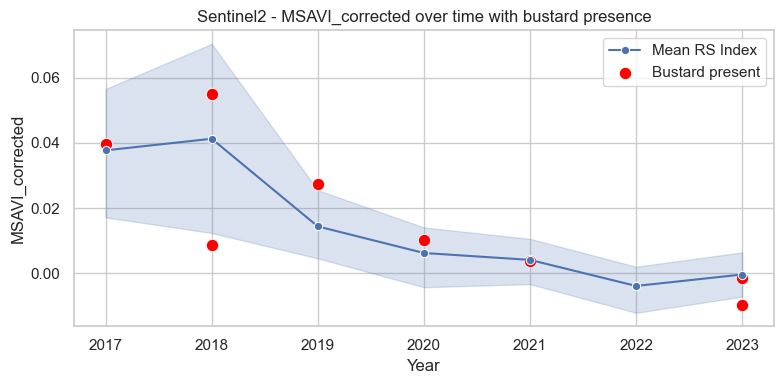

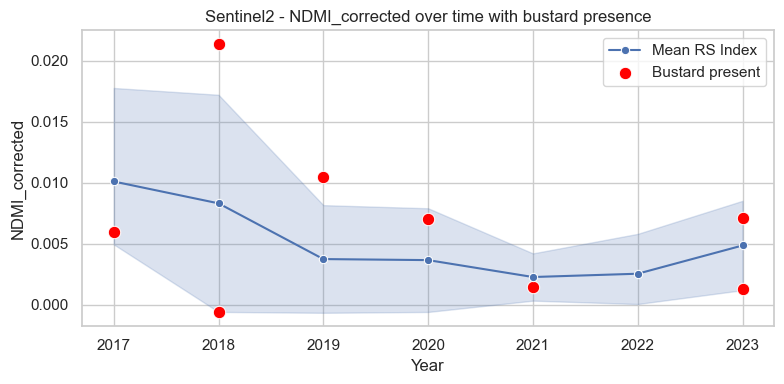

...

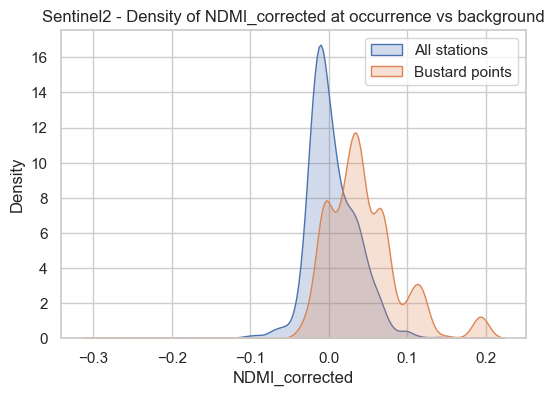

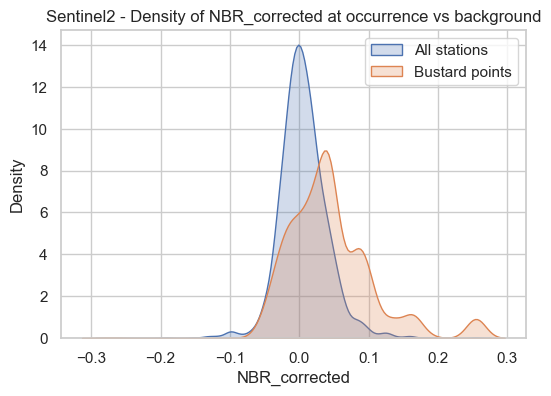

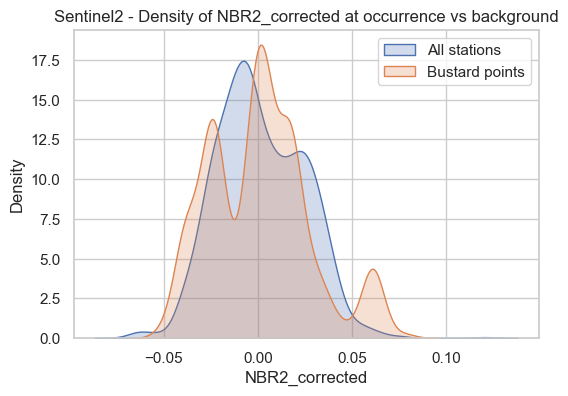

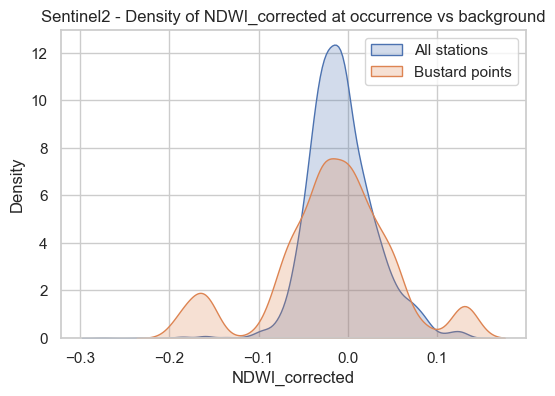

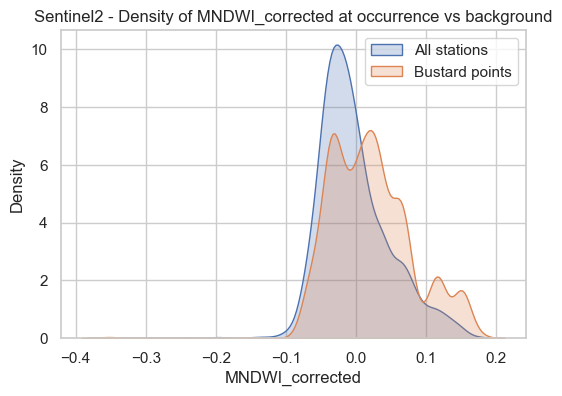

Sentinel2 - NDVI_corrected_lag1 vs presence: Spearman r=0.098, p=0.619
Sentinel2 - EVI_corrected_lag1 vs presence: Spearman r=0.095, p=0.631
Sentinel2 - SAVI_corrected_lag1 vs presence: Spearman r=0.098, p=0.619
Sentinel2 - MSAVI_corrected_lag1 vs presence: Spearman r=0.098, p=0.619
Sentinel2 - NDMI_corrected_lag1 vs presence: Spearman r=0.009, p=0.964
Sentinel2 - NBR_corrected_lag1 vs presence: Spearman r=0.048, p=0.807
Sentinel2 - NBR2_corrected_lag1 vs presence: Spearman r=0.052, p=0.791
Sentinel2 - NDWI_corrected_lag1 vs presence: Spearman r=-0.135, p=0.494
Sentinel2 - MNDWI_corrected_lag1 vs presence: Spearman r=-0.185, p=0.347
Sentinel2 - Annual NDVI_corrected vs presence: Spearman r=0.786, p=0.036
Sentinel2 - Annual EVI_corrected vs presence: Spearman r=0.786, p=0.036
Sentinel2 - Annual SAVI_corrected vs presence: Spearman r=0.786, p=0.036
Sentinel2 - Annual MSAVI_corrected vs presence: Spearman r=0.786, p=0.036
Sentinel2 - Annual NDMI_corrected vs presence: Spearman r=0.964, p=

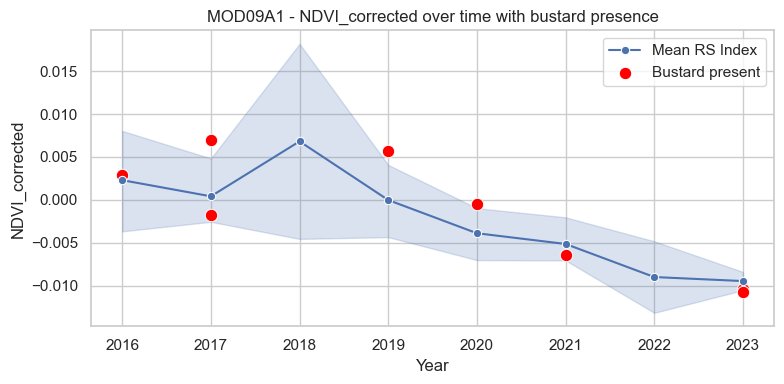

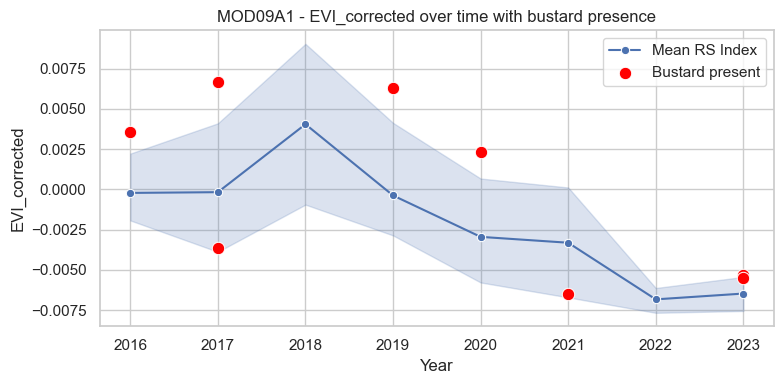

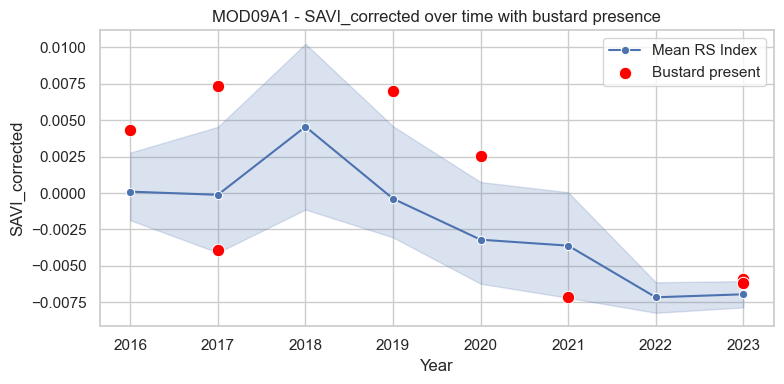

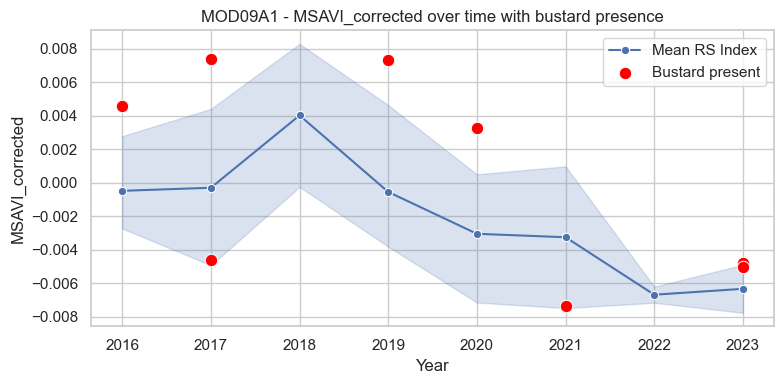

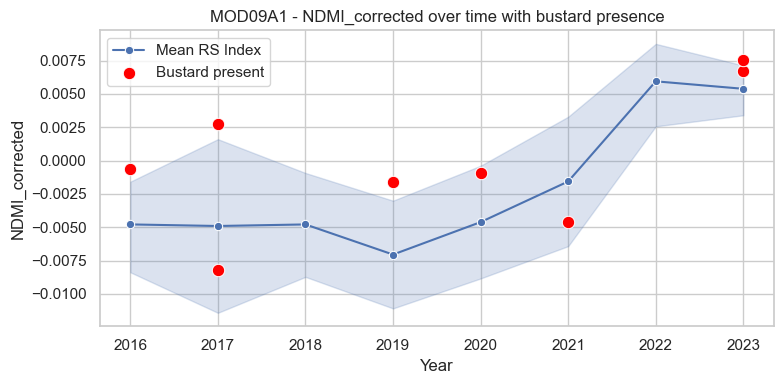

...

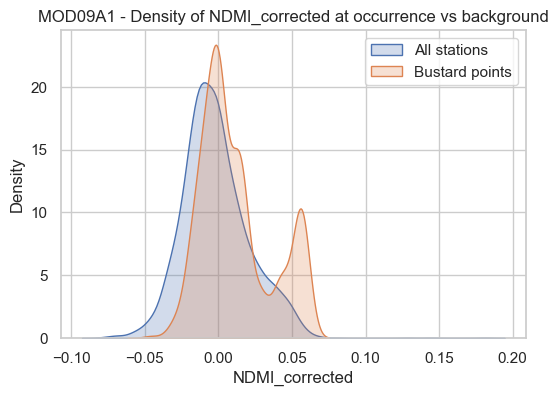

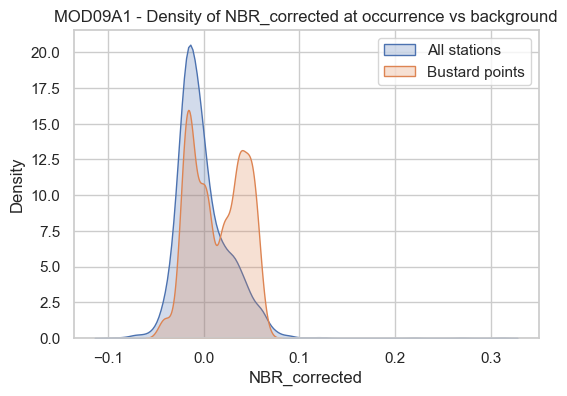

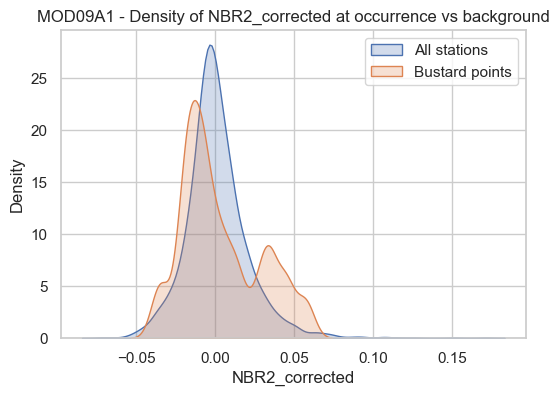

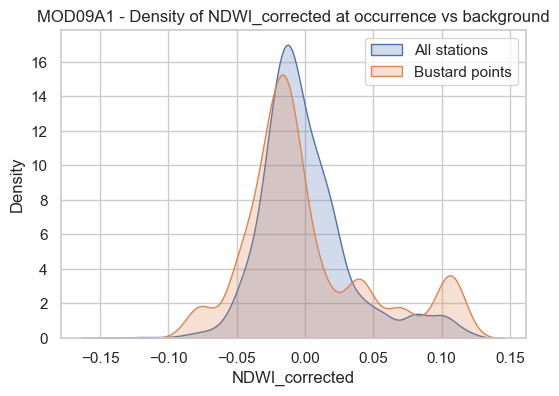

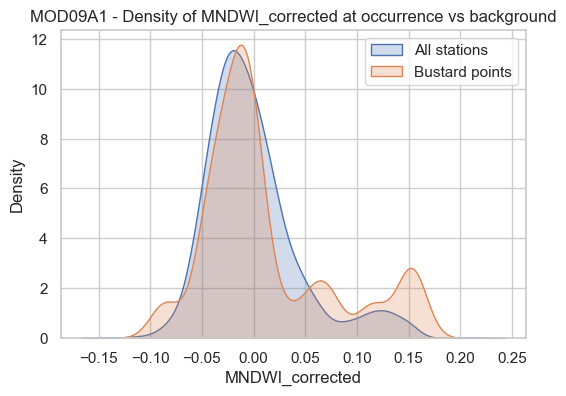

MOD09A1 - NDVI_corrected_lag1 vs presence: Spearman r=0.192, p=0.293
MOD09A1 - EVI_corrected_lag1 vs presence: Spearman r=0.162, p=0.377
MOD09A1 - SAVI_corrected_lag1 vs presence: Spearman r=0.191, p=0.296
MOD09A1 - MSAVI_corrected_lag1 vs presence: Spearman r=0.137, p=0.455
MOD09A1 - NDMI_corrected_lag1 vs presence: Spearman r=0.036, p=0.843
MOD09A1 - NBR_corrected_lag1 vs presence: Spearman r=0.159, p=0.386
MOD09A1 - NBR2_corrected_lag1 vs presence: Spearman r=0.034, p=0.855
MOD09A1 - NDWI_corrected_lag1 vs presence: Spearman r=-0.131, p=0.475
MOD09A1 - MNDWI_corrected_lag1 vs presence: Spearman r=-0.072, p=0.694
MOD09A1 - Annual NDVI_corrected vs presence: Spearman r=0.123, p=0.772
MOD09A1 - Annual EVI_corrected vs presence: Spearman r=0.209, p=0.620
MOD09A1 - Annual SAVI_corrected vs presence: Spearman r=0.233, p=0.578
MOD09A1 - Annual MSAVI_corrected vs presence: Spearman r=0.209, p=0.620
MOD09A1 - Annual NDMI_corrected vs presence: Spearman r=-0.233, p=0.578
MOD09A1 - Annual NBR_

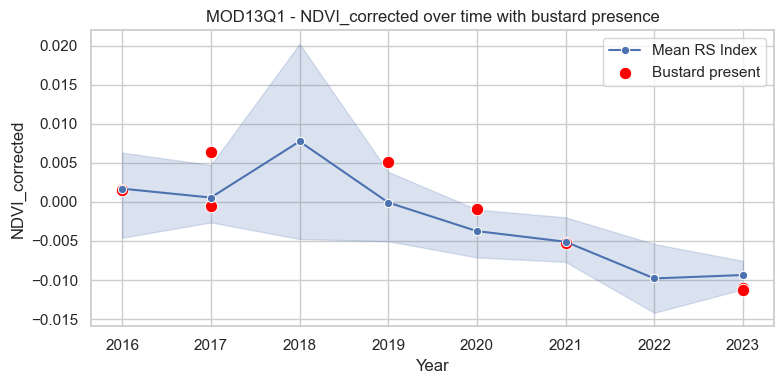

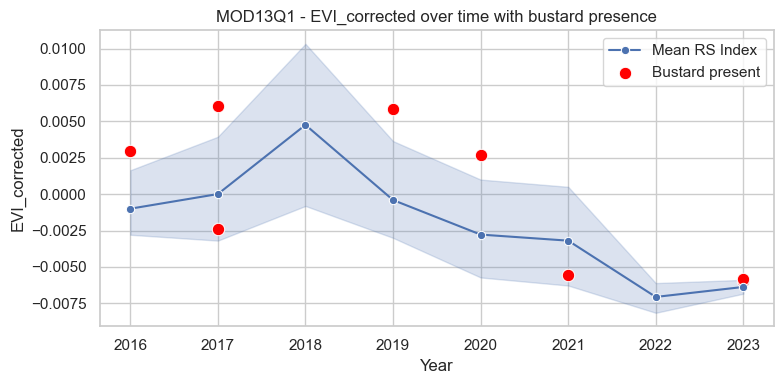

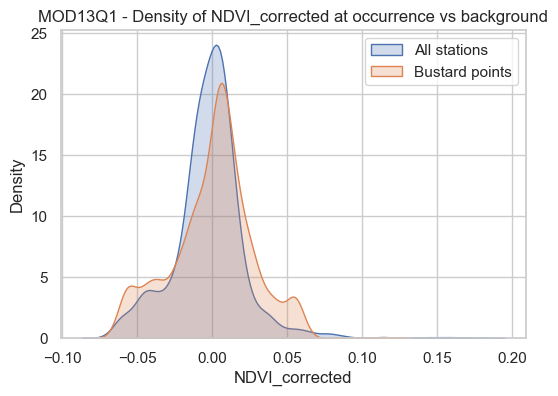

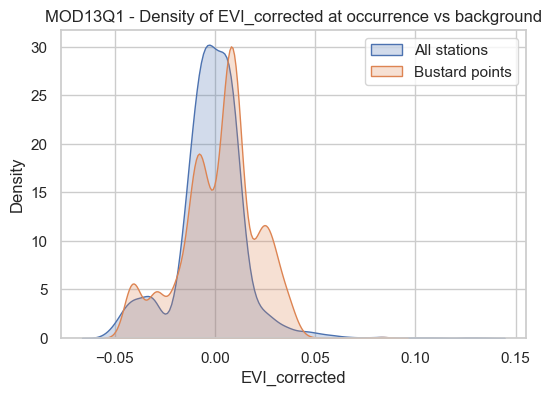

MOD13Q1 - NDVI_corrected_lag1 vs presence: Spearman r=0.161, p=0.380
MOD13Q1 - EVI_corrected_lag1 vs presence: Spearman r=0.133, p=0.470
MOD13Q1 - Annual NDVI_corrected vs presence: Spearman r=0.233, p=0.578
MOD13Q1 - Annual EVI_corrected vs presence: Spearman r=0.110, p=0.795


In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: for lagged correlations
from scipy.stats import spearmanr

# --- Parameters ---
season_order = ['Spring','Summer','Fall','Winter']
season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}

# Loop over satellites
for sat, station_df in zip(names, station_gdfs):
    print(f"\n=== Satellite: {sat} ===")

    df = station_df.copy()
    
    # Adjust RS indices for satellite (MOD13Q1 only has NDVI & EVI)
    if sat == 'MOD13Q1':
        rs_idx = [col for col in df.columns if col in ['NDVI_corrected','EVI_corrected']]
    else:
        rs_idx = [col for col in df.columns if col.endswith('_corrected')]
    
    # Ensure presence column from linked occurrences
    occ_df = occ_with_stations.get(sat)
    df['presence'] = 0
    if occ_df is not None and 'nearest_idx' in occ_df.columns:
        df.loc[occ_df['nearest_idx'], 'presence'] = 1

    # --- Step 1: Convert seasons to ordered categorical ---
    df['Season'] = pd.Categorical(df['Season'], categories=season_order, ordered=True)
    
    # --- Step 2: Seasonal and annual aggregation ---
    seasonal_df = df.groupby(['Year','Season'])[rs_idx + ['presence']].mean().reset_index()
    annual_df = df.groupby('Year')[rs_idx + ['presence']].mean().reset_index()
    
    # --- Step 3: Compute lagged RS indices (1 season lag example) ---
    seasonal_df_sorted = seasonal_df.sort_values(['Year','Season'])
    for idx in rs_idx:
        seasonal_df_sorted[f'{idx}_lag1'] = seasonal_df_sorted[idx].shift(1)
    
    # --- Step 4: Compute RS anomalies ---
    for idx in rs_idx:
        seasonal_df_sorted[f'{idx}_anom'] = (seasonal_df_sorted[idx] - seasonal_df_sorted[idx].mean()) / seasonal_df_sorted[idx].std()
    
    # --- Step 5: Visualize seasonal trends vs bustard presence ---
    for idx in rs_idx:
        plt.figure(figsize=(8,4))
        sns.lineplot(data=seasonal_df_sorted, x='Year', y=idx, marker='o', label='Mean RS Index')
        sns.scatterplot(data=seasonal_df_sorted[seasonal_df_sorted['presence']>0],
                        x='Year', y=idx, color='red', s=80, label='Bustard present')
        plt.title(f'{sat} - {idx} over time with bustard presence')
        plt.ylabel(idx)
        plt.legend()
        plt.tight_layout()
        plt.show()
    
    # --- Step 6: Density plots for presence vs background ---
    for idx in rs_idx:
        plt.figure(figsize=(6,4))
        sns.kdeplot(df[idx], label='All stations', fill=True)
        if occ_df is not None and 'nearest_idx' in occ_df.columns:
            sns.kdeplot(df.loc[occ_df['nearest_idx'], idx], label='Bustard points', fill=True)
        plt.title(f'{sat} - Density of {idx} at occurrence vs background')
        plt.xlabel(idx)
        plt.ylabel('Density')
        plt.legend()
        plt.show()
    
    # --- Step 7: Lag correlation analysis ---
    for idx in rs_idx:
        # correlate lag1 index with presence
        corr, pval = spearmanr(seasonal_df_sorted[f'{idx}_lag1'].fillna(0),
                               seasonal_df_sorted['presence'])
        print(f"{sat} - {idx}_lag1 vs presence: Spearman r={corr:.3f}, p={pval:.3f}")
    
    # --- Step 8: Optional - annual trend correlation ---
    for idx in rs_idx:
        corr, pval = spearmanr(annual_df[idx], annual_df['presence'])
        print(f"{sat} - Annual {idx} vs presence: Spearman r={corr:.3f}, p={pval:.3f}")



=== Satellite: Landsat ===
Landsat - NDVI_corrected peak season: Winter (avg=0.011)
Landsat - EVI_corrected peak season: Spring (avg=0.008)
Landsat - SAVI_corrected peak season: Spring (avg=0.010)
Landsat - MSAVI_corrected peak season: Spring (avg=0.009)
Landsat - NDMI_corrected peak season: Spring (avg=0.009)
Landsat - NBR_corrected peak season: Winter (avg=0.013)
Landsat - NBR2_corrected peak season: Winter (avg=0.004)
Landsat - NDWI_corrected peak season: Summer (avg=-0.016)
Landsat - MNDWI_corrected peak season: Spring (avg=-0.009)


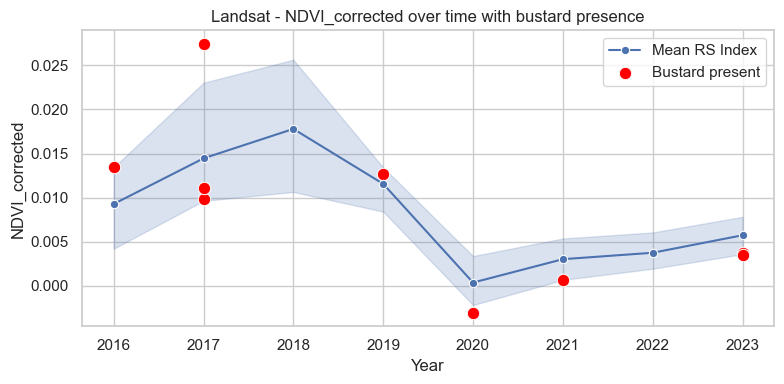

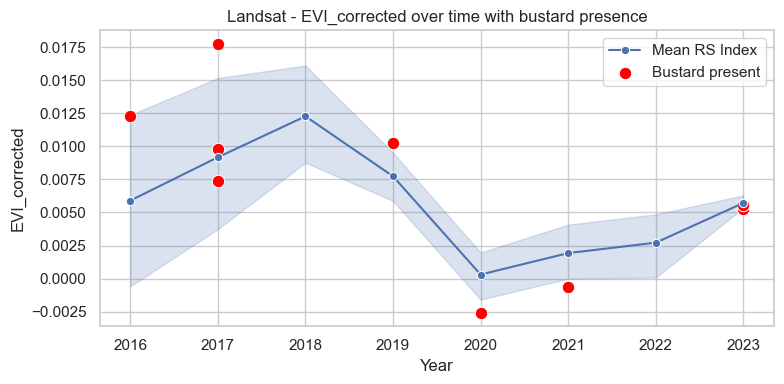

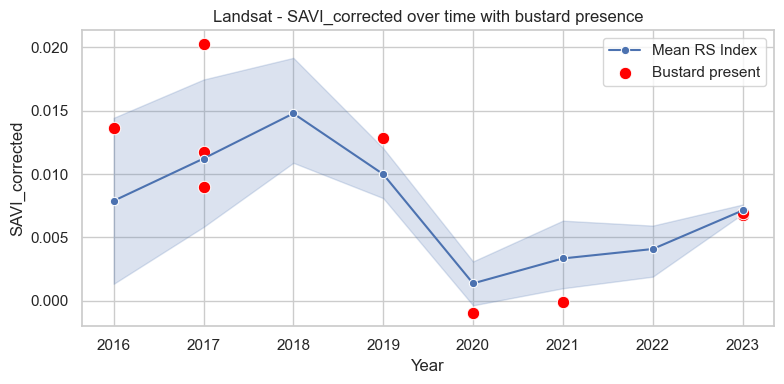

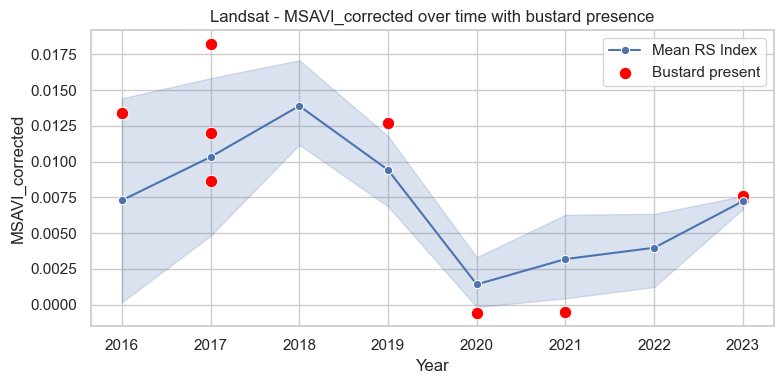

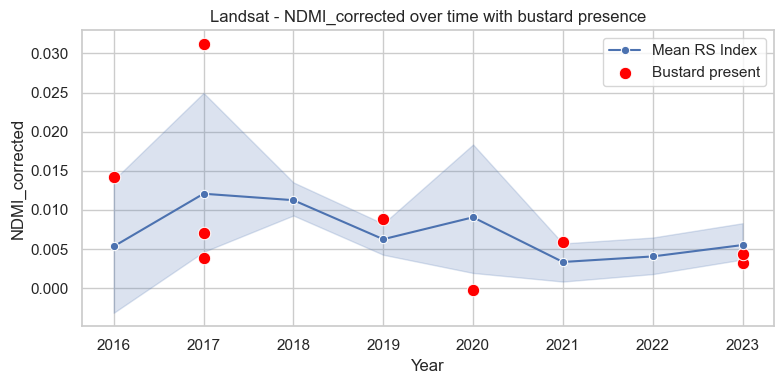

...

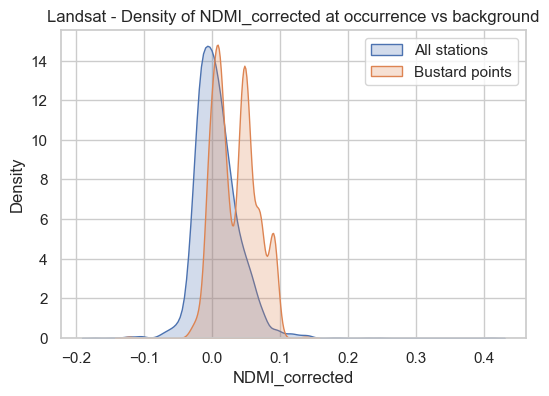

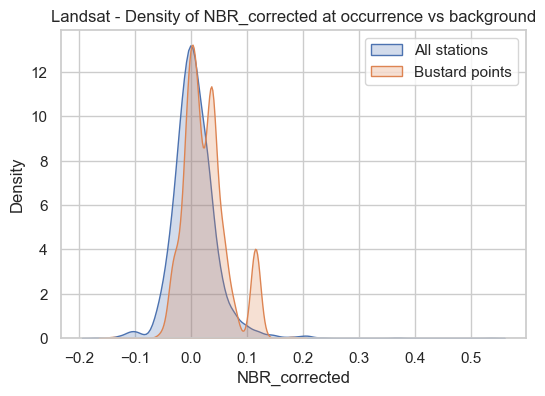

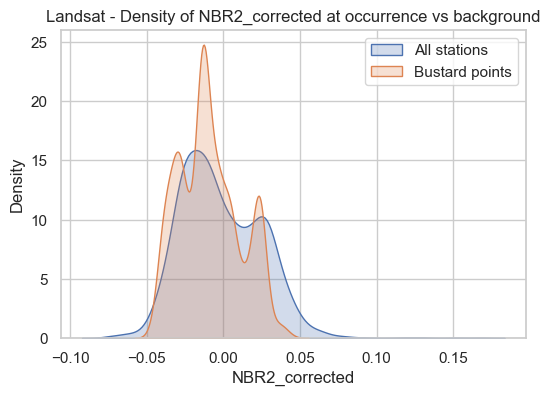

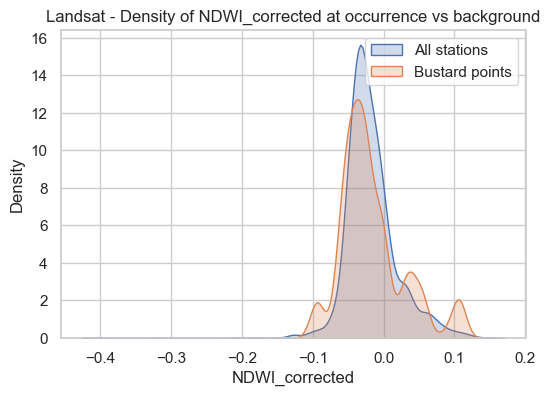

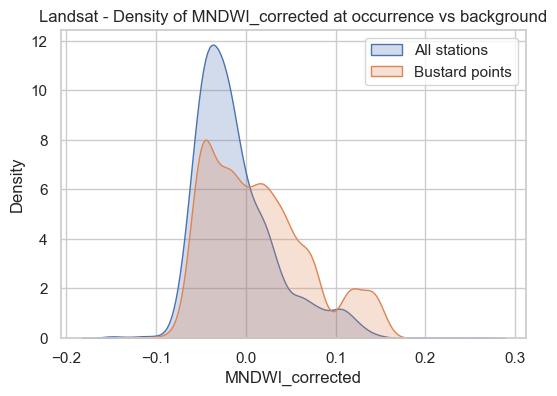

Landsat - NDVI_corrected_lag1 vs presence: Spearman r=0.207, p=0.256
Landsat - NDVI_corrected_lag2 vs presence: Spearman r=0.003, p=0.985
Landsat - NDVI_corrected_lag3 vs presence: Spearman r=-0.124, p=0.499
Landsat - EVI_corrected_lag1 vs presence: Spearman r=0.013, p=0.945
Landsat - EVI_corrected_lag2 vs presence: Spearman r=-0.198, p=0.278
Landsat - EVI_corrected_lag3 vs presence: Spearman r=-0.109, p=0.552
Landsat - SAVI_corrected_lag1 vs presence: Spearman r=0.041, p=0.826
Landsat - SAVI_corrected_lag2 vs presence: Spearman r=-0.189, p=0.299
Landsat - SAVI_corrected_lag3 vs presence: Spearman r=-0.097, p=0.597
Landsat - MSAVI_corrected_lag1 vs presence: Spearman r=-0.006, p=0.976
Landsat - MSAVI_corrected_lag2 vs presence: Spearman r=-0.225, p=0.216
Landsat - MSAVI_corrected_lag3 vs presence: Spearman r=-0.070, p=0.703
Landsat - NDMI_corrected_lag1 vs presence: Spearman r=-0.076, p=0.679
Landsat - NDMI_corrected_lag2 vs presence: Spearman r=-0.226, p=0.213
Landsat - NDMI_corrected

,min,max,median
NDVI_corrected,-0.056342,0.127395,0.016184
EVI_corrected,-0.041474,0.090708,0.017953
SAVI_corrected,-0.048062,0.096818,0.016696
MSAVI_corrected,-0.045753,0.089835,0.017708
NDMI_corrected,-0.122849,0.136857,0.038470
NBR_corrected,-0.139223,0.179408,0.014708
NBR2_corrected,-0.044688,0.042435,-0.012660
NDWI_corrected,-0.094078,0.106006,-0.028222
MNDWI_corrected,-0.107679,0.142077,0.005077


Landsat - NDVI_corrected anomaly vs presence: Spearman r=0.076, p=0.679
Landsat - EVI_corrected anomaly vs presence: Spearman r=0.231, p=0.204
Landsat - SAVI_corrected anomaly vs presence: Spearman r=0.169, p=0.355
Landsat - MSAVI_corrected anomaly vs presence: Spearman r=0.211, p=0.247
Landsat - NDMI_corrected anomaly vs presence: Spearman r=0.099, p=0.589
Landsat - NBR_corrected anomaly vs presence: Spearman r=0.000, p=1.000
Landsat - NBR2_corrected anomaly vs presence: Spearman r=-0.113, p=0.537
Landsat - NDWI_corrected anomaly vs presence: Spearman r=0.065, p=0.722
Landsat - MNDWI_corrected anomaly vs presence: Spearman r=0.286, p=0.113

=== Satellite: Sentinel2 ===
Sentinel2 - NDVI_corrected peak season: Winter (avg=0.016)
Sentinel2 - EVI_corrected peak season: Spring (avg=0.015)
Sentinel2 - SAVI_corrected peak season: Winter (avg=0.024)
Sentinel2 - MSAVI_corrected peak season: Winter (avg=0.025)
Sentinel2 - NDMI_corrected peak season: Winter (avg=0.010)
Sentinel2 - NBR_corrected 

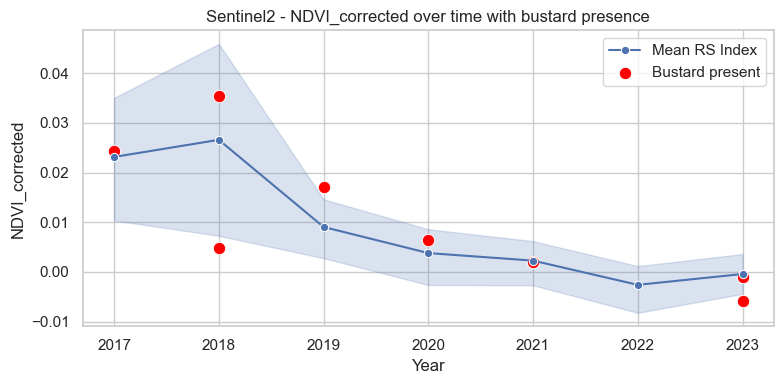

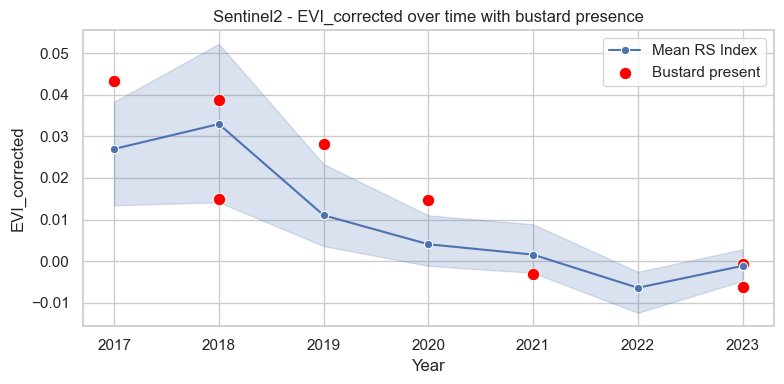

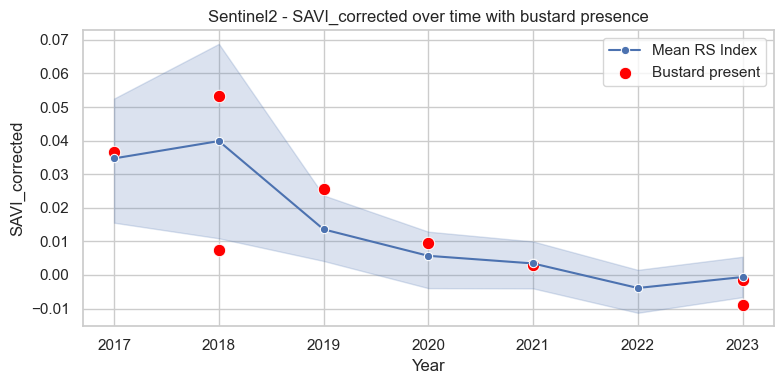

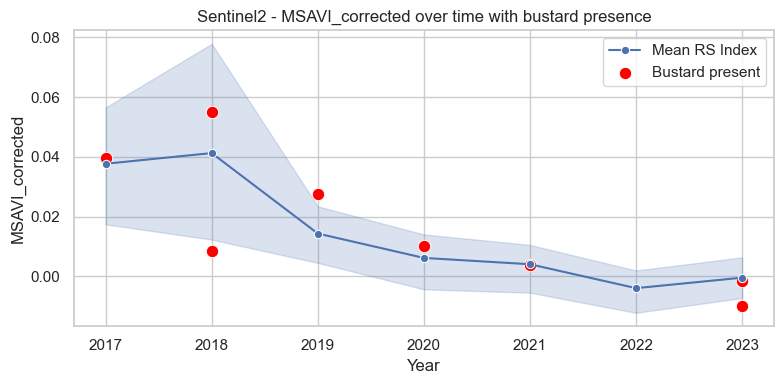

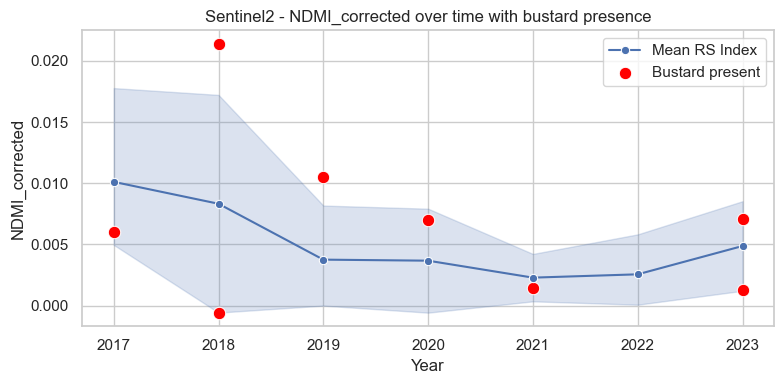

...

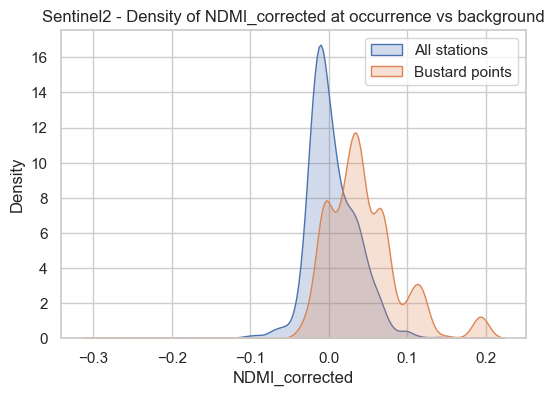

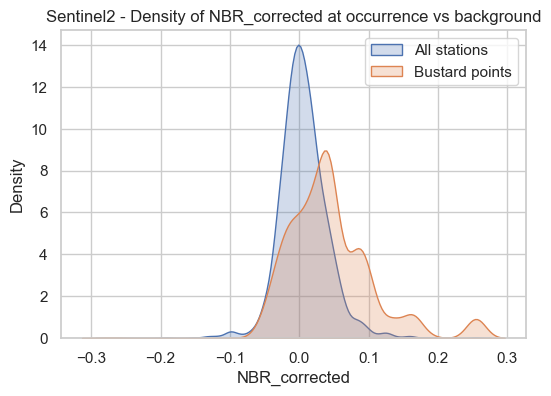

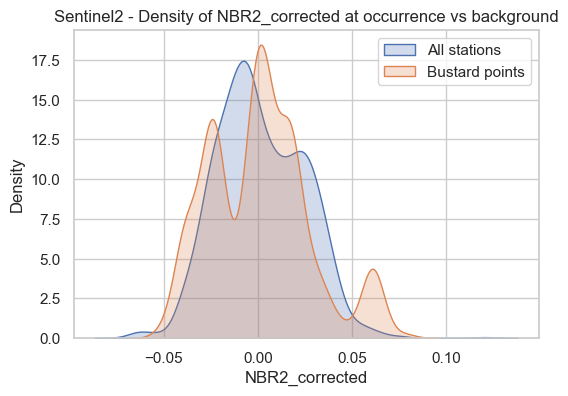

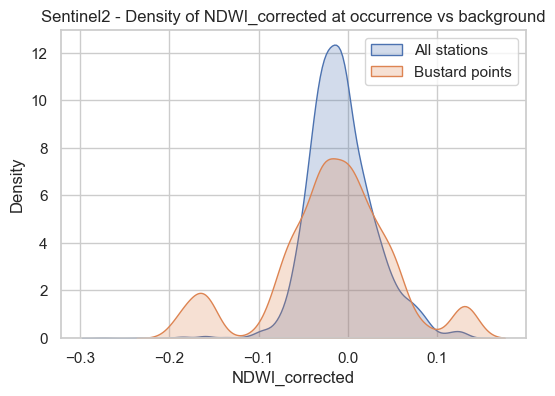

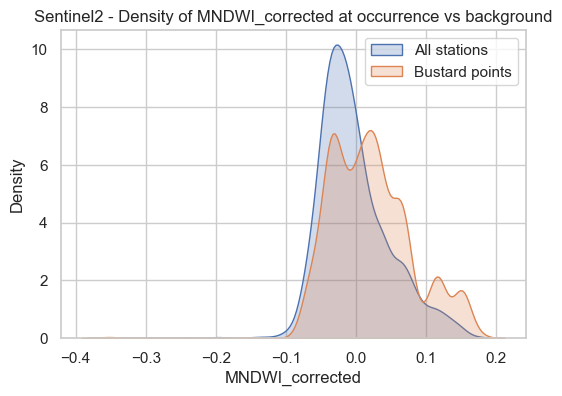

Sentinel2 - NDVI_corrected_lag1 vs presence: Spearman r=0.098, p=0.619
Sentinel2 - NDVI_corrected_lag2 vs presence: Spearman r=0.155, p=0.431
Sentinel2 - NDVI_corrected_lag3 vs presence: Spearman r=-0.088, p=0.655
Sentinel2 - EVI_corrected_lag1 vs presence: Spearman r=0.095, p=0.631
Sentinel2 - EVI_corrected_lag2 vs presence: Spearman r=0.176, p=0.369
Sentinel2 - EVI_corrected_lag3 vs presence: Spearman r=-0.012, p=0.953
Sentinel2 - SAVI_corrected_lag1 vs presence: Spearman r=0.098, p=0.619
Sentinel2 - SAVI_corrected_lag2 vs presence: Spearman r=0.155, p=0.431
Sentinel2 - SAVI_corrected_lag3 vs presence: Spearman r=-0.088, p=0.655
Sentinel2 - MSAVI_corrected_lag1 vs presence: Spearman r=0.098, p=0.619
Sentinel2 - MSAVI_corrected_lag2 vs presence: Spearman r=0.146, p=0.457
Sentinel2 - MSAVI_corrected_lag3 vs presence: Spearman r=-0.088, p=0.655
Sentinel2 - NDMI_corrected_lag1 vs presence: Spearman r=0.009, p=0.964
Sentinel2 - NDMI_corrected_lag2 vs presence: Spearman r=0.006, p=0.974
Se

,min,max,median
NDVI_corrected,-0.052454,0.234140,0.018687
EVI_corrected,-0.062757,0.371814,0.028072
SAVI_corrected,-0.078676,0.351186,0.028029
MSAVI_corrected,-0.091145,0.322740,0.031472
NDMI_corrected,-0.283683,0.193157,0.036356
NBR_corrected,-0.271927,0.254715,0.038384
NBR2_corrected,-0.049614,0.077526,0.000963
NDWI_corrected,-0.191564,0.131018,-0.011057
MNDWI_corrected,-0.352655,0.173759,0.016784


Sentinel2 - NDVI_corrected anomaly vs presence: Spearman r=0.116, p=0.556
Sentinel2 - EVI_corrected anomaly vs presence: Spearman r=0.268, p=0.167
Sentinel2 - SAVI_corrected anomaly vs presence: Spearman r=0.116, p=0.556
Sentinel2 - MSAVI_corrected anomaly vs presence: Spearman r=0.116, p=0.556
Sentinel2 - NDMI_corrected anomaly vs presence: Spearman r=0.175, p=0.372
Sentinel2 - NBR_corrected anomaly vs presence: Spearman r=0.033, p=0.867
Sentinel2 - NBR2_corrected anomaly vs presence: Spearman r=-0.106, p=0.591
Sentinel2 - NDWI_corrected anomaly vs presence: Spearman r=0.100, p=0.612
Sentinel2 - MNDWI_corrected anomaly vs presence: Spearman r=0.164, p=0.403

=== Satellite: MOD09A1 ===
MOD09A1 - NDVI_corrected peak season: Winter (avg=0.001)
MOD09A1 - EVI_corrected peak season: Spring (avg=0.001)
MOD09A1 - SAVI_corrected peak season: Spring (avg=0.001)
MOD09A1 - MSAVI_corrected peak season: Spring (avg=0.002)
MOD09A1 - NDMI_corrected peak season: Spring (avg=0.002)
MOD09A1 - NBR_correc

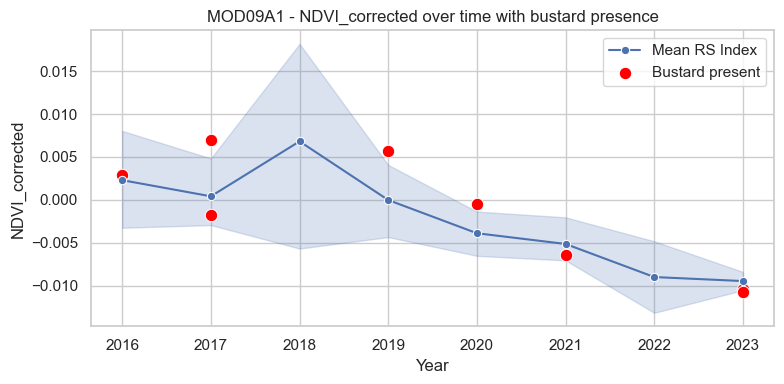

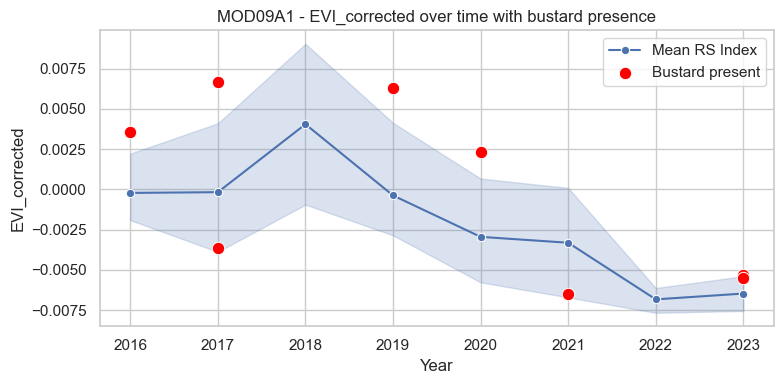

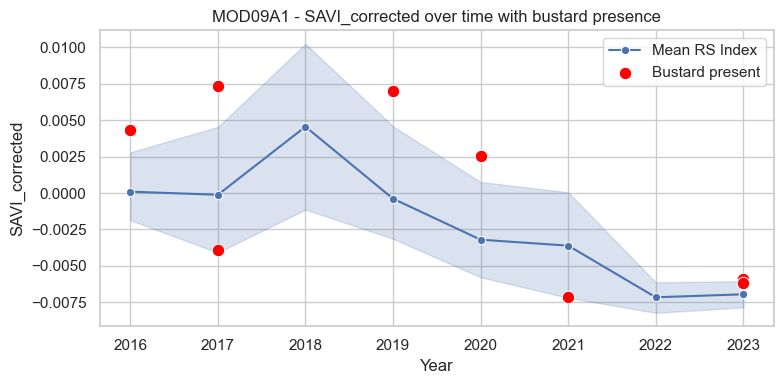

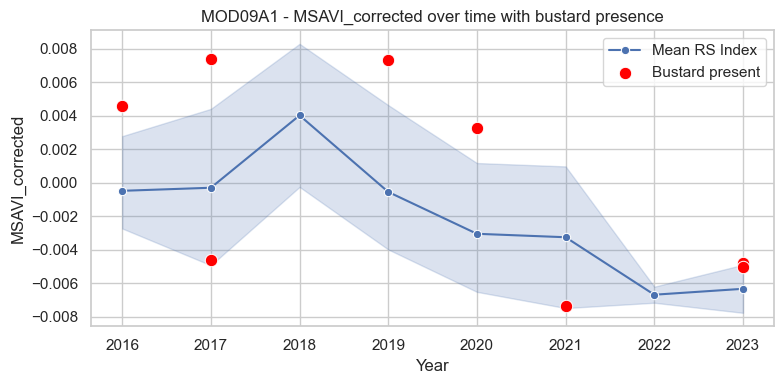

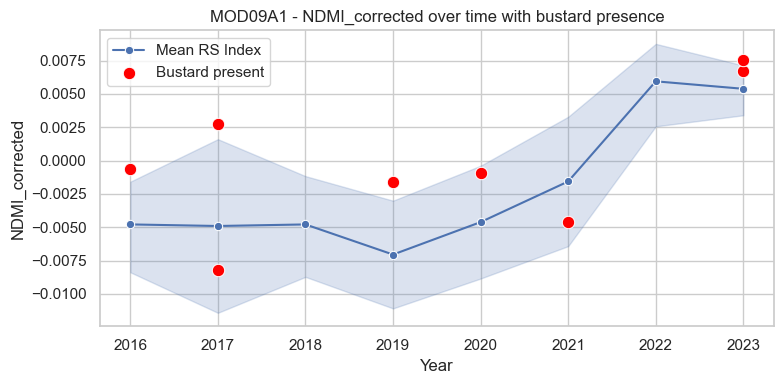

...

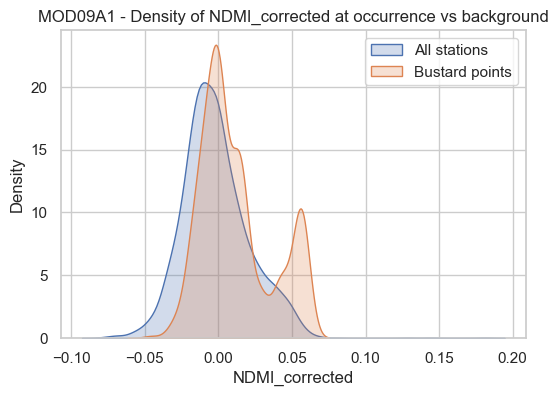

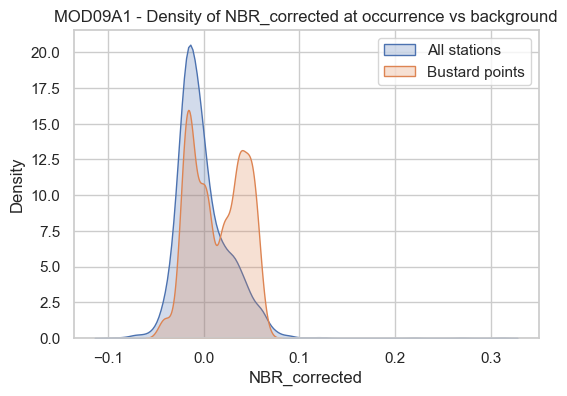

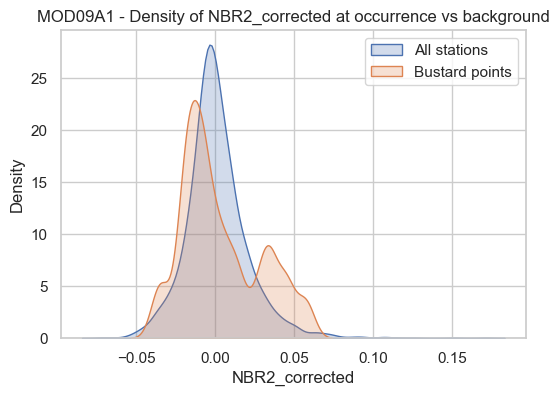

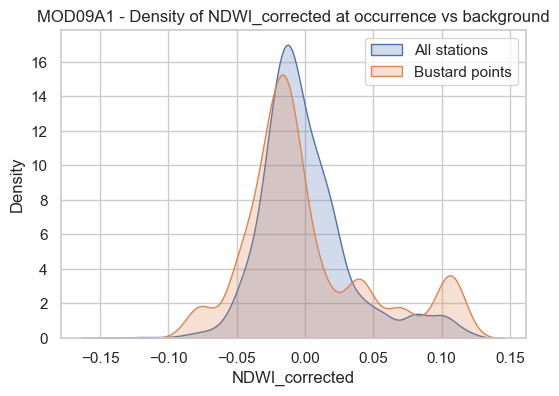

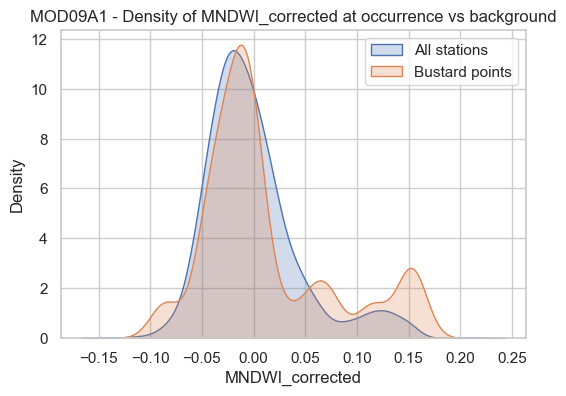

MOD09A1 - NDVI_corrected_lag1 vs presence: Spearman r=0.192, p=0.293
MOD09A1 - NDVI_corrected_lag2 vs presence: Spearman r=0.319, p=0.076
MOD09A1 - NDVI_corrected_lag3 vs presence: Spearman r=-0.228, p=0.210
MOD09A1 - EVI_corrected_lag1 vs presence: Spearman r=0.162, p=0.377
MOD09A1 - EVI_corrected_lag2 vs presence: Spearman r=0.166, p=0.363
MOD09A1 - EVI_corrected_lag3 vs presence: Spearman r=-0.187, p=0.304
MOD09A1 - SAVI_corrected_lag1 vs presence: Spearman r=0.191, p=0.296
MOD09A1 - SAVI_corrected_lag2 vs presence: Spearman r=0.204, p=0.262
MOD09A1 - SAVI_corrected_lag3 vs presence: Spearman r=-0.204, p=0.264
MOD09A1 - MSAVI_corrected_lag1 vs presence: Spearman r=0.137, p=0.455
MOD09A1 - MSAVI_corrected_lag2 vs presence: Spearman r=0.139, p=0.446
MOD09A1 - MSAVI_corrected_lag3 vs presence: Spearman r=-0.193, p=0.290
MOD09A1 - NDMI_corrected_lag1 vs presence: Spearman r=0.036, p=0.843
MOD09A1 - NDMI_corrected_lag2 vs presence: Spearman r=0.066, p=0.721
MOD09A1 - NDMI_corrected_lag3 

,min,max,median
NDVI_corrected,-0.061169,0.056649,0.003877
EVI_corrected,-0.047348,0.040313,0.006351
SAVI_corrected,-0.058106,0.044616,0.009784
MSAVI_corrected,-0.058627,0.041739,0.010453
NDMI_corrected,-0.045651,0.059100,0.002201
NBR_corrected,-0.042275,0.063163,0.012126
NBR2_corrected,-0.036704,0.057096,-0.006184
NDWI_corrected,-0.076891,0.109125,-0.012413
MNDWI_corrected,-0.086557,0.154841,-0.006938


MOD09A1 - NDVI_corrected anomaly vs presence: Spearman r=0.139, p=0.449
MOD09A1 - EVI_corrected anomaly vs presence: Spearman r=0.230, p=0.206
MOD09A1 - SAVI_corrected anomaly vs presence: Spearman r=0.208, p=0.253
MOD09A1 - MSAVI_corrected anomaly vs presence: Spearman r=0.253, p=0.162
MOD09A1 - NDMI_corrected anomaly vs presence: Spearman r=0.185, p=0.310
MOD09A1 - NBR_corrected anomaly vs presence: Spearman r=0.246, p=0.174
MOD09A1 - NBR2_corrected anomaly vs presence: Spearman r=-0.009, p=0.959
MOD09A1 - NDWI_corrected anomaly vs presence: Spearman r=0.010, p=0.955
MOD09A1 - MNDWI_corrected anomaly vs presence: Spearman r=0.087, p=0.638

=== Satellite: MOD13Q1 ===
MOD13Q1 - NDVI_corrected peak season: Winter (avg=0.001)
MOD13Q1 - EVI_corrected peak season: Spring (avg=0.001)


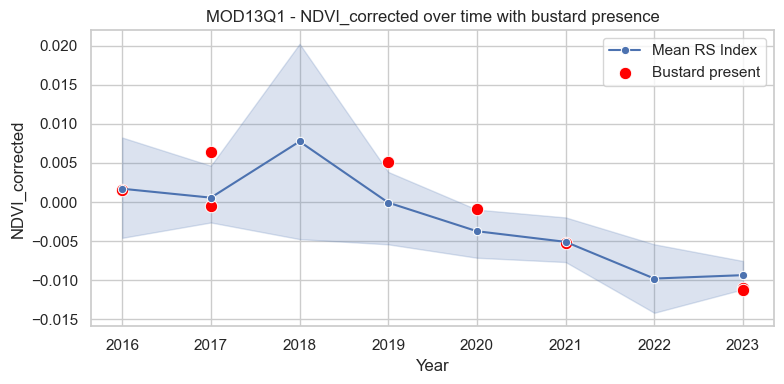

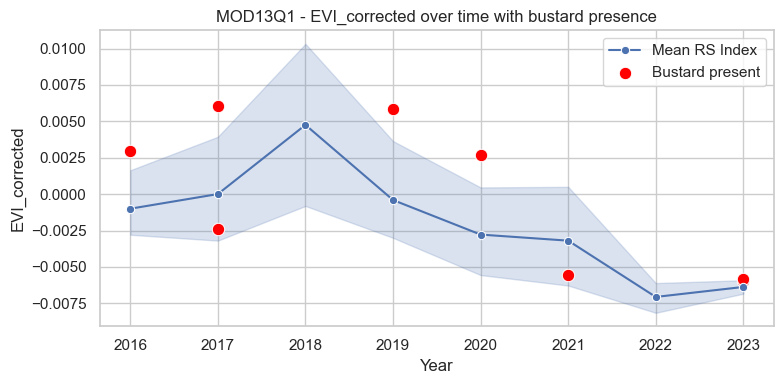

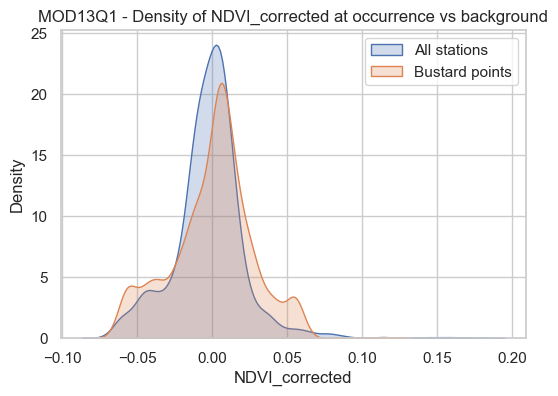

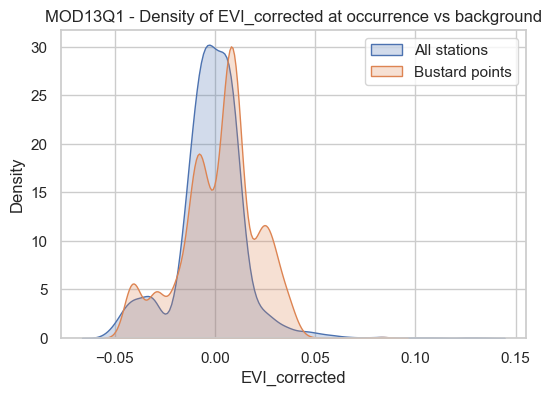

MOD13Q1 - NDVI_corrected_lag1 vs presence: Spearman r=0.161, p=0.380
MOD13Q1 - NDVI_corrected_lag2 vs presence: Spearman r=0.344, p=0.054
MOD13Q1 - NDVI_corrected_lag3 vs presence: Spearman r=-0.270, p=0.135
MOD13Q1 - EVI_corrected_lag1 vs presence: Spearman r=0.133, p=0.470
MOD13Q1 - EVI_corrected_lag2 vs presence: Spearman r=0.208, p=0.253
MOD13Q1 - EVI_corrected_lag3 vs presence: Spearman r=-0.265, p=0.143
MOD13Q1 - NDVI_corrected occurrence range: min=-0.061, max=0.115, median=0.004
MOD13Q1 - EVI_corrected occurrence range: min=-0.042, max=0.084, median=0.005


,min,max,median
NDVI_corrected,-0.060788,0.114567,0.003945
EVI_corrected,-0.042410,0.083541,0.004957


MOD13Q1 - NDVI_corrected anomaly vs presence: Spearman r=0.144, p=0.433
MOD13Q1 - EVI_corrected anomaly vs presence: Spearman r=0.281, p=0.120


In [232]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# --- Parameters ---
season_order = ['Spring','Summer','Fall','Winter']
season_middays = {'Spring':'05-05','Summer':'06-20','Fall':'10-20','Winter':'12-10'}
max_lag = 3  # number of seasons to test lag effects

# Loop over satellites
for sat, station_df in zip(names, station_gdfs):
    print(f"\n=== Satellite: {sat} ===")

    df = station_df.copy()
    
    # Adjust RS indices for satellite
    if sat == 'MOD13Q1':
        rs_idx = [col for col in df.columns if col in ['NDVI_corrected','EVI_corrected']]
    else:
        rs_idx = [col for col in df.columns if col.endswith('_corrected')]
    
    # Initialize presence column
    occ_df = occ_with_stations.get(sat)
    df['presence'] = 0
    if occ_df is not None and 'nearest_idx' in occ_df.columns:
        df.loc[occ_df['nearest_idx'], 'presence'] = 1

    # --- Step 1: Convert seasons to ordered categorical ---
    df['Season'] = pd.Categorical(df['Season'], categories=season_order, ordered=True)
    
    # --- Step 2: Seasonal aggregation ---
    seasonal_df = df.groupby(['Year','Season'])[rs_idx + ['presence']].mean().reset_index()
    seasonal_df_sorted = seasonal_df.sort_values(['Year','Season'])
    
    # --- Step 3: Peak vegetation season detection ---
    peak_seasons = {}
    for idx in rs_idx:
        peak_df = seasonal_df.groupby('Season')[idx].mean()
        peak_season = peak_df.idxmax()
        peak_seasons[idx] = peak_season
        print(f"{sat} - {idx} peak season: {peak_season} (avg={peak_df.max():.3f})")
    
    # --- Step 4: Lagged RS values ---
    for idx in rs_idx:
        for lag in range(1, max_lag+1):
            seasonal_df_sorted[f'{idx}_lag{lag}'] = seasonal_df_sorted[idx].shift(lag)
    
    # --- Step 5: RS anomalies ---
    for idx in rs_idx:
        seasonal_df_sorted[f'{idx}_anom'] = (seasonal_df_sorted[idx] - seasonal_df_sorted[idx].mean()) / seasonal_df_sorted[idx].std()
    
    # --- Step 6: Time series plots with presence ---
    for idx in rs_idx:
        plt.figure(figsize=(8,4))
        sns.lineplot(data=seasonal_df_sorted, x='Year', y=idx, marker='o', label='Mean RS Index')
        sns.scatterplot(data=seasonal_df_sorted[seasonal_df_sorted['presence']>0],
                        x='Year', y=idx, color='red', s=80, label='Bustard present')
        plt.title(f'{sat} - {idx} over time with bustard presence')
        plt.ylabel(idx)
        plt.legend()
        plt.tight_layout()
        plt.show()
    
    # --- Step 7: Density plots for occurrence vs background ---
    for idx in rs_idx:
        plt.figure(figsize=(6,4))
        sns.kdeplot(df[idx], label='All stations', fill=True)
        if occ_df is not None and 'nearest_idx' in occ_df.columns:
            sns.kdeplot(df.loc[occ_df['nearest_idx'], idx], label='Bustard points', fill=True)
        plt.title(f'{sat} - Density of {idx} at occurrence vs background')
        plt.xlabel(idx)
        plt.ylabel('Density')
        plt.legend()
        plt.show()
    
    # --- Step 8: Cross-correlation with lagged RS indices ---
    for idx in rs_idx:
        for lag in range(1, max_lag+1):
            corr, pval = spearmanr(seasonal_df_sorted[f'{idx}_lag{lag}'].fillna(0),
                                   seasonal_df_sorted['presence'])
            print(f"{sat} - {idx}_lag{lag} vs presence: Spearman r={corr:.3f}, p={pval:.3f}")
    
    # --- Step 9: Threshold / preferred RS ranges for occurrence ---
    thresholds = {}
    for idx in rs_idx:
        if occ_df is not None and 'nearest_idx' in occ_df.columns:
            values = df.loc[occ_df['nearest_idx'], idx].dropna()
            thresholds[idx] = (values.min(), values.max(), values.median())
            print(f"{sat} - {idx} occurrence range: min={values.min():.3f}, max={values.max():.3f}, median={values.median():.3f}")
    
    # Optional: summarize in DataFrame
    thresh_df = pd.DataFrame.from_dict(thresholds, orient='index', columns=['min','max','median'])
    display(thresh_df)
    
    # --- Step 10: Optional: correlation between anomalies and presence ---
    for idx in rs_idx:
        corr, pval = spearmanr(seasonal_df_sorted[f'{idx}_anom'].fillna(0),
                               seasonal_df_sorted['presence'])
        print(f"{sat} - {idx} anomaly vs presence: Spearman r={corr:.3f}, p={pval:.3f}")



=== Satellite: Landsat ===

Habitat occurrence summary:
                Habitat  sum  count  presence_ratio
0  Alluvial spread area   23    709        0.032440
1                 Gully    7    280        0.025000
2     Macrochloa steppe   11    449        0.024499
3                   Reg   35   1594        0.021957
4          Salty steppe    4    140        0.028571
5                  Wadi    5    128        0.039062


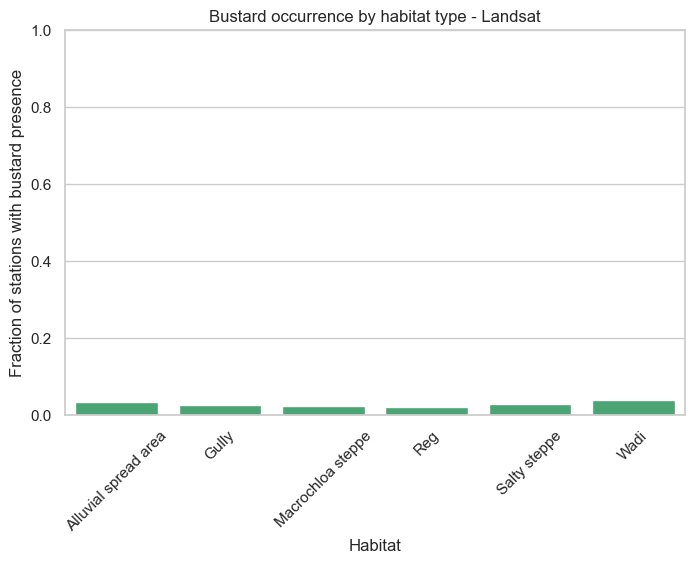

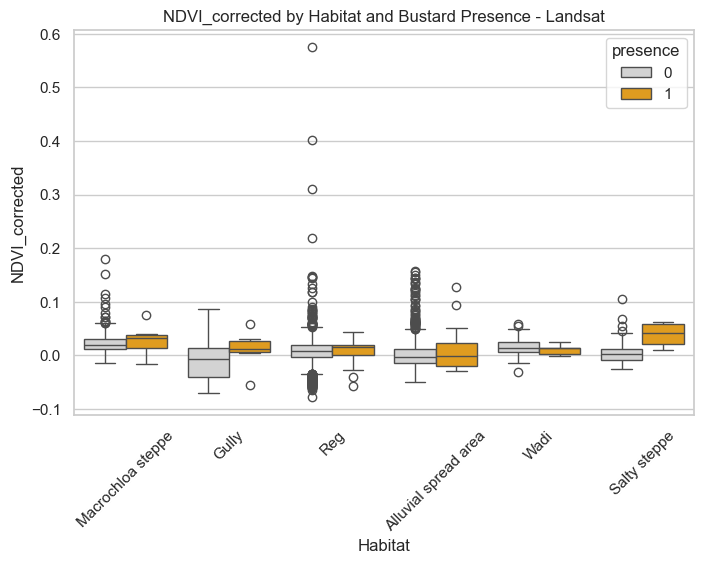

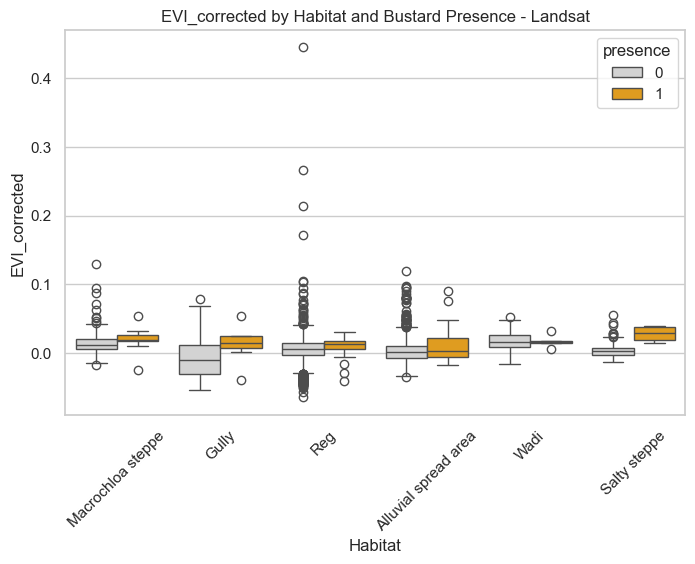

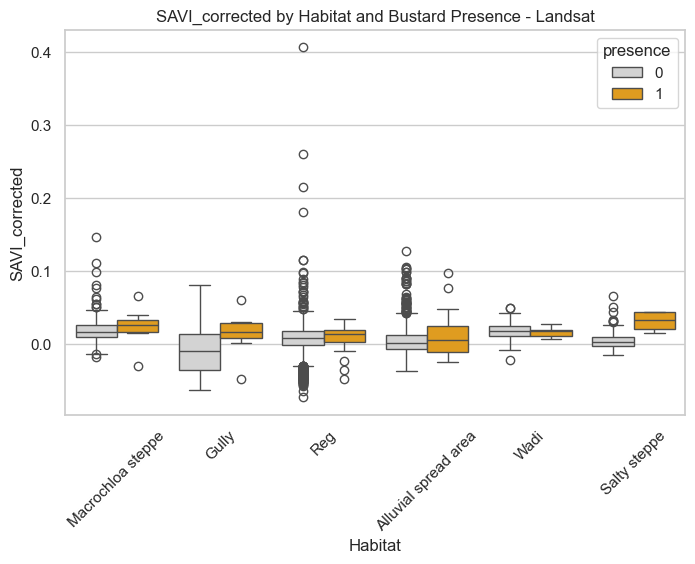

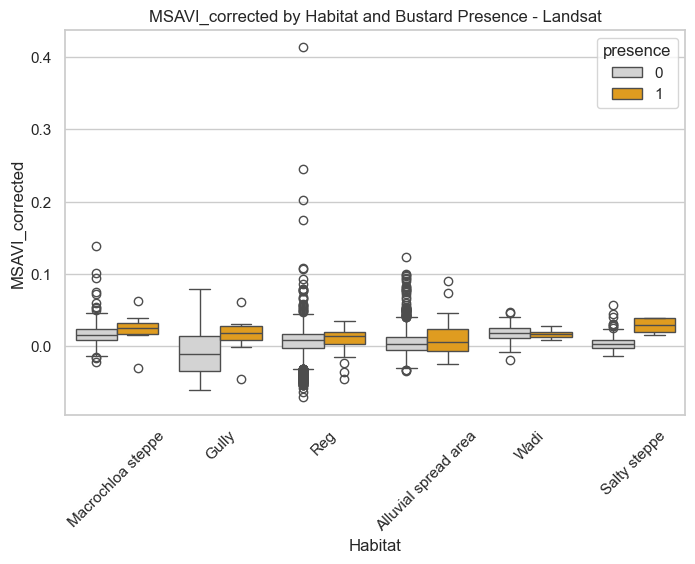

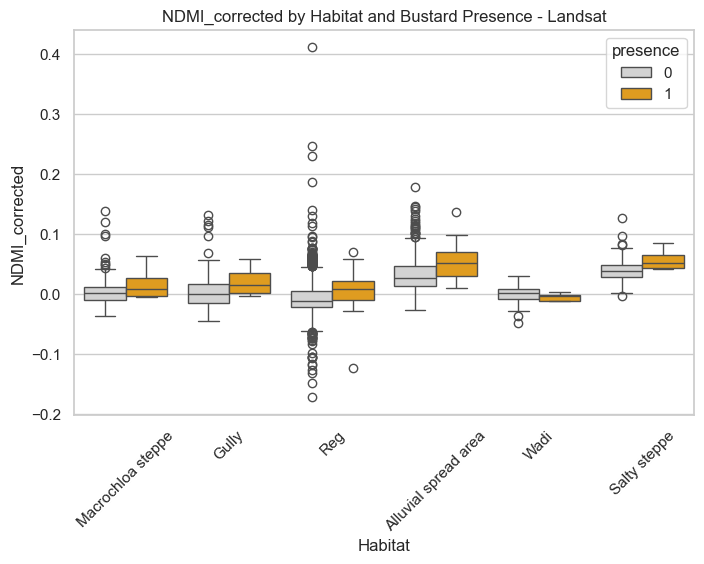

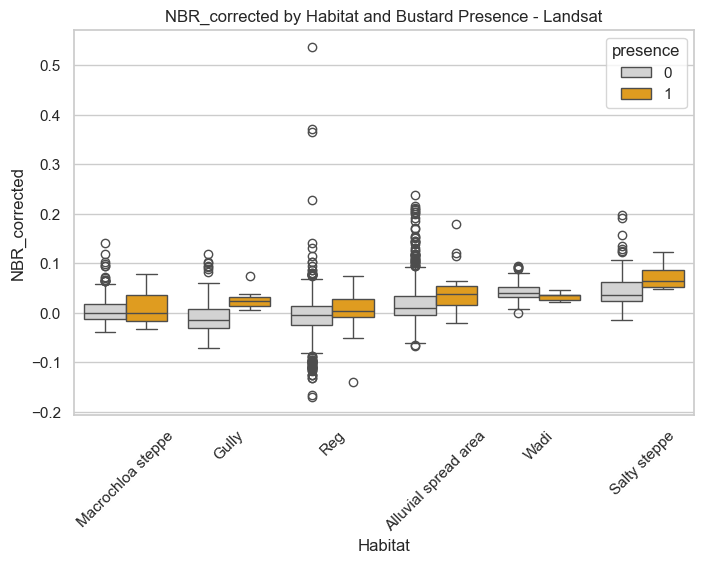

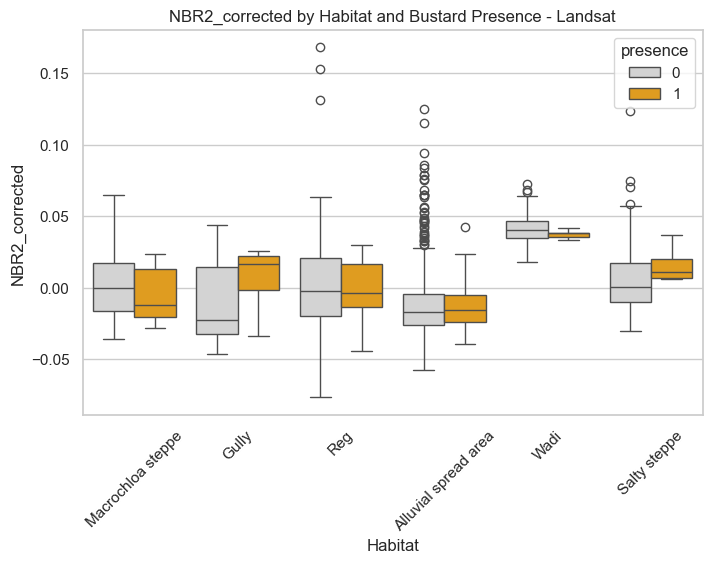

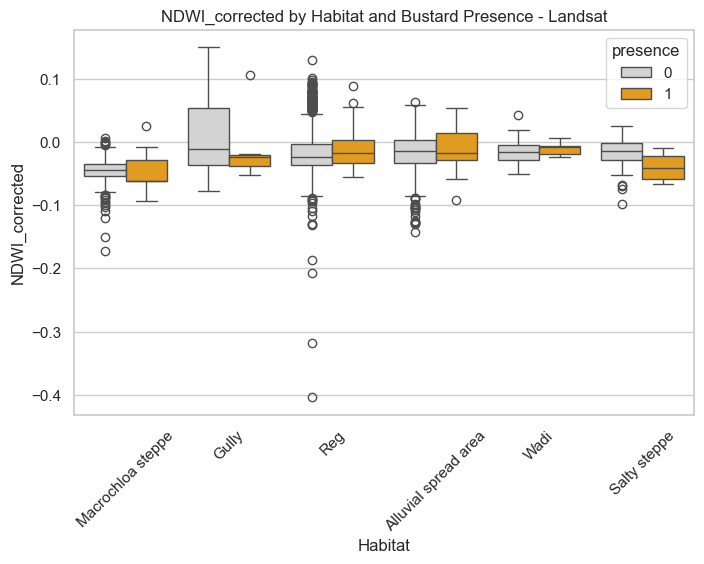

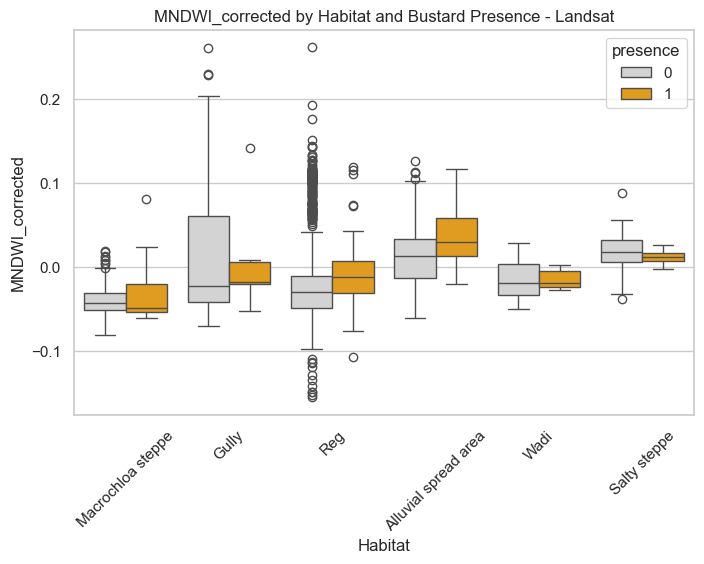


Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       965
           1       0.67      0.08      0.14        25

    accuracy                           0.98       990
   macro avg       0.82      0.54      0.57       990
weighted avg       0.97      0.98      0.97       990

ROC-AUC: 0.900

Top 10 feature importance:
            Feature  Importance
2              Year    0.233476
5            Ground    0.124998
7   Sum.not.unknown    0.080734
8          GridSize    0.065049
21  MNDWI_corrected    0.040050
18    NBR_corrected    0.039971
14    EVI_corrected    0.036734
17   NDMI_corrected    0.032877
1               Lon    0.032755
19   NBR2_corrected    0.030859


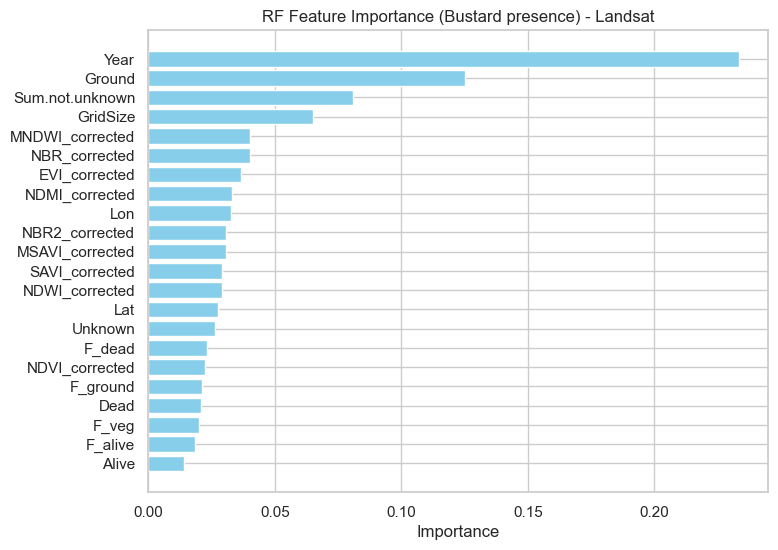


=== Satellite: Sentinel2 ===

Habitat occurrence summary:
                Habitat  sum  count  presence_ratio
0  Alluvial spread area   22    533        0.041276
1                 Gully    6    213        0.028169
2     Macrochloa steppe   11    341        0.032258
3                   Reg   35   1211        0.028902
4          Salty steppe    4    105        0.038095
5                  Wadi    5    107        0.046729


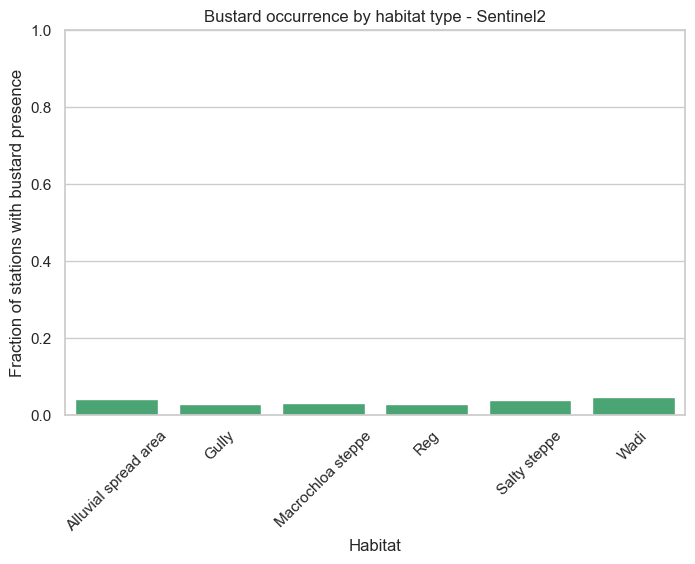

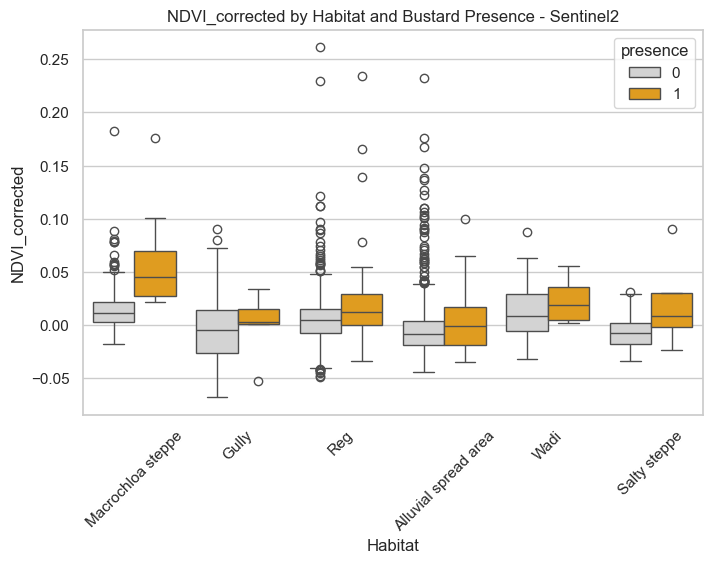

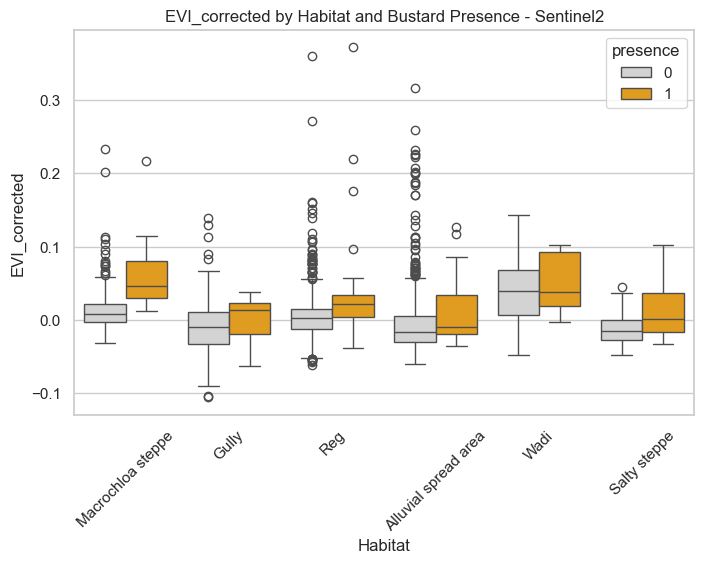

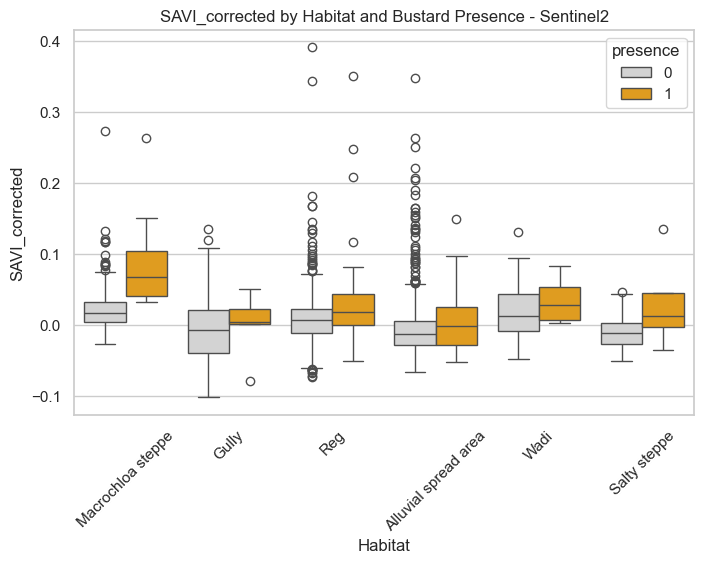

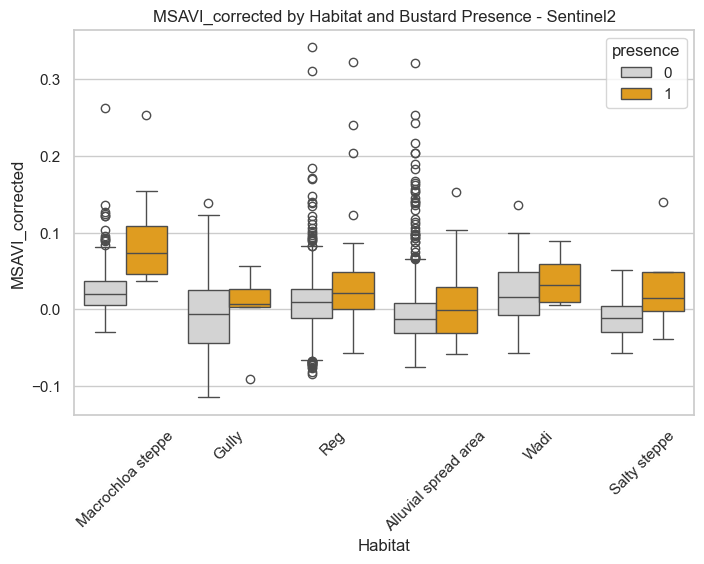

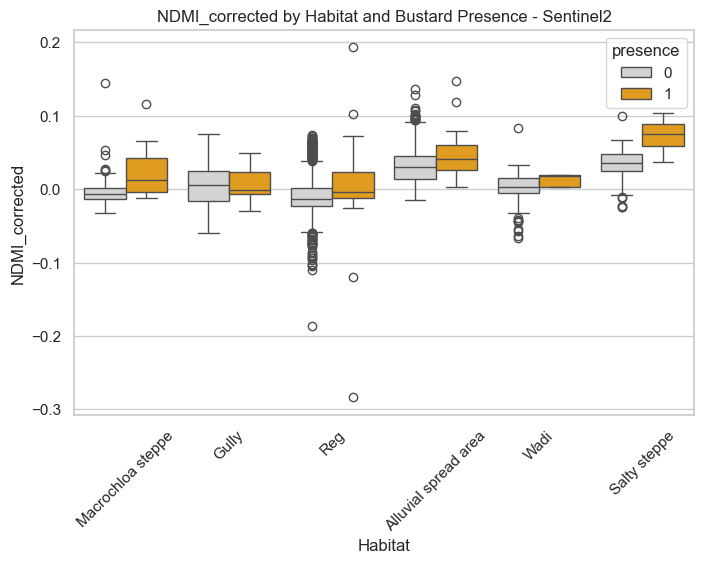

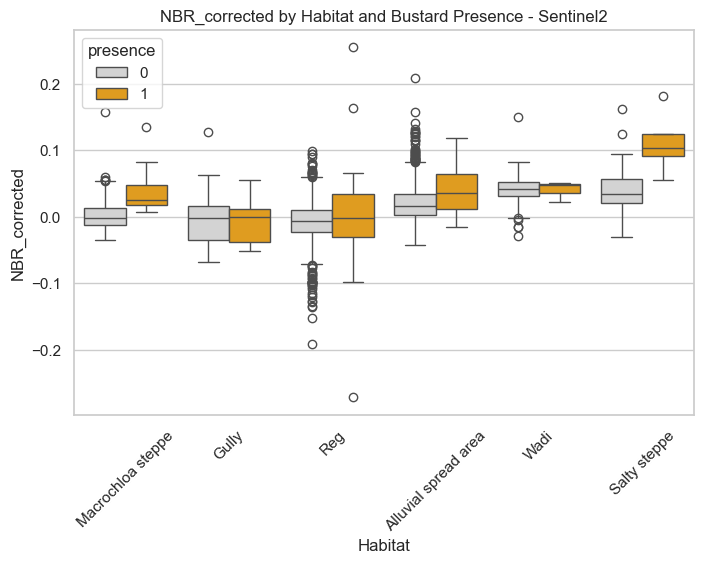

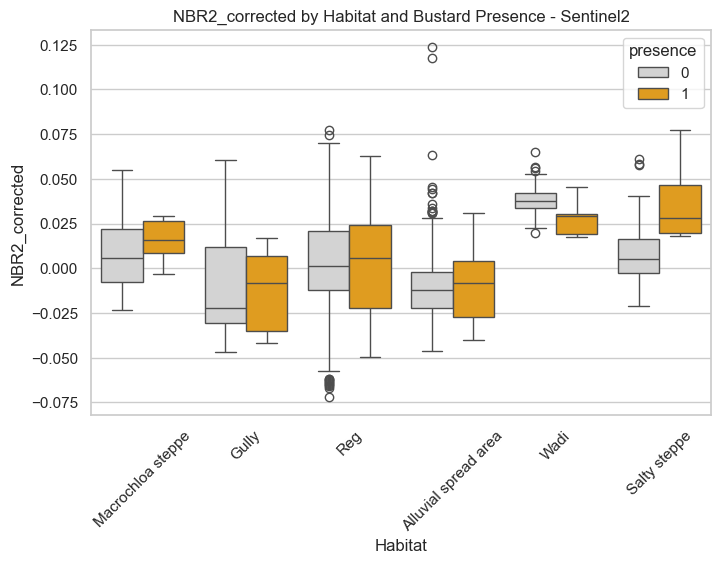

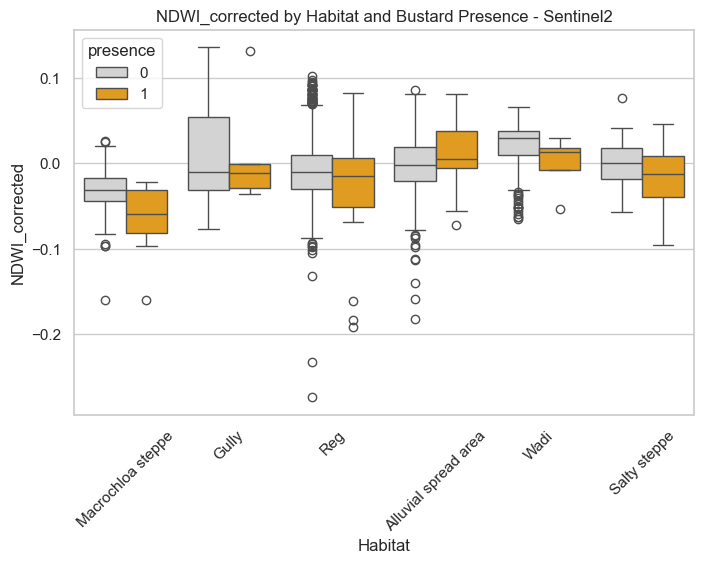

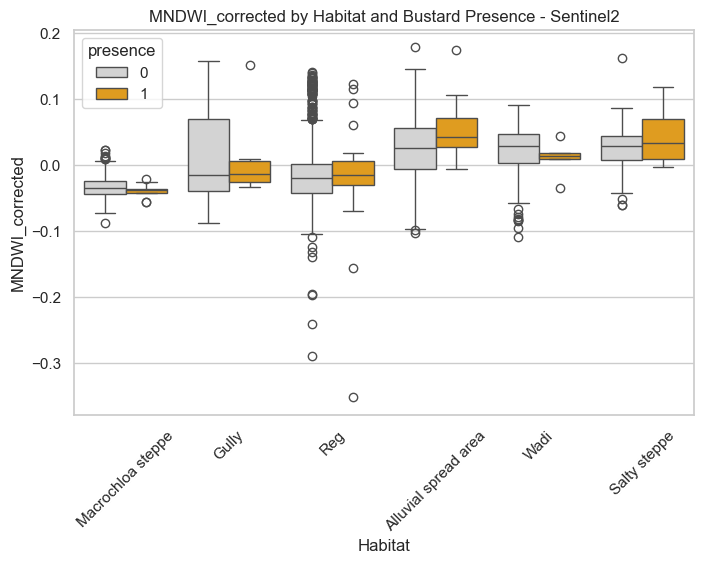


Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       728
           1       1.00      0.04      0.08        25

    accuracy                           0.97       753
   macro avg       0.98      0.52      0.53       753
weighted avg       0.97      0.97      0.95       753

ROC-AUC: 0.972

Top 10 feature importance:
            Feature  Importance
2              Year    0.387758
9           F_alive    0.073509
3             Alive    0.061060
14    EVI_corrected    0.042095
10           F_dead    0.034140
17   NDMI_corrected    0.033828
18    NBR_corrected    0.033226
16  MSAVI_corrected    0.029231
0               Lat    0.029143
4              Dead    0.028155


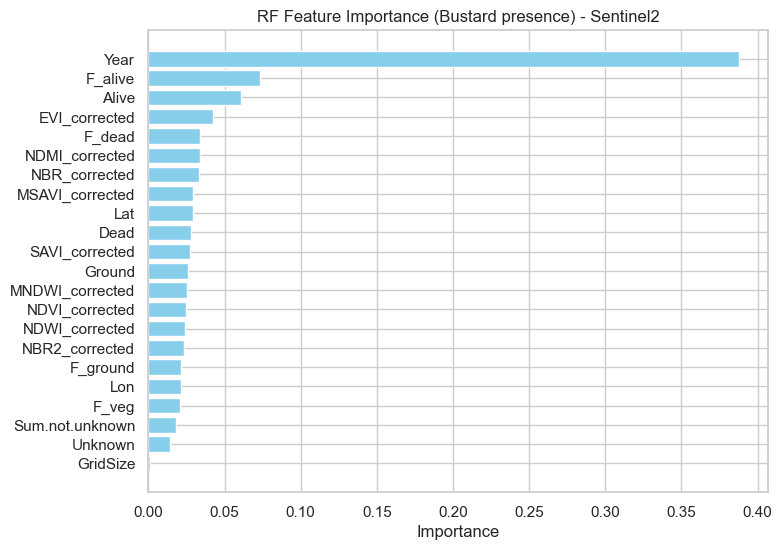


=== Satellite: MOD09A1 ===

Habitat occurrence summary:
                Habitat  sum  count  presence_ratio
0  Alluvial spread area   23    744        0.030914
1                 Gully    7    292        0.023973
2     Macrochloa steppe   11    480        0.022917
3                   Reg   35   1740        0.020115
4          Salty steppe    4    140        0.028571
5                  Wadi    5    140        0.035714


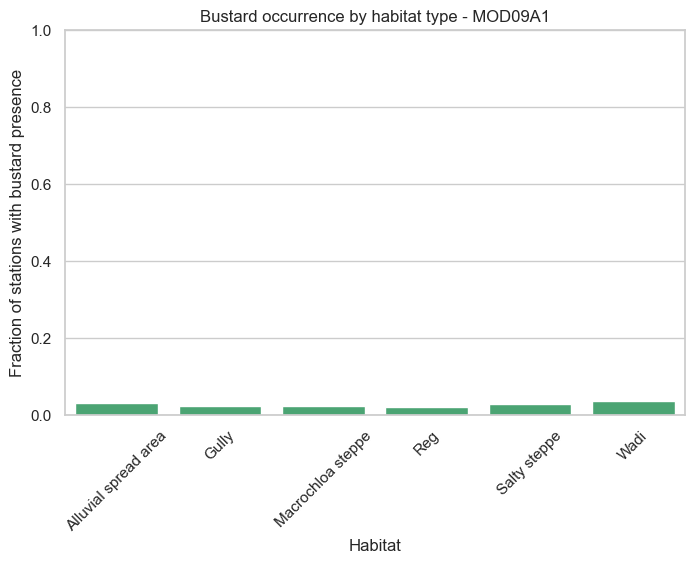

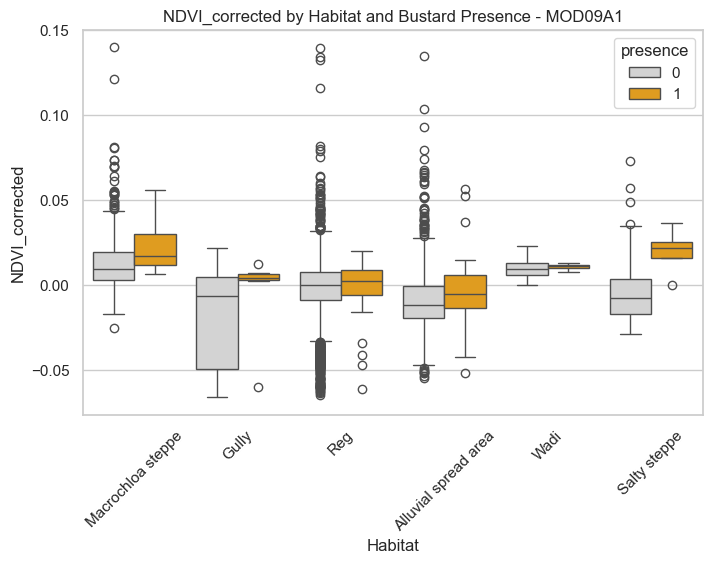

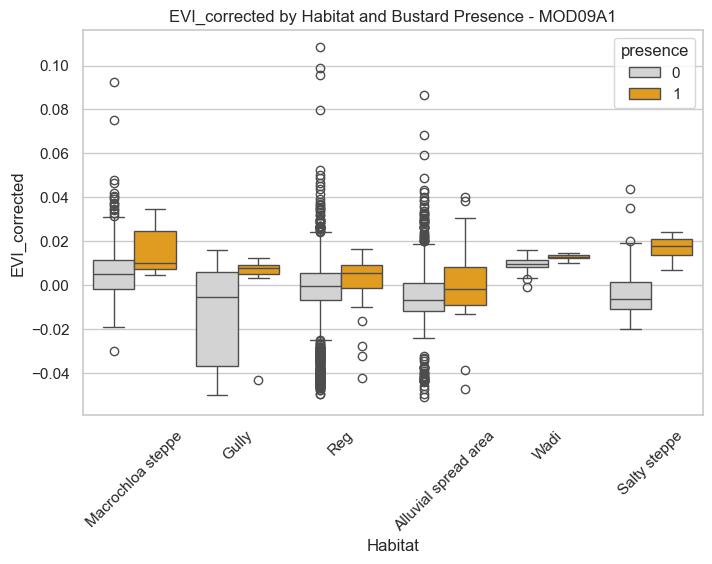

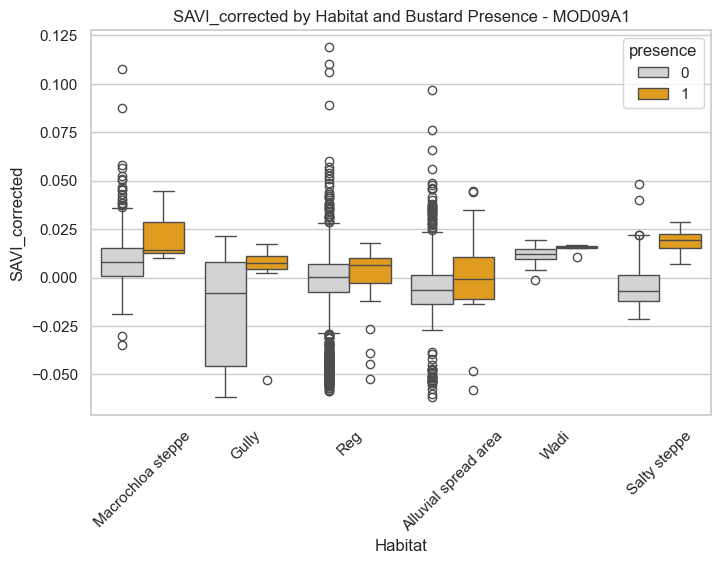

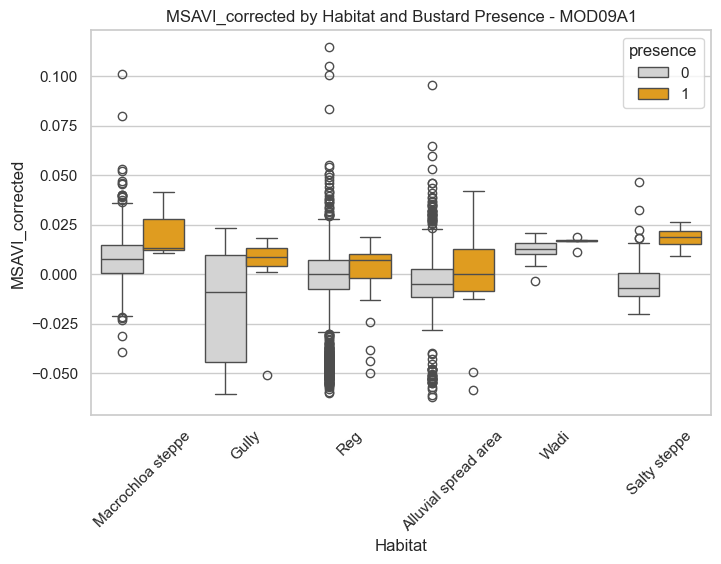

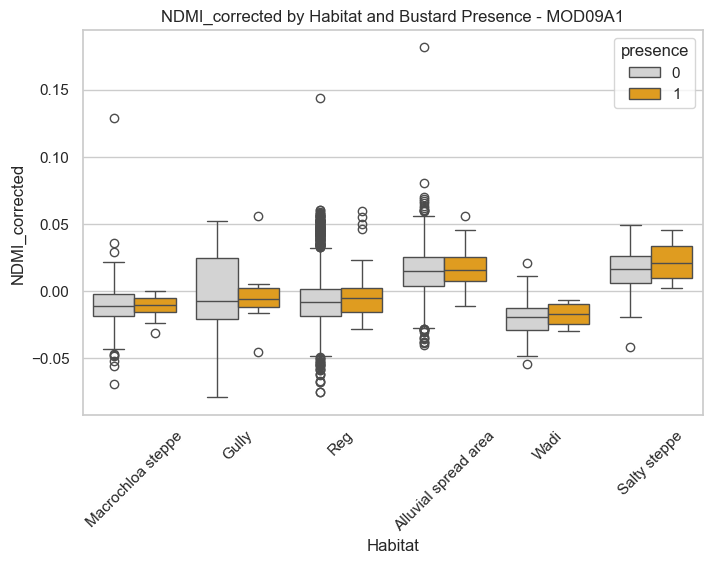

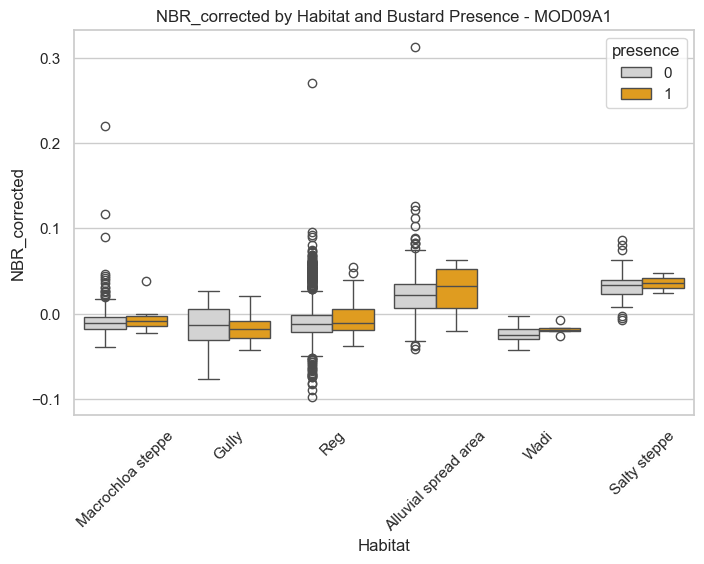

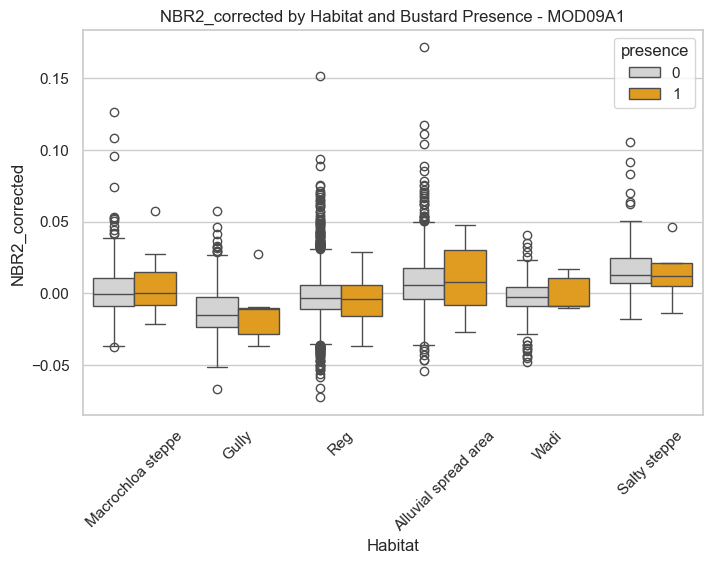

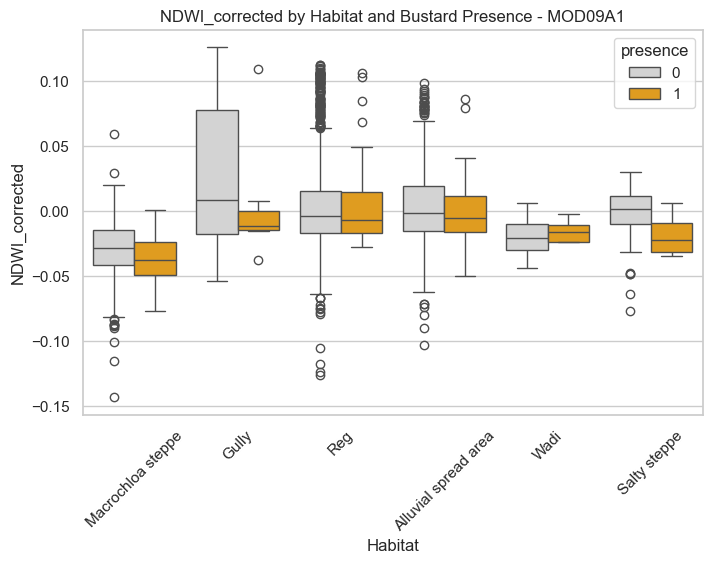

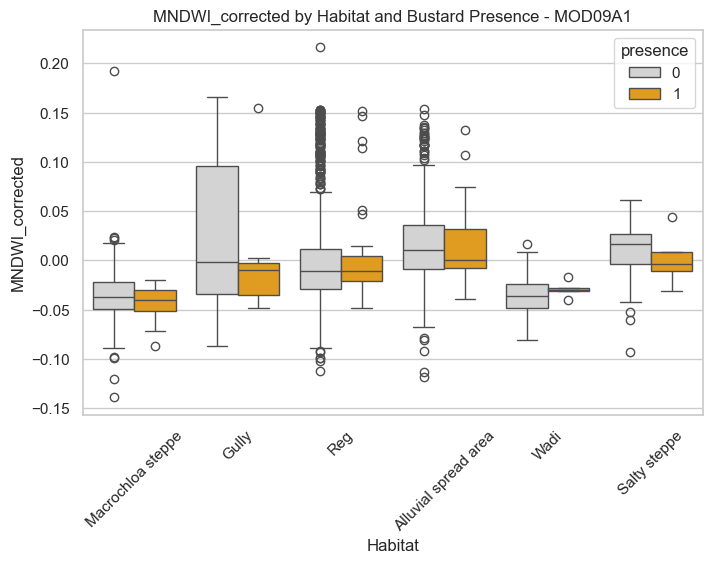


Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1035
           1       0.25      0.04      0.07        26

    accuracy                           0.97      1061
   macro avg       0.61      0.52      0.53      1061
weighted avg       0.96      0.97      0.96      1061

ROC-AUC: 0.888

Top 10 feature importance:
            Feature  Importance
2              Year    0.184594
5            Ground    0.132952
7   Sum.not.unknown    0.113306
8          GridSize    0.082378
16  MSAVI_corrected    0.039140
14    EVI_corrected    0.035466
15   SAVI_corrected    0.033910
17   NDMI_corrected    0.033887
6           Unknown    0.030526
21  MNDWI_corrected    0.029975


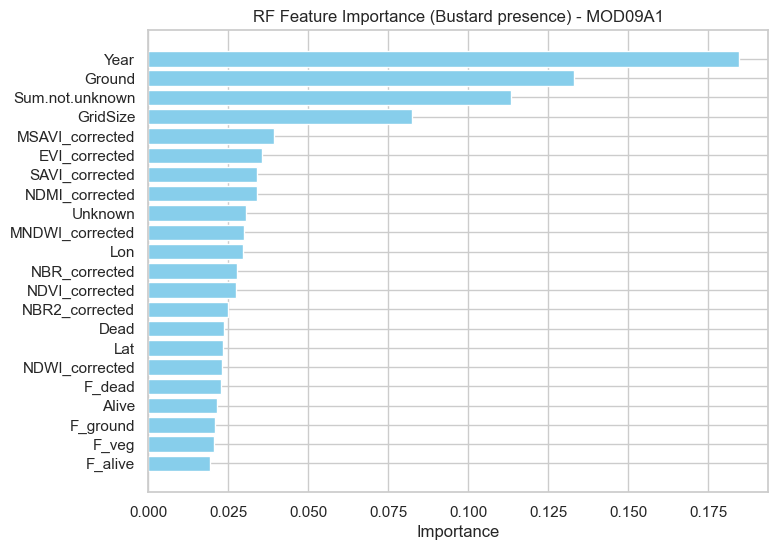


=== Satellite: MOD13Q1 ===

Habitat occurrence summary:
                Habitat  sum  count  presence_ratio
0  Alluvial spread area   23    744        0.030914
1                 Gully    7    292        0.023973
2     Macrochloa steppe   11    480        0.022917
3                   Reg   35   1740        0.020115
4          Salty steppe    4    140        0.028571
5                  Wadi    5    140        0.035714


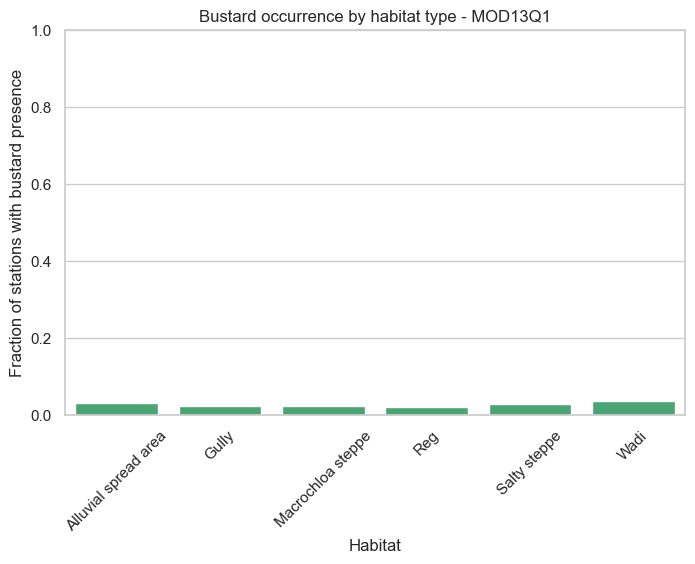

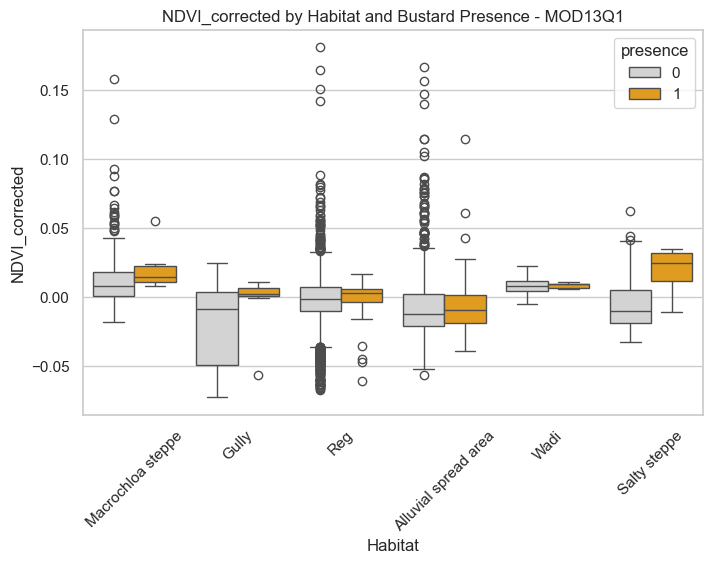

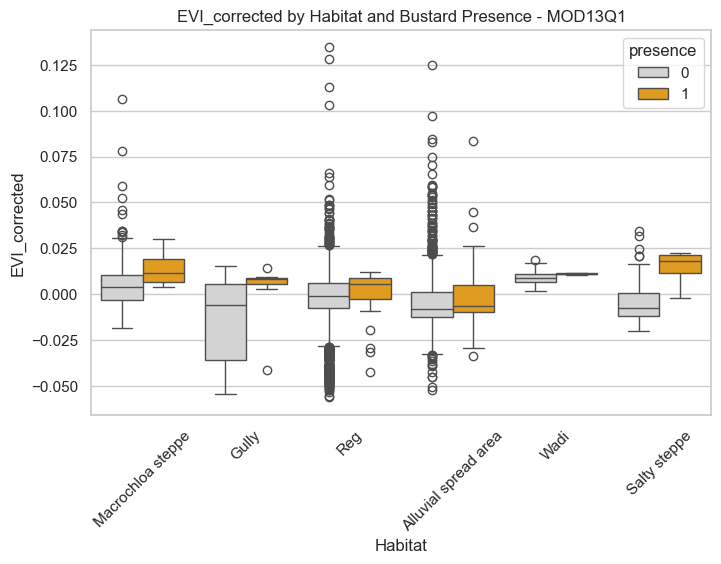


Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1035
           1       0.33      0.04      0.07        26

    accuracy                           0.97      1061
   macro avg       0.65      0.52      0.53      1061
weighted avg       0.96      0.97      0.96      1061

ROC-AUC: 0.859

Top 10 feature importance:
            Feature  Importance
2              Year    0.202178
7   Sum.not.unknown    0.132786
5            Ground    0.118960
8          GridSize    0.093892
14    EVI_corrected    0.057974
6           Unknown    0.051429
13   NDVI_corrected    0.047086
1               Lon    0.042884
0               Lat    0.042318
10           F_dead    0.039096


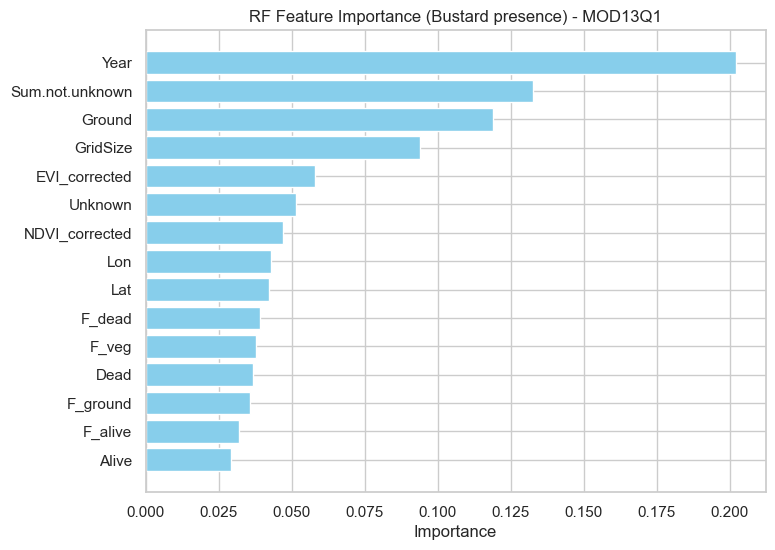

In [236]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

# --- Inputs ---
# names: list of satellite names
# station_gdfs: list of station GeoDataFrames with 'Habitat' and RS indices
# occ_with_stations: dict with satellite keys containing occurrence points with 'nearest_idx'
# rs_indices_list: dict with satellite as key and list of available RS indices

for sat, station_df in zip(names, station_gdfs):
    print(f"\n=== Satellite: {sat} ===")
    df = station_df.copy()
    
    # --- Step 0: Assign presence based on nearest occurrence ---
    df['presence'] = 0
    occ_df = occ_with_stations.get(sat)
    if occ_df is not None and 'nearest_idx' in occ_df.columns:
        df.loc[occ_df['nearest_idx'], 'presence'] = 1
    else:
        print(f"No occurrence data or 'nearest_idx' for {sat}, skipping.")
        continue

    # --- Step 1: Summarize presence by habitat ---
    habitat_summary = (
        df.groupby('Habitat')['presence']
        .agg(['sum','count'])
        .reset_index()
    )
    habitat_summary['presence_ratio'] = habitat_summary['sum'] / habitat_summary['count']
    print("\nHabitat occurrence summary:")
    print(habitat_summary)

    # --- Step 2: Plot presence ratio by habitat ---
    plt.figure(figsize=(8,5))
    sns.barplot(x='Habitat', y='presence_ratio', data=habitat_summary, color='mediumseagreen')
    plt.ylabel('Fraction of stations with bustard presence')
    plt.title(f'Bustard occurrence by habitat type - {sat}')
    plt.xticks(rotation=45)
    plt.ylim(0,1)
    plt.show()

    # --- Step 3: Boxplots of RS indices by habitat and presence ---
    rs_indices = rs_indices_list.get(sat, [])
    available_indices = [idx for idx in rs_indices if idx in df.columns]
    
    for idx in available_indices:
        plt.figure(figsize=(8,5))
        sns.boxplot(
            x='Habitat', y=idx, hue='presence', data=df,
            palette={0:'lightgray', 1:'orange'}
        )
        plt.title(f'{idx} by Habitat and Bustard Presence - {sat}')
        plt.xticks(rotation=45)
        plt.show()
    
    # --- Step 4: Random Forest with RS indices + Habitat ---
    if len(available_indices) == 0 or df['presence'].sum() == 0:
        print(f"No RS indices or presence points for RF modeling on {sat}, skipping RF.")
        continue
    
    df_rf = df.copy()
    df_rf = pd.get_dummies(df_rf, columns=['Habitat'], drop_first=True)
    
    # Use only numeric columns for RF
    feature_cols = [c for c in df_rf.columns if c not in ['Station','presence']]
    X = df_rf[feature_cols].select_dtypes(include=np.number)
    y = df_rf['presence']
    
    # Skip if only one class present
    if y.nunique() < 2:
        print(f"Only one class present for {sat}, skipping RF.")
        continue

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )

    # Random Forest classifier with class imbalance handling
    rf = RandomForestClassifier(n_estimators=500, random_state=42, class_weight='balanced')
    rf.fit(X_train, y_train)

    # Predictions and metrics
    y_pred = rf.predict(X_test)
    y_proba = rf.predict_proba(X_test)[:,1]

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    try:
        auc = roc_auc_score(y_test, y_proba)
        print(f"ROC-AUC: {auc:.3f}")
    except ValueError:
        print("ROC-AUC could not be computed (single class in test set).")

    # Feature importance
    imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_})
    imp_df = imp_df.sort_values('Importance', ascending=False)
    print("\nTop 10 feature importance:")
    print(imp_df.head(10))

    # Plot feature importance
    plt.figure(figsize=(8,6))
    plt.barh(imp_df['Feature'], imp_df['Importance'], color='skyblue')
    plt.gca().invert_yaxis()
    plt.xlabel("Importance")
    plt.title(f"RF Feature Importance (Bustard presence) - {sat}")
    plt.show()
